In [1]:
import pandas as pd
import numpy as np
import glob
import os

from clustering_tools import *

# pd.set_option('display.max_columns', None)
pd.reset_option('display.max_columns')

In [2]:
cosmic_path = '../data/COSMIC/COSMIC_v3.4_SBS_GRCh38.txt'
cosmic = pd.read_csv(cosmic_path, sep = '\t').set_index('Type').T
cosmic_contexts = cosmic.rename(columns={col: col[0] + col[2] + col[-1] for col in cosmic.columns}).groupby(level=0, axis=1).sum()
cosmic_substitutions = cosmic.rename(columns={col: col[2:5] for col in cosmic.columns}).groupby(level=0, axis=1).sum()

breast_sigs = ['SBS1', 'SBS2', 'SBS3', 'SBS5', 'SBS8', 'SBS9', 'SBS13', 'SBS17a', 'SBS17b', 'SBS18', 'SBS37', 'SBS40a', 'SBS40b', 'SBS40c', 'SBS41']
ovary_sigs = ['SBS1', 'SBS2', 'SBS3', 'SBS5', 'SBS8', 'SBS13', 'SBS18', 'SBS26', 'SBS35', 'SBS39', 'SBS40', 'SBS41']

P = {}
for filepath in glob.glob(os.path.join('../data/funnell_tables/', '*_sbs_counts.csv')):
    key = os.path.basename(filepath).split('_')[0]  # e.g., 'SA501'
    P[key] = sample(key)

meta = sample(id='meta', filepath='../data/funnell_tables/meta.csv')

dmg_sig = pd.read_csv('../data/damuta/damage_signatures.csv', index_col=0).sort_index(axis=1)
misr_sig = pd.read_csv('../data/damuta/misrepair_signatures.csv', index_col=0).sort_index(axis=1)

 ### META ### 
Cluster B   -1     0      1    2    3    4    5     6    7    8   ...     14  \
Cluster A                                                         ...          
-1          188     0      3    0    3    4    3    27   31   44  ...     25   
 0            9  2114     31    0    0    1    0     0   15    0  ...      2   
 1           63     3  13148    0    1    0    1     1   23    1  ...     15   
 2           13     0      0    0  401    6    0     0    0    0  ...      9   
 3           22     0      0    0    1  320    0     0    1    2  ...     35   
 4          982     0     10    0   20   19   15     3  285    3  ...  12222   
 5           54     0      6  287    0    0    5    25    2    0  ...      0   
 6          211     0      3    1    1    1  296  1765   29    0  ...     54   
 7          185     0      0    0    2    4    0     0    0    1  ...      8   
 8         2869     1     40    0   13   10   14    24   63    9  ...    134   
 9            5     0    

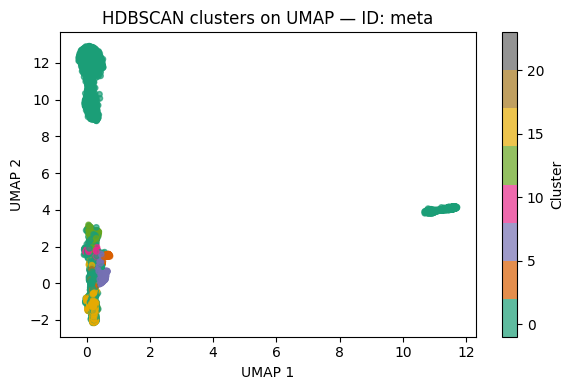

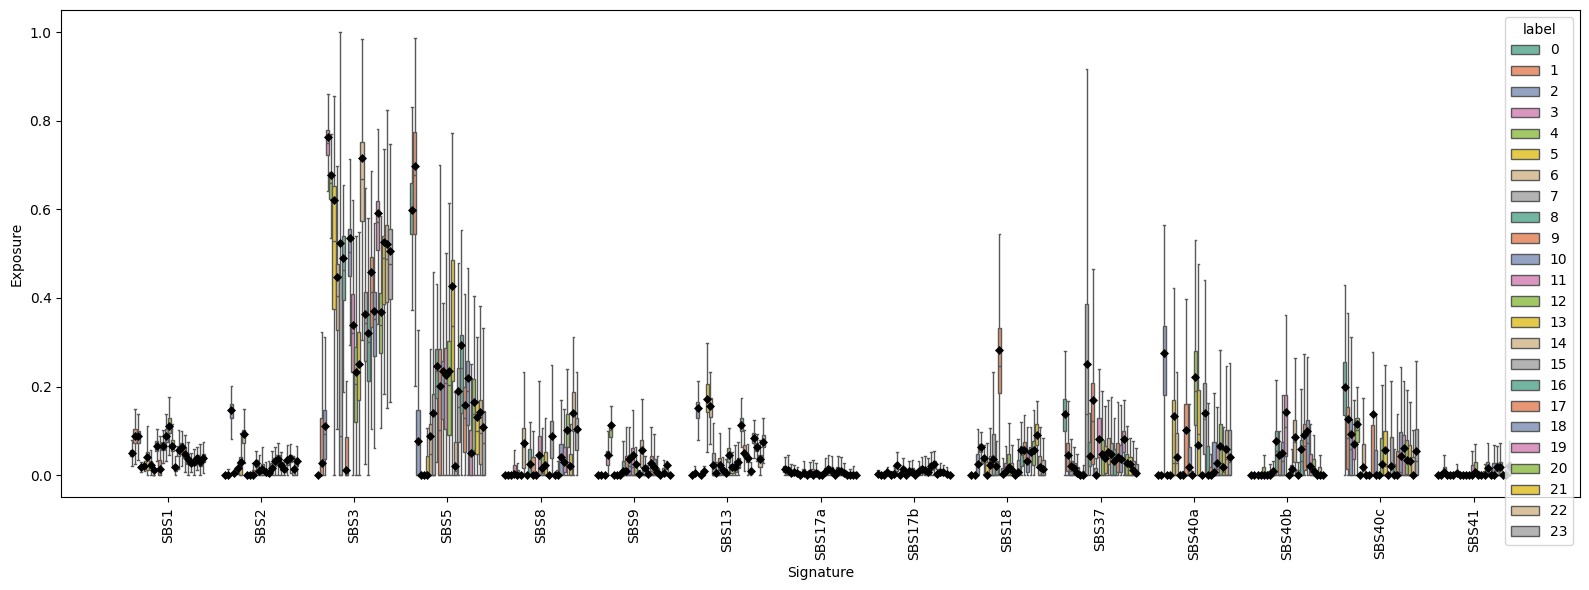

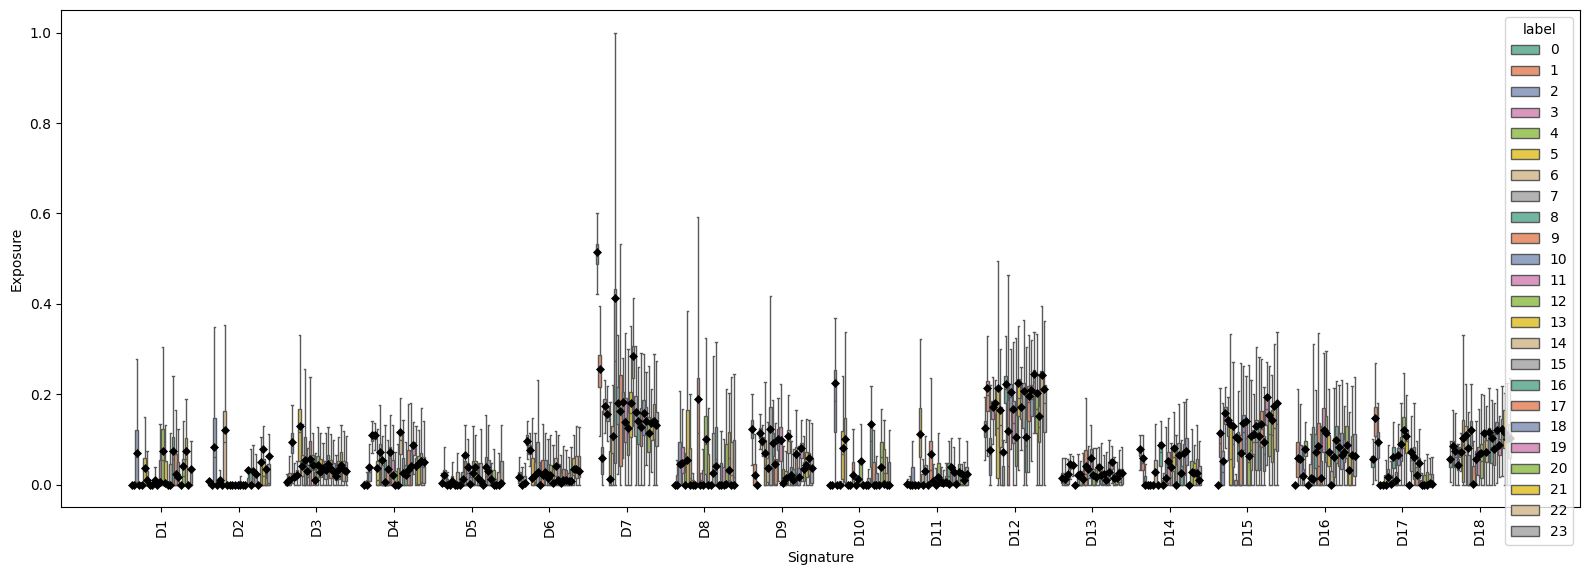

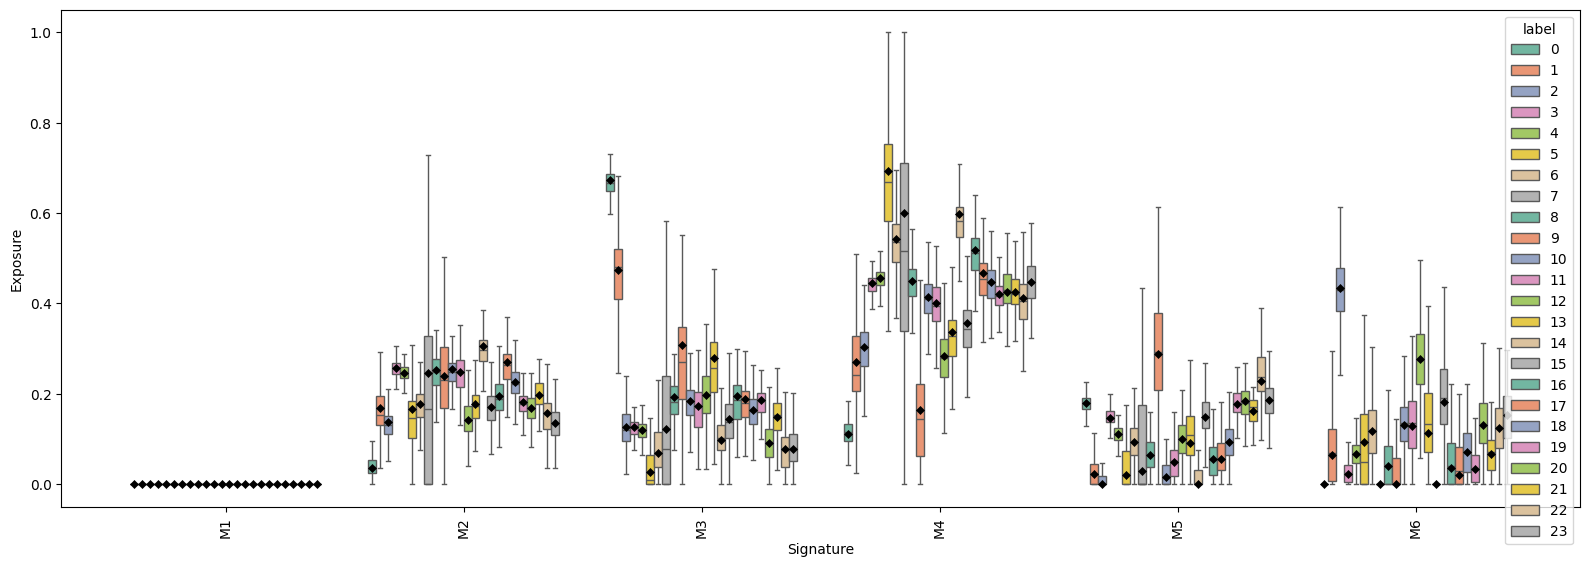

In [6]:
y = meta

print(' ### META ### ')
print(crosstable(y.umap(metric='hellinger').hdbscan().get_labels(), y.umap().hdbscan().get_labels()))
print('cosine similarity siluette score:', y.umap().hdbscan().silhouette_score())
print('Hellinger siluette score:', y.umap(metric='hellinger').hdbscan().silhouette_score())
y.umap().hdbscan().plot_clustering()
y.umap().hdbscan().plot_deconv(signatures=cosmic.loc[breast_sigs])
y.umap().hdbscan().plot_deconv(signatures=dmg_sig)
y.umap().hdbscan().plot_deconv(signatures=misr_sig)

 ###  SA1047  ### 
number of cells: 347
Cluster B   -1   0   1
Cluster A             
-1         205  60  82
cosine similarity siluette score: 0.39874935150146484
ERROR for SA1047: Silhouette score requires at least 2 clusters.



 ###  SA1052  ### 
number of cells: 556
Cluster B   0    1
Cluster A         
0          41    0
1           0  515
cosine similarity siluette score: 0.9384171962738037
Hellinger siluette score: 0.9298959374427795


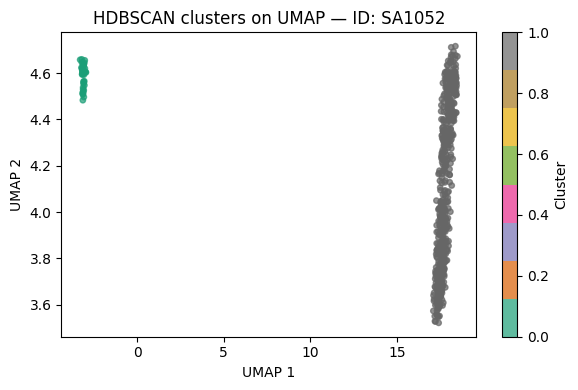

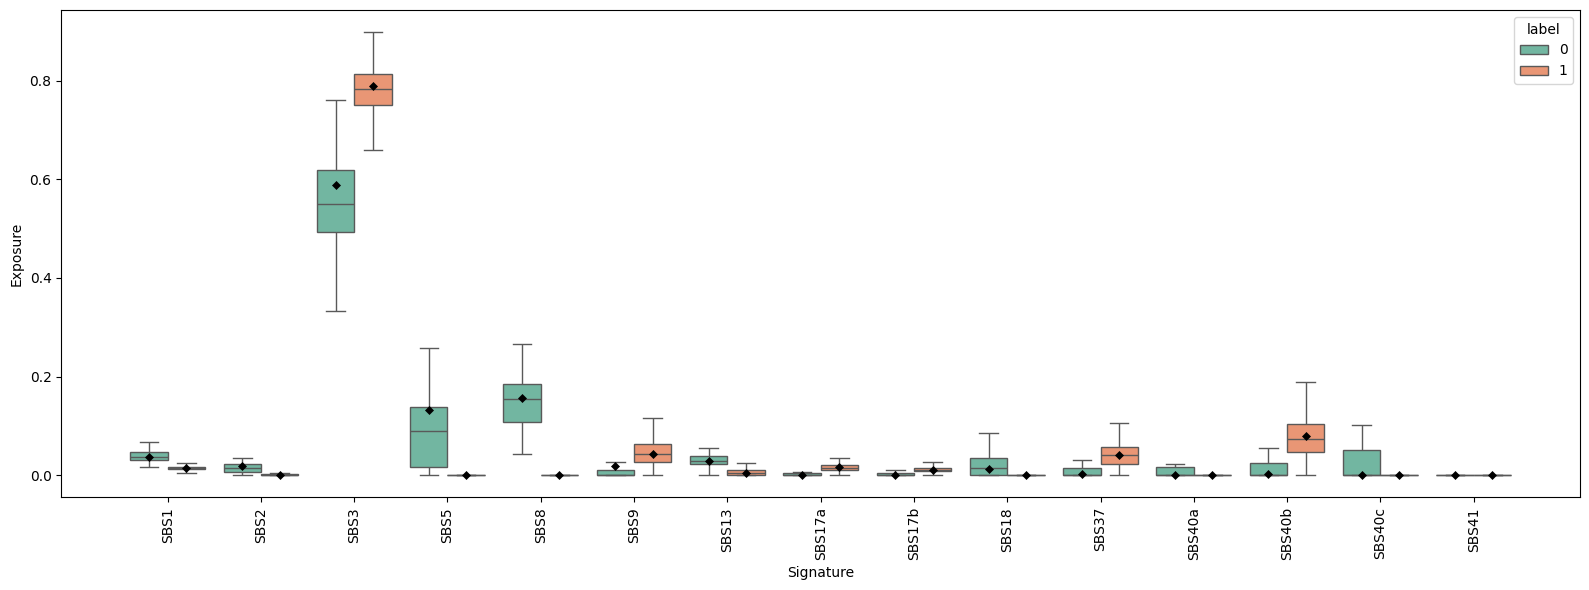

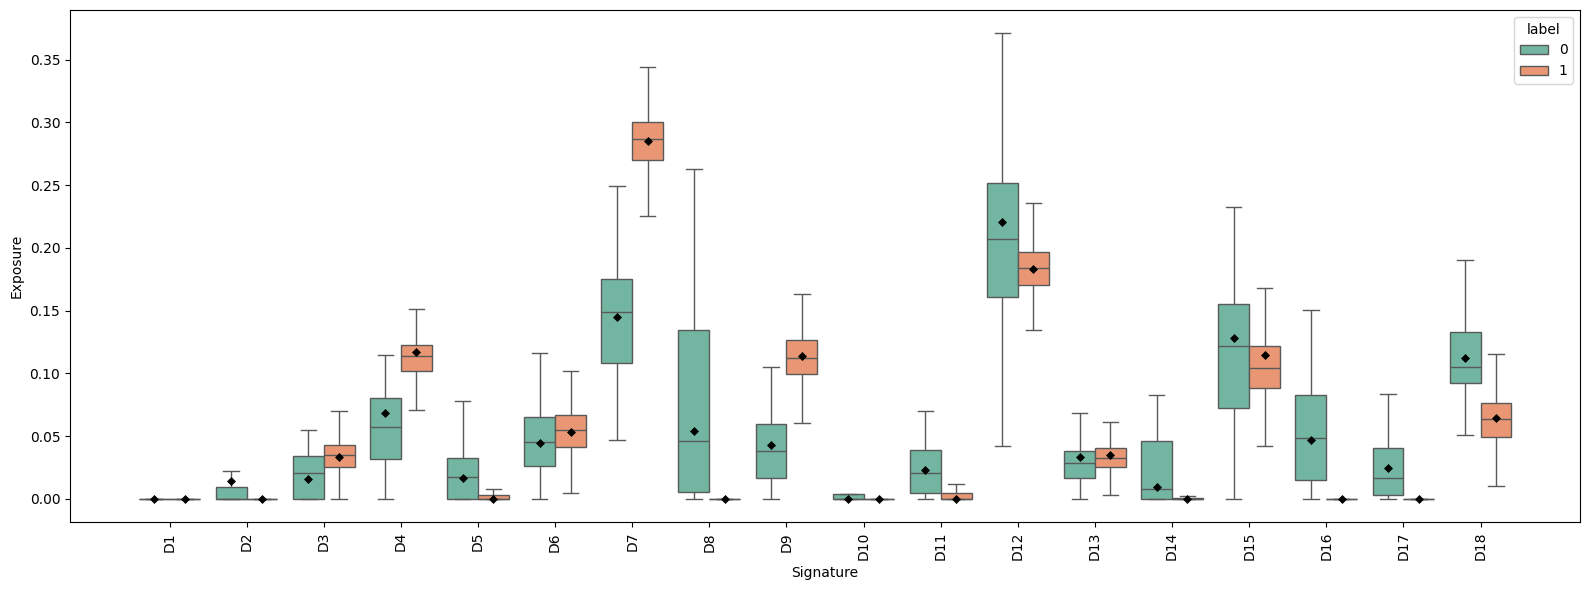

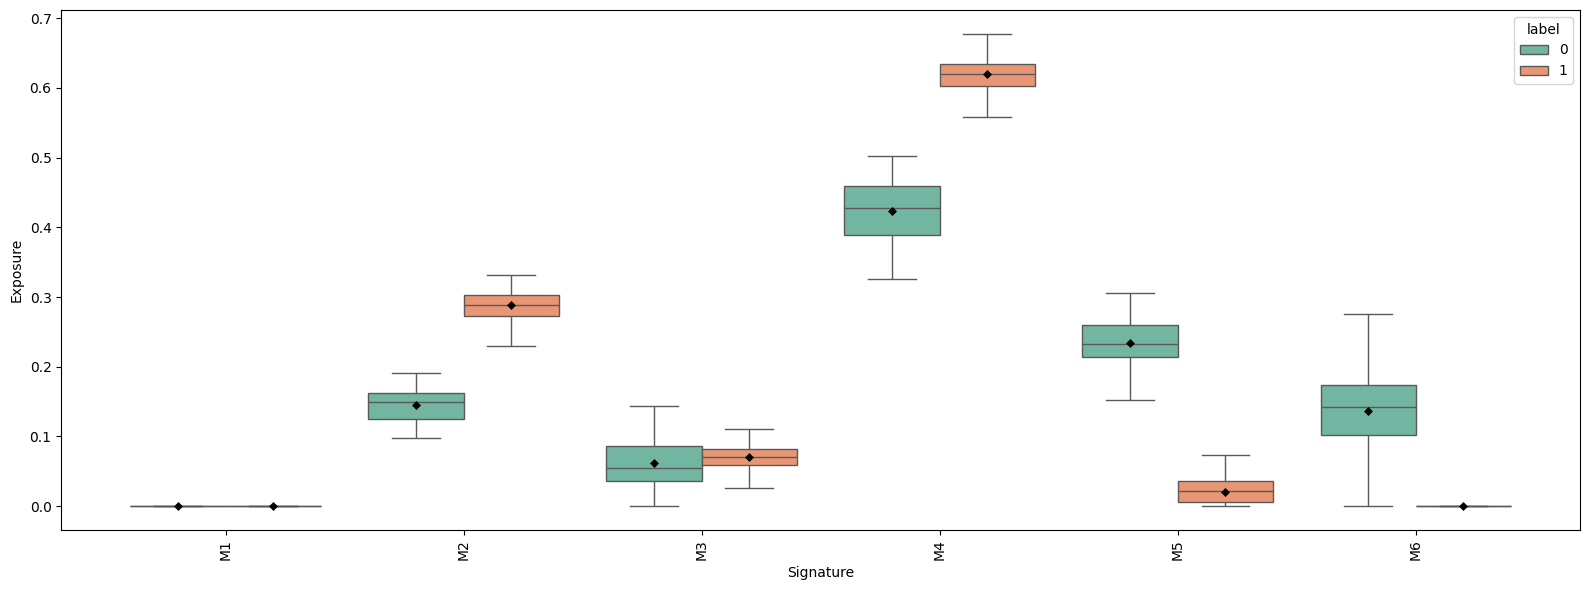




 ###  SA1135  ### 
number of cells: 221
Cluster B  -1   0   1
Cluster A            
-1         50  39  52
 0         18   9  11
 1         13  13  16
cosine similarity siluette score: 0.3500746190547943
Hellinger siluette score: 0.2112182378768921


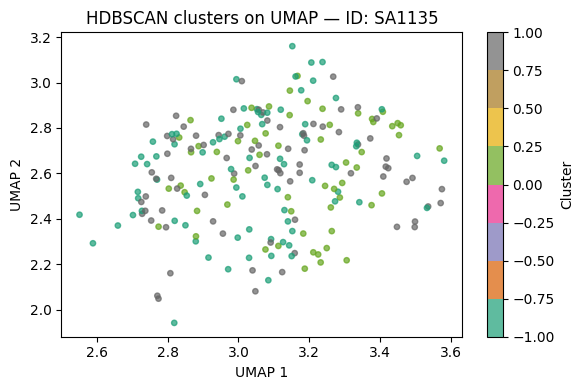

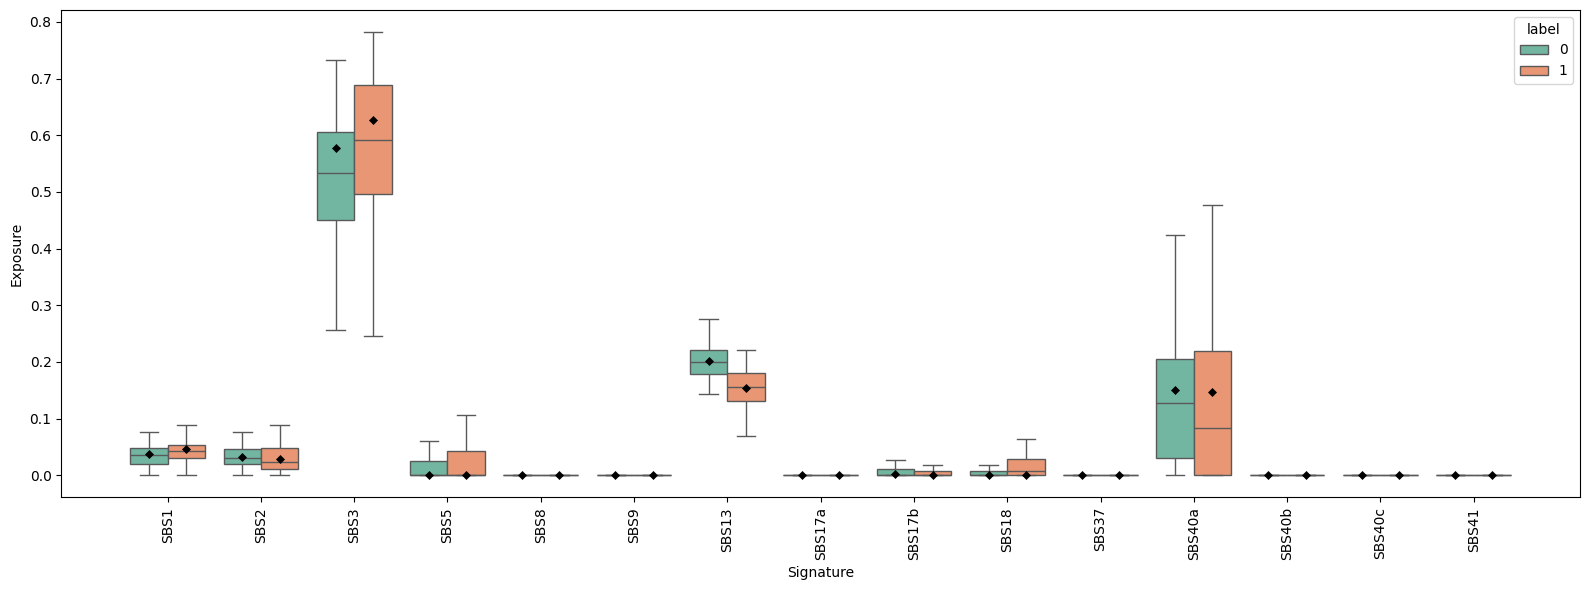

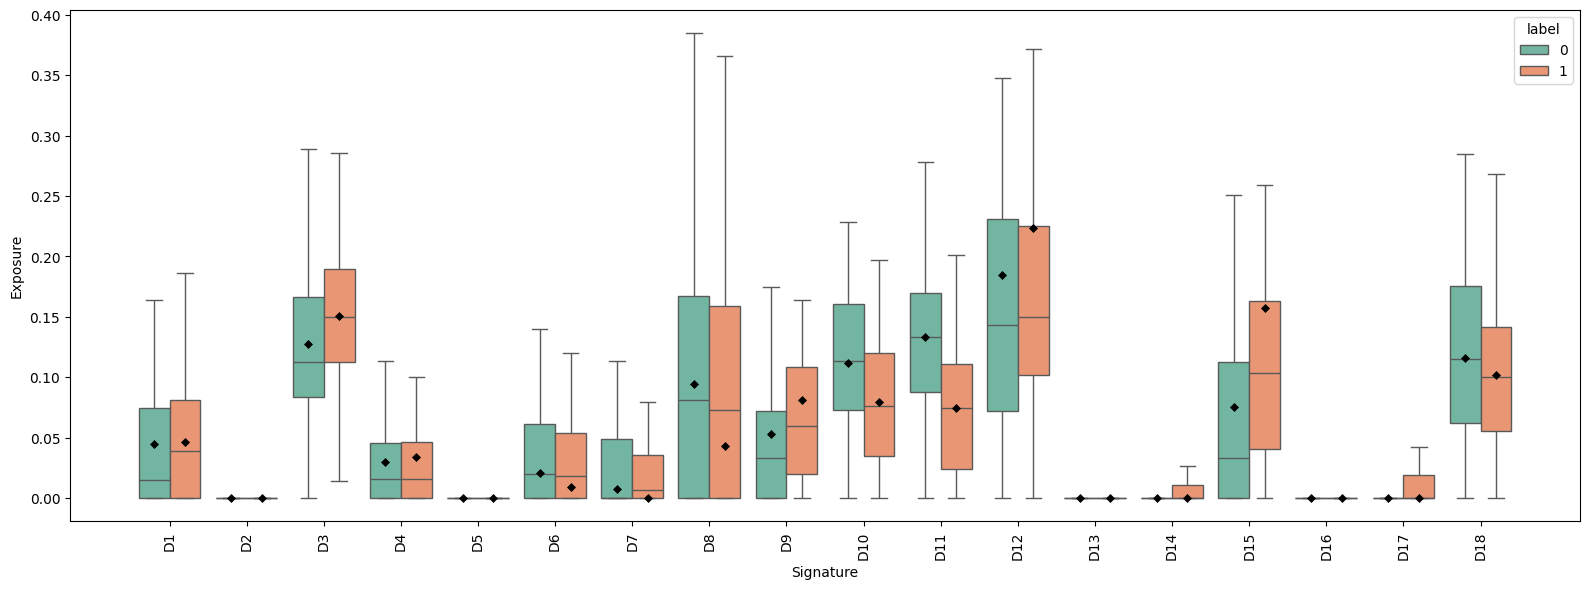

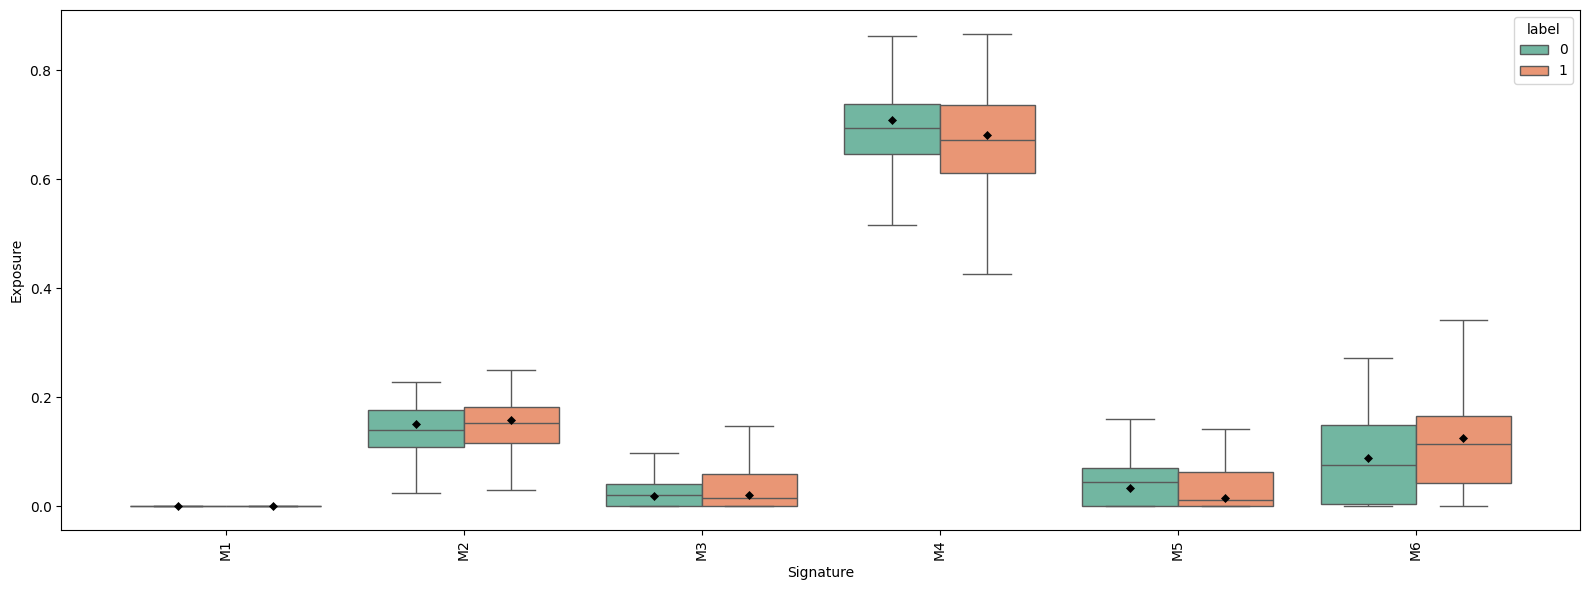




 ###  SA604  ### 
number of cells: 2139
Cluster B    0     1
Cluster A           
0          706     0
1            0  1433
cosine similarity siluette score: 0.9718974828720093
Hellinger siluette score: 0.95332932472229


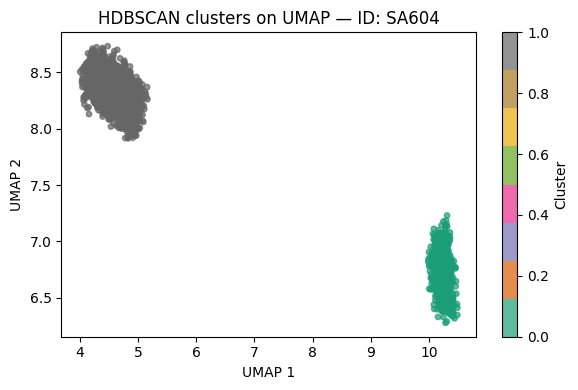

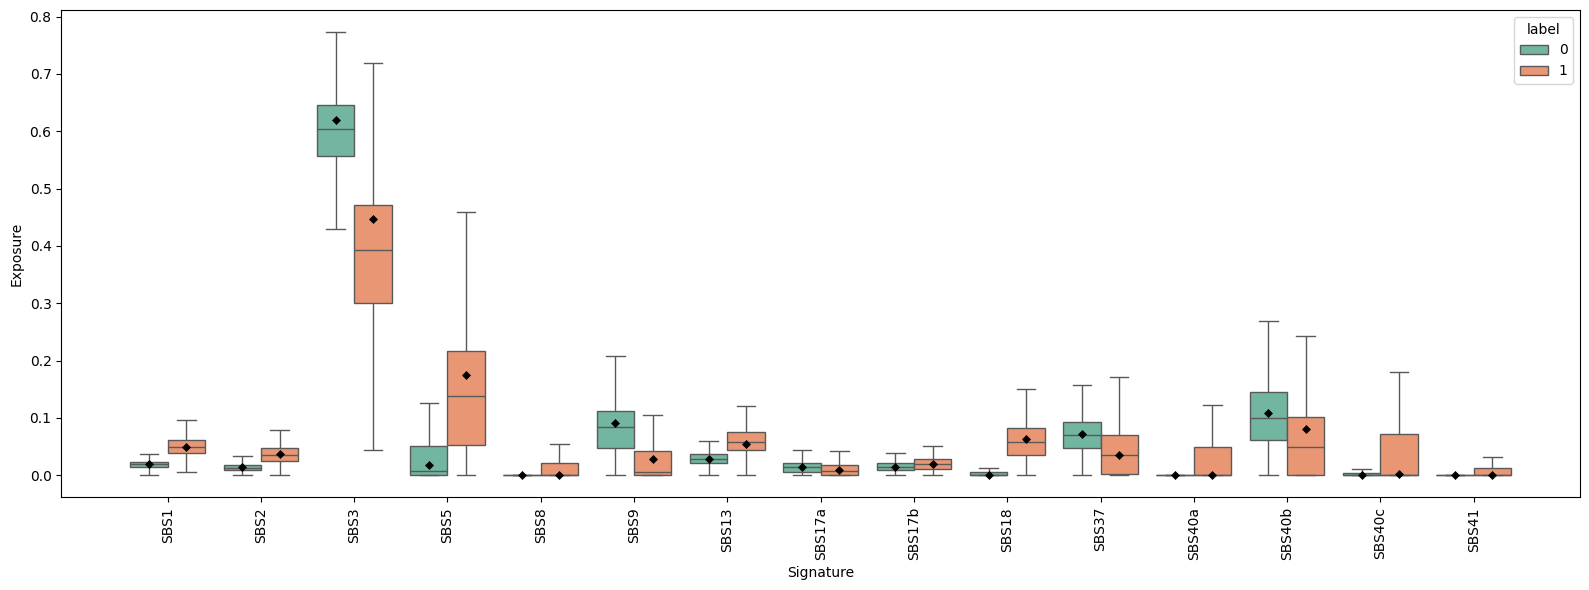

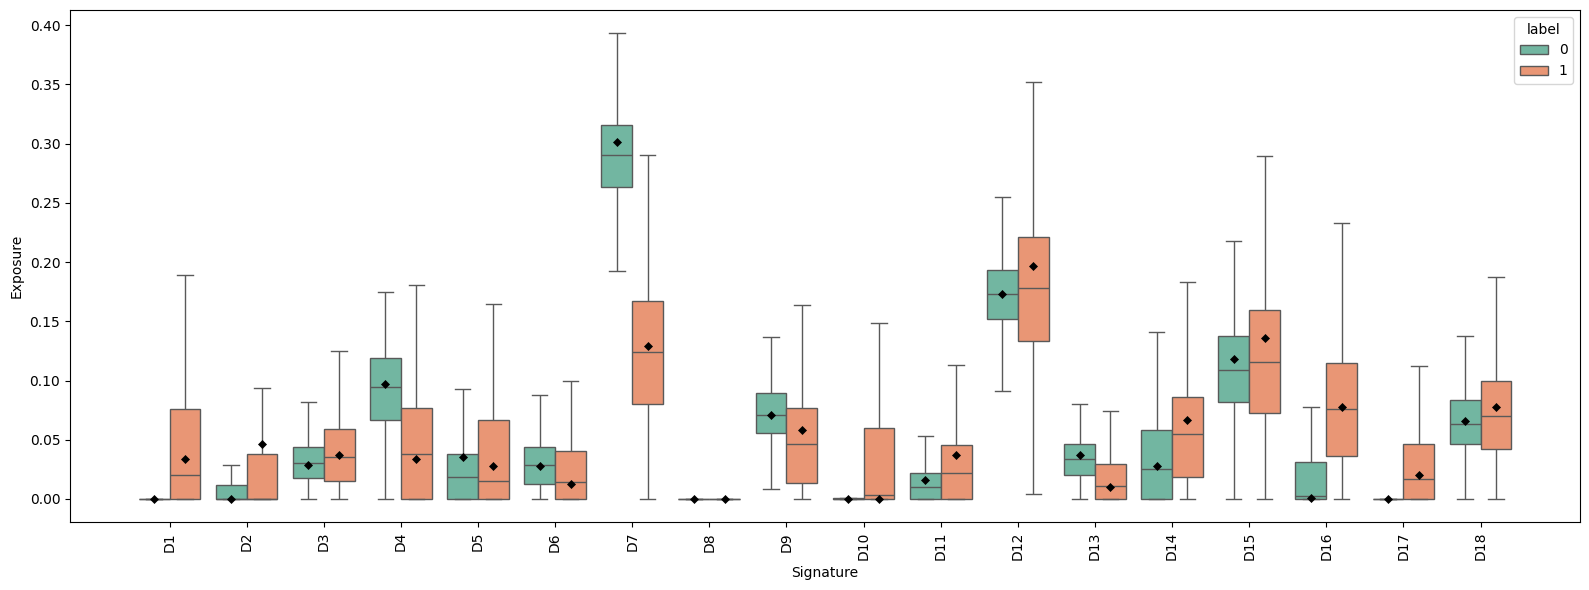

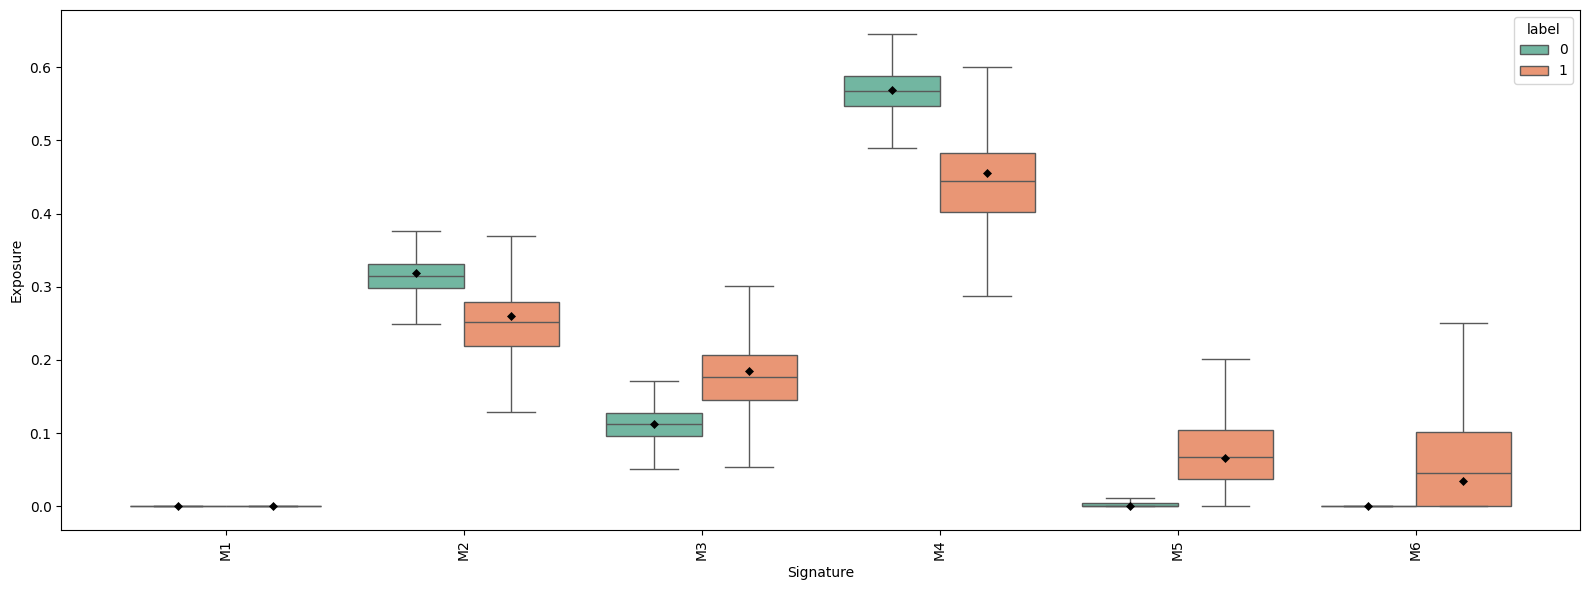




 ###  SA1055  ### 
number of cells: 391
Cluster B  -1   0   1
Cluster A            
-1         98  69  31
 0         12  15   8
 1         34  47  10
 2         27  27  13
cosine similarity siluette score: 0.13275524973869324
Hellinger siluette score: 0.1282532513141632


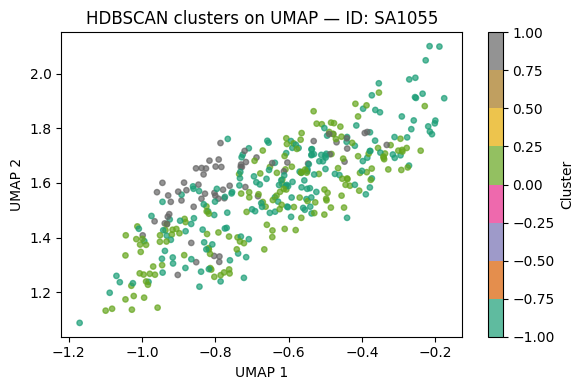

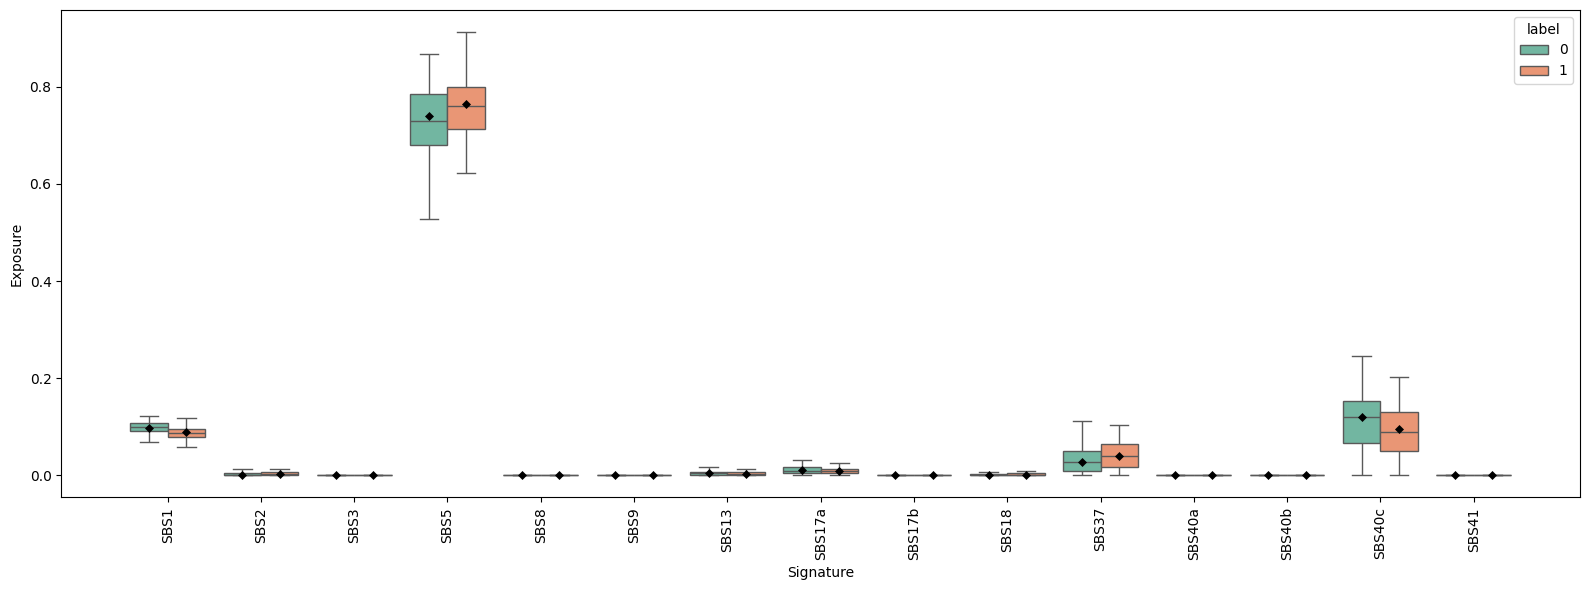

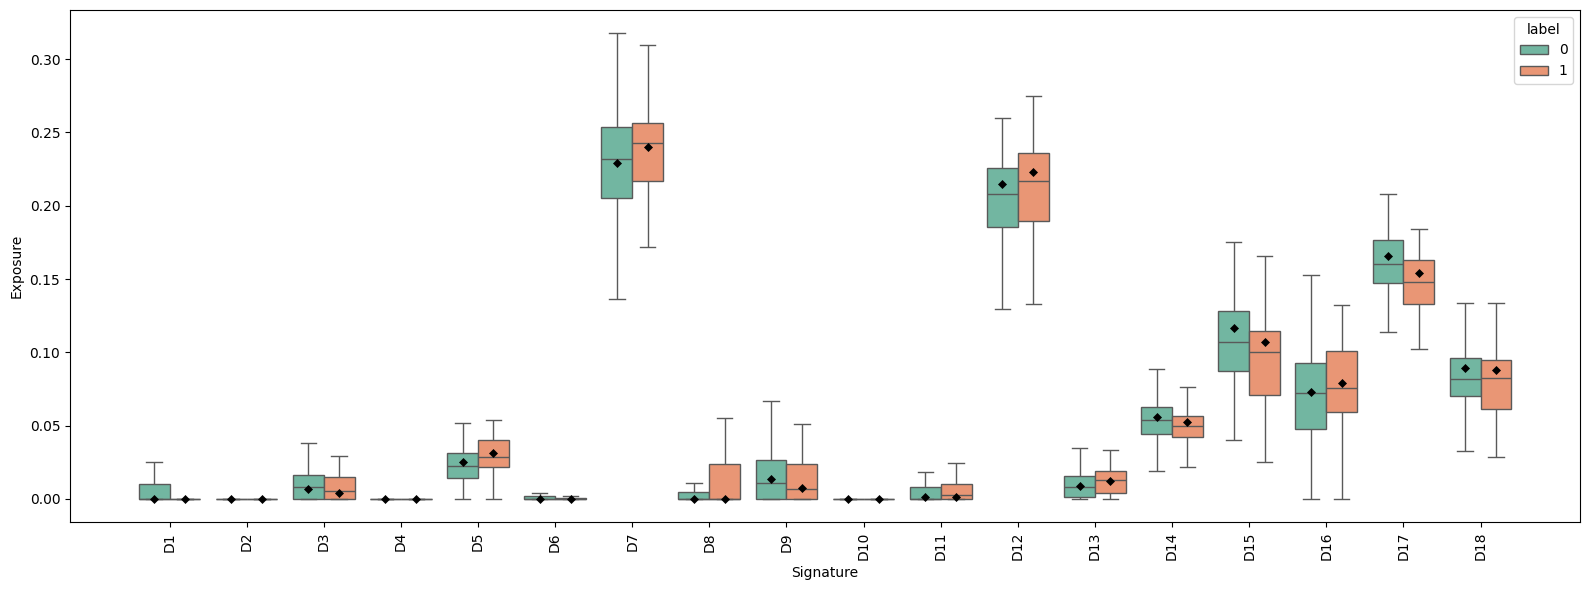

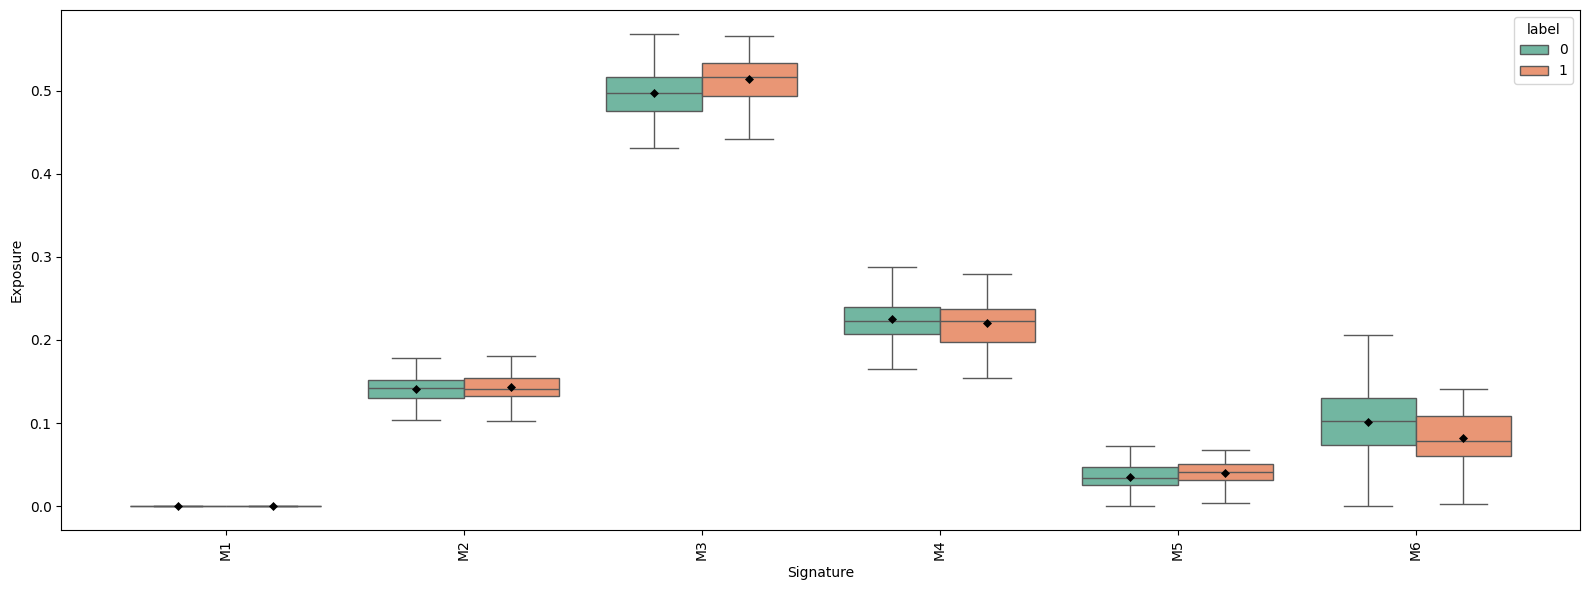




 ###  SA530  ### 
number of cells: 324
Cluster B  -1    0    1
Cluster A              
-1          2   22    3
 0          2  163    0
 1          1    6  125
cosine similarity siluette score: 0.637441873550415
Hellinger siluette score: 0.5959876179695129


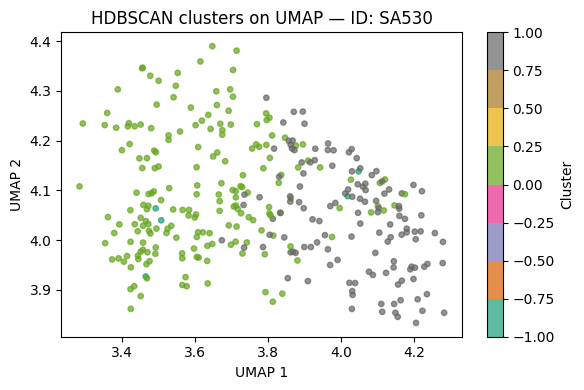

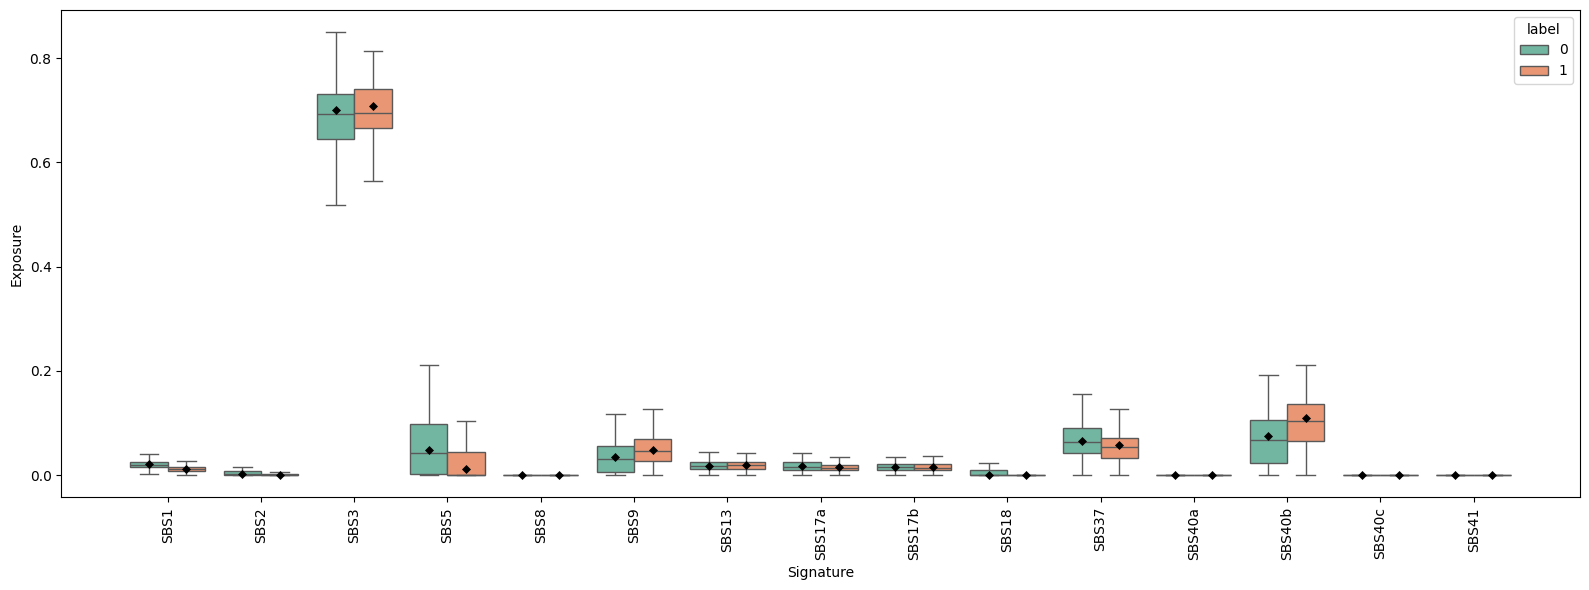

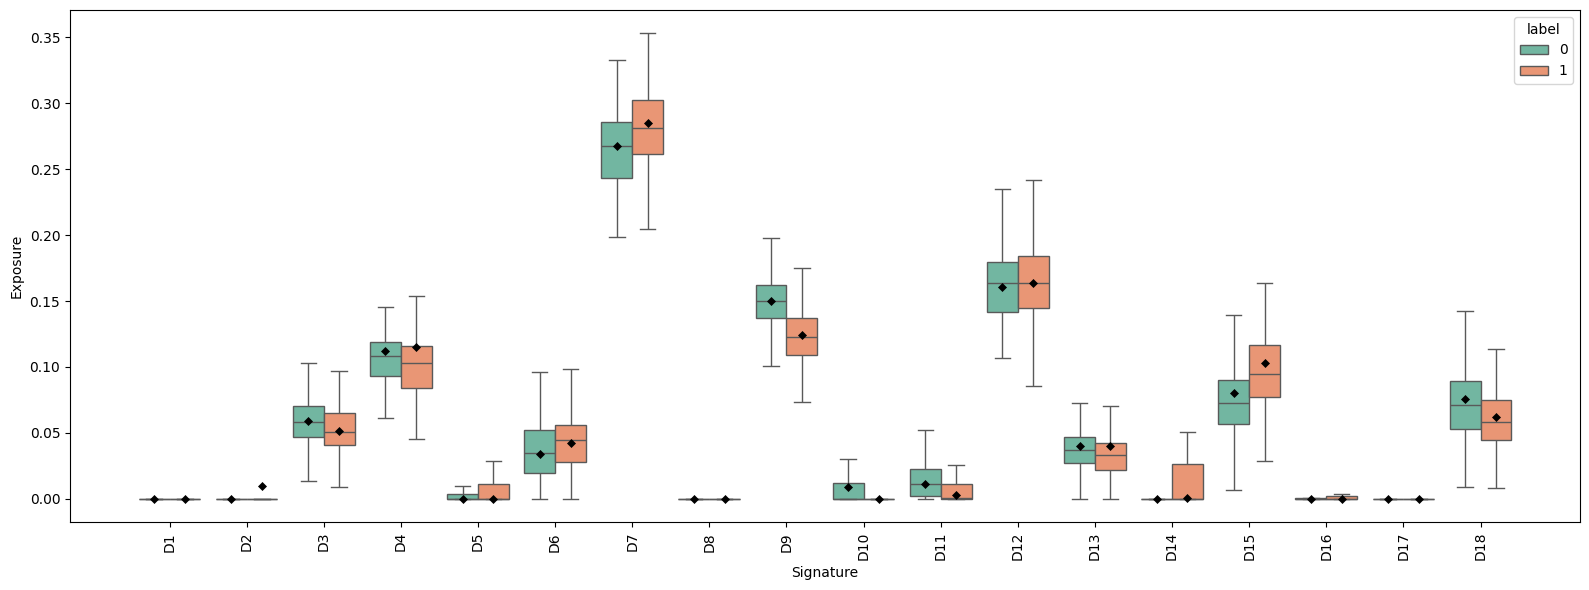

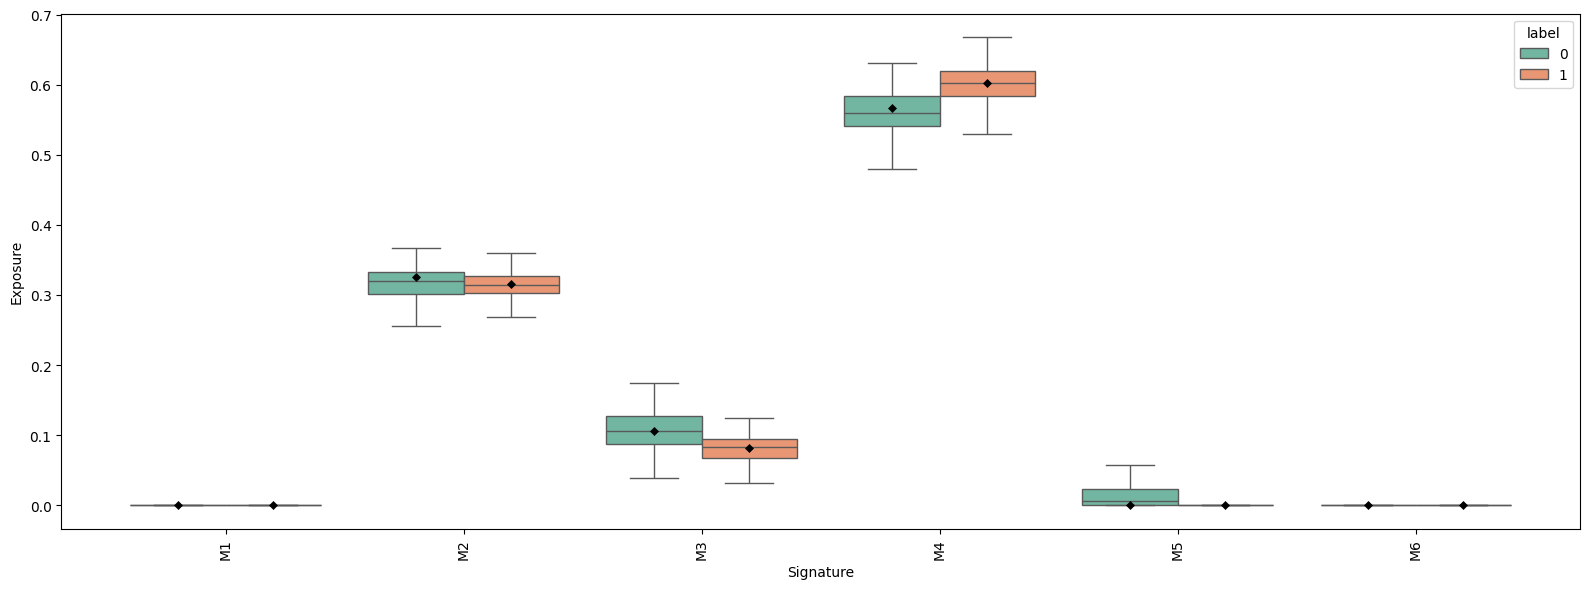




 ###  SA1049  ### 
number of cells: 1283
Cluster B    0    1
Cluster A          
0          680    0
1            0  603
cosine similarity siluette score: 0.9406055808067322
Hellinger siluette score: 0.9478663802146912


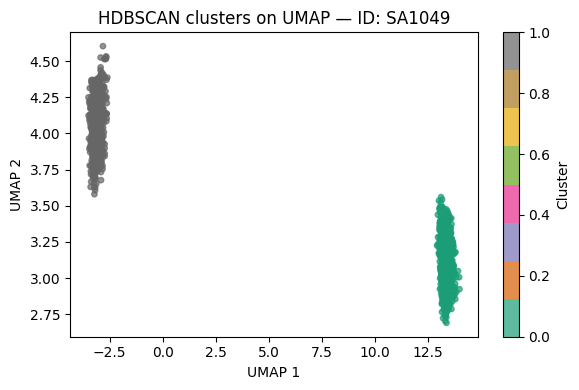

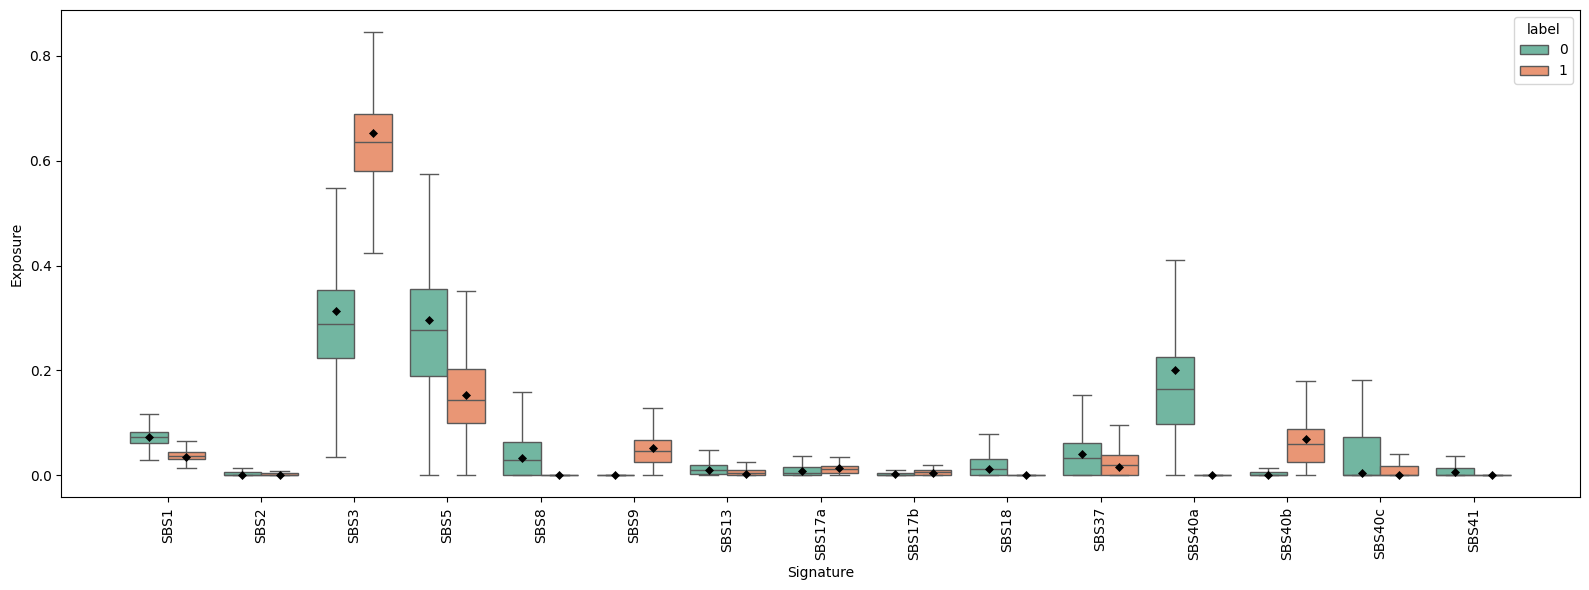

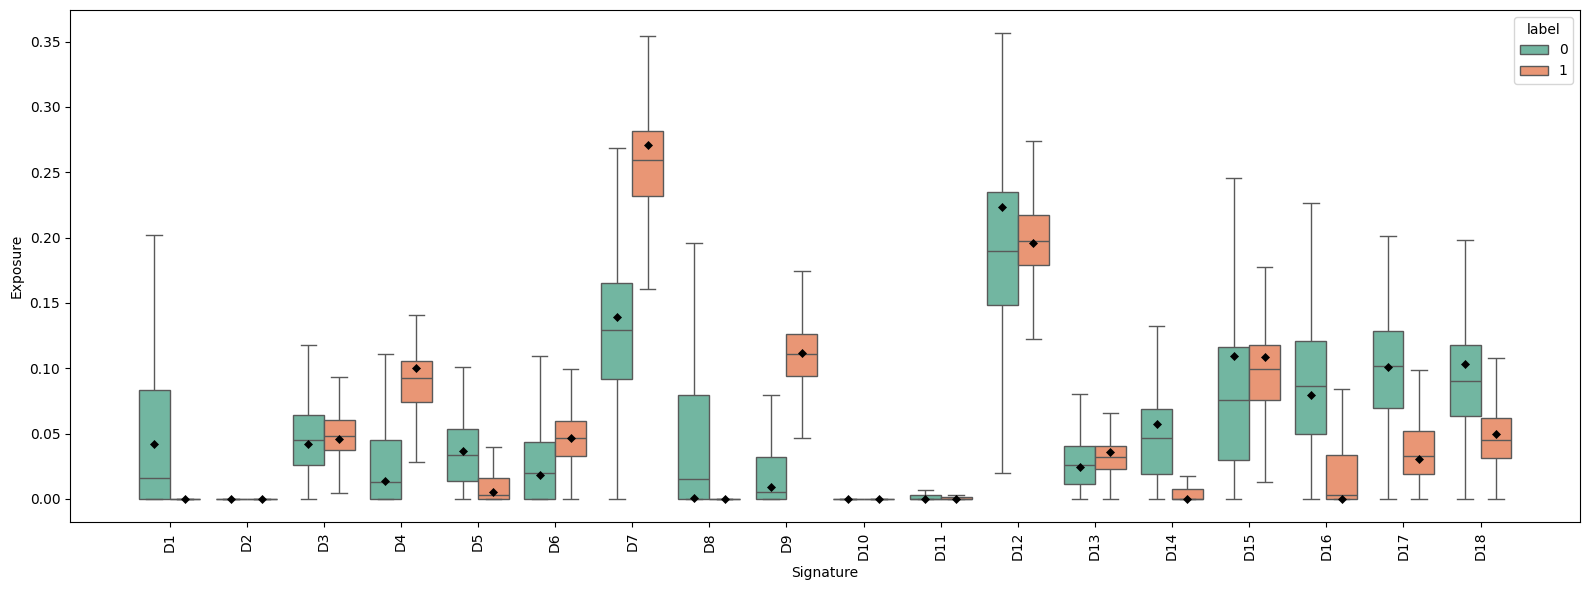

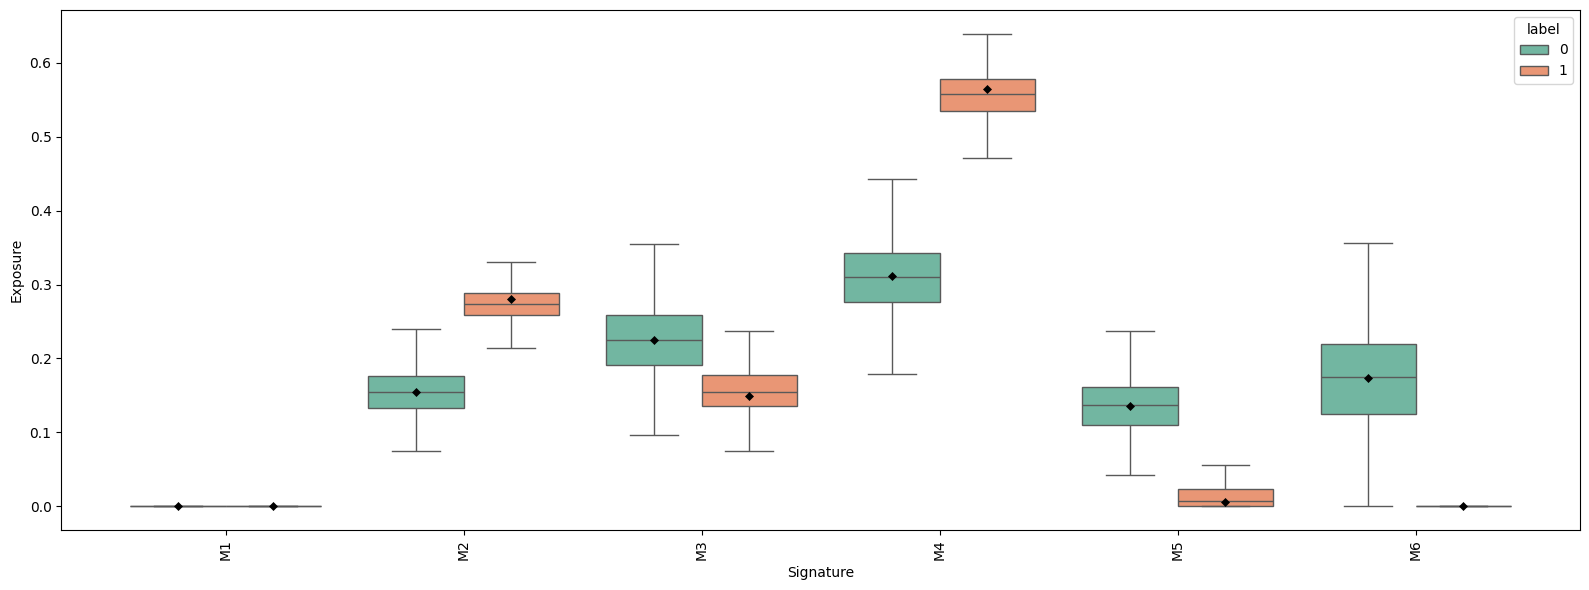




 ###  SA1054  ### 
number of cells: 382
Cluster B  -1   0   1
Cluster A            
-1         93  41  75
 0         23  15  34
 1         37  30  34
cosine similarity siluette score: 0.15288108587265015
Hellinger siluette score: 0.09859468787908554


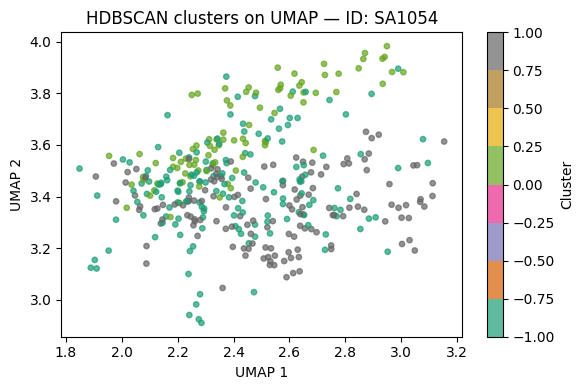

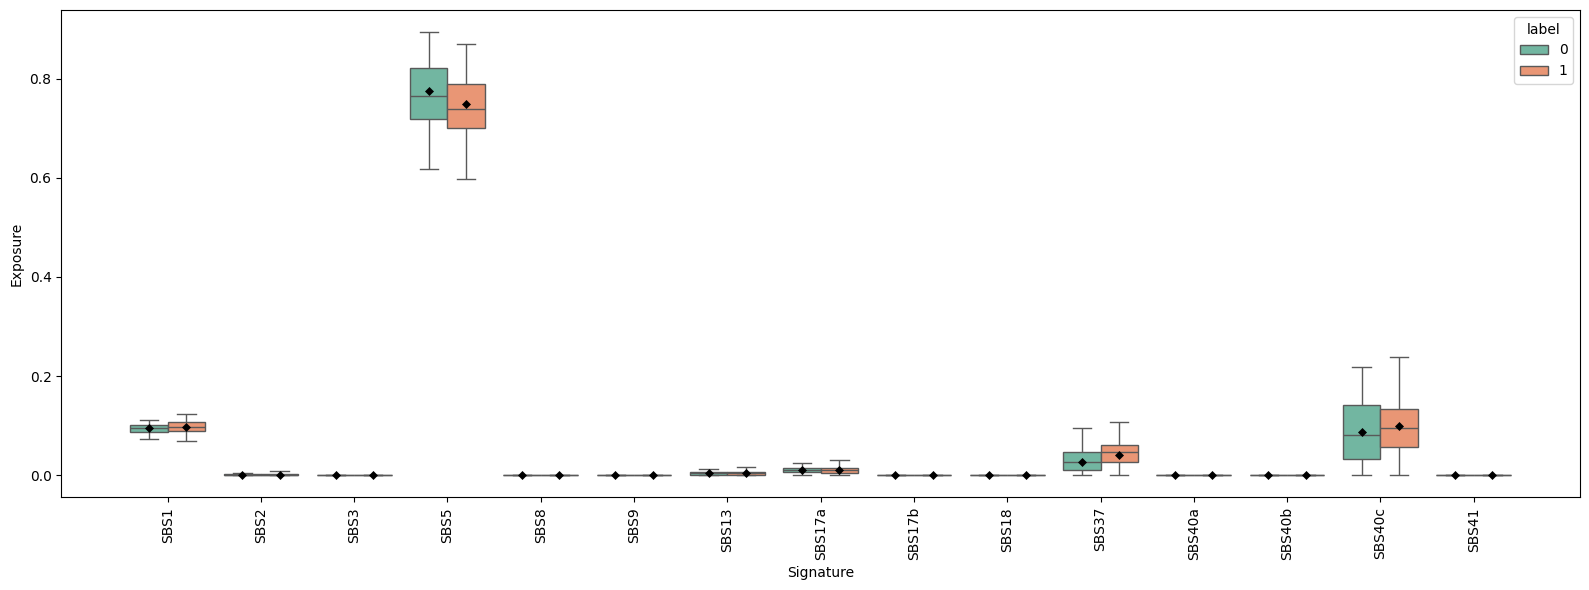

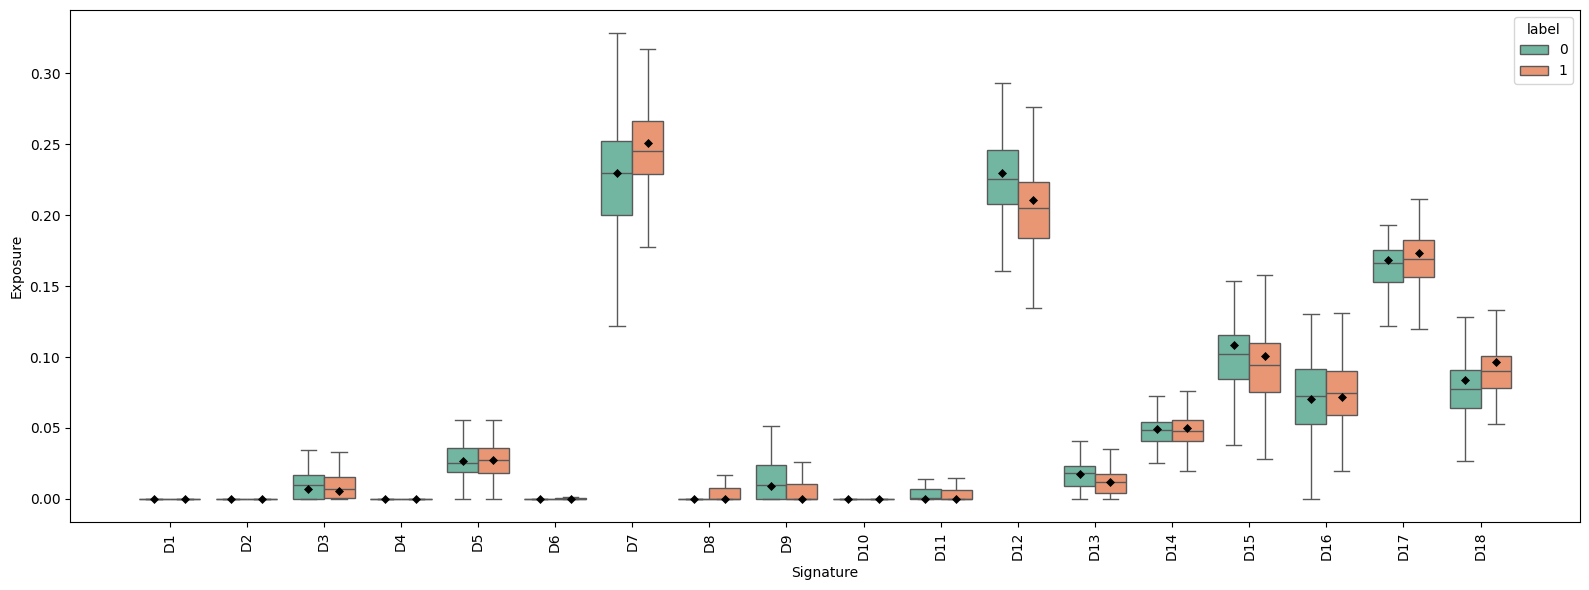

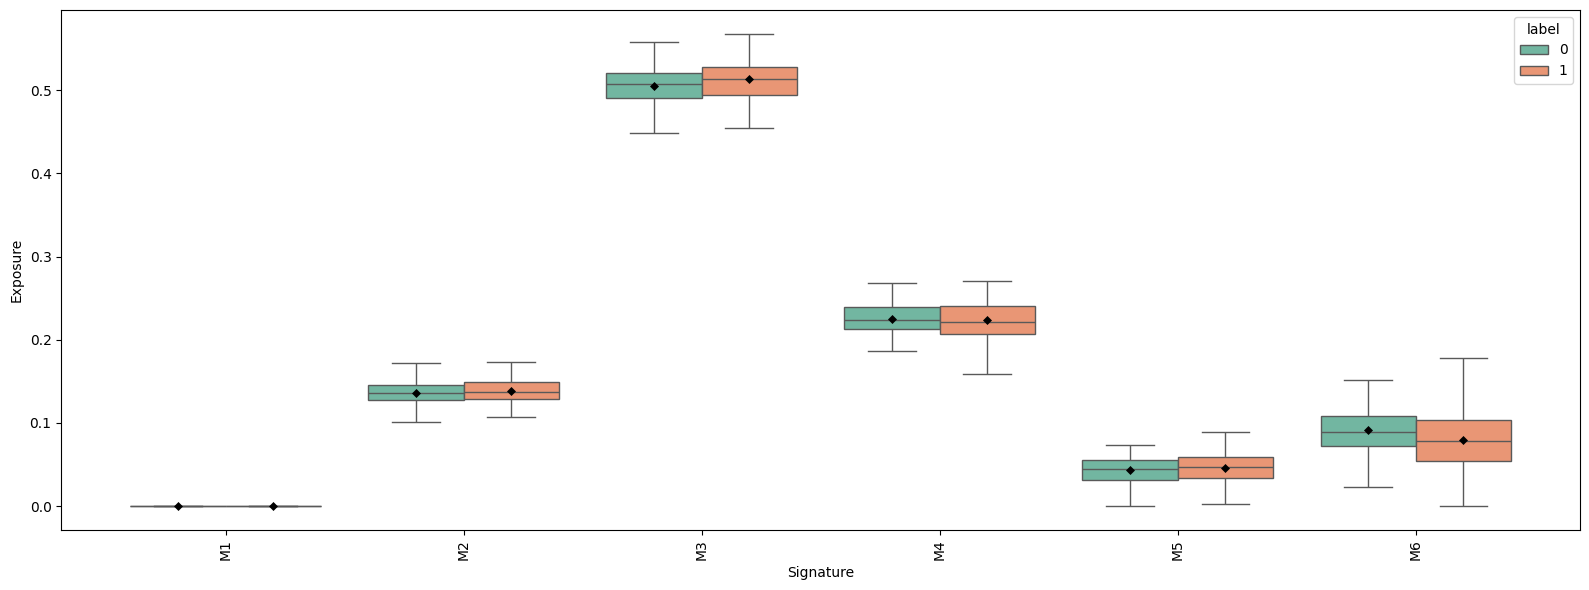




 ###  SA1142  ### 
number of cells: 2092
Cluster B     0    1
Cluster A           
-1          276   23
 0         1096   34
 1           28  635
cosine similarity siluette score: 0.733626127243042
Hellinger siluette score: 0.740155816078186


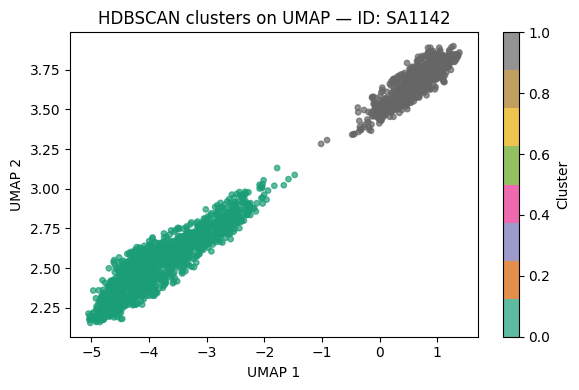

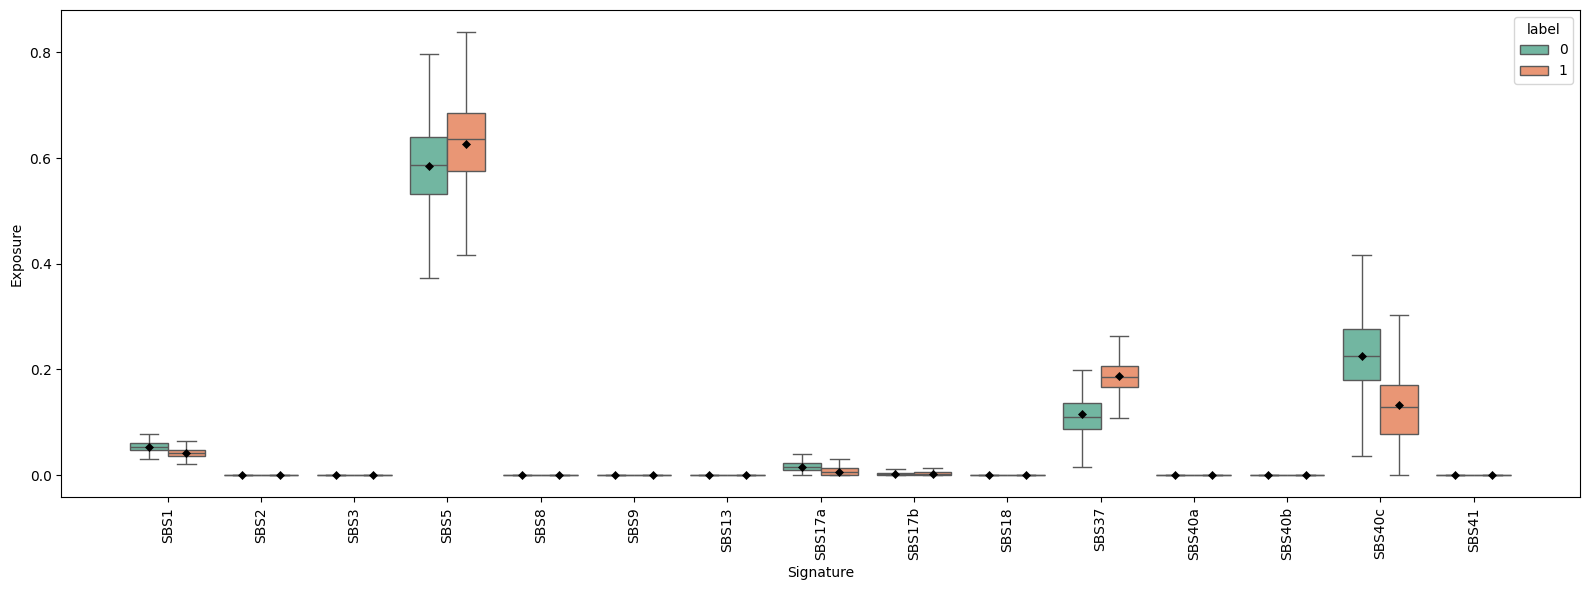

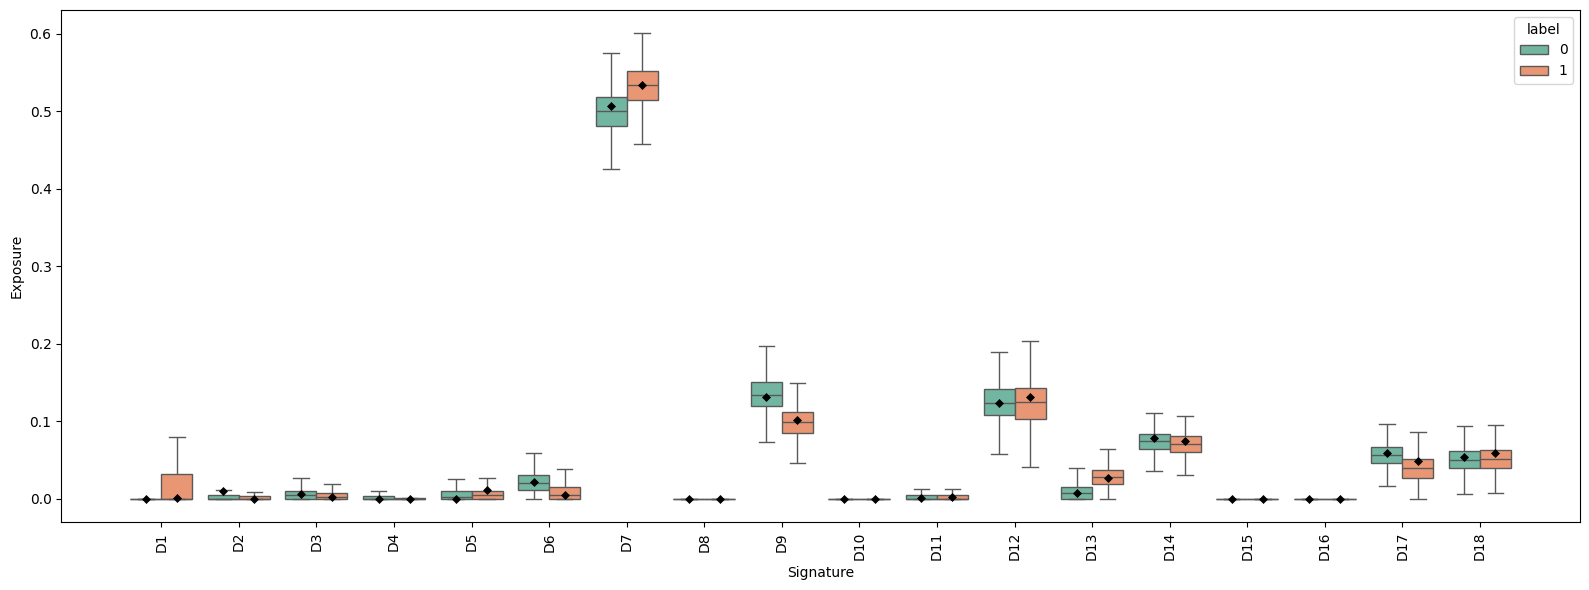

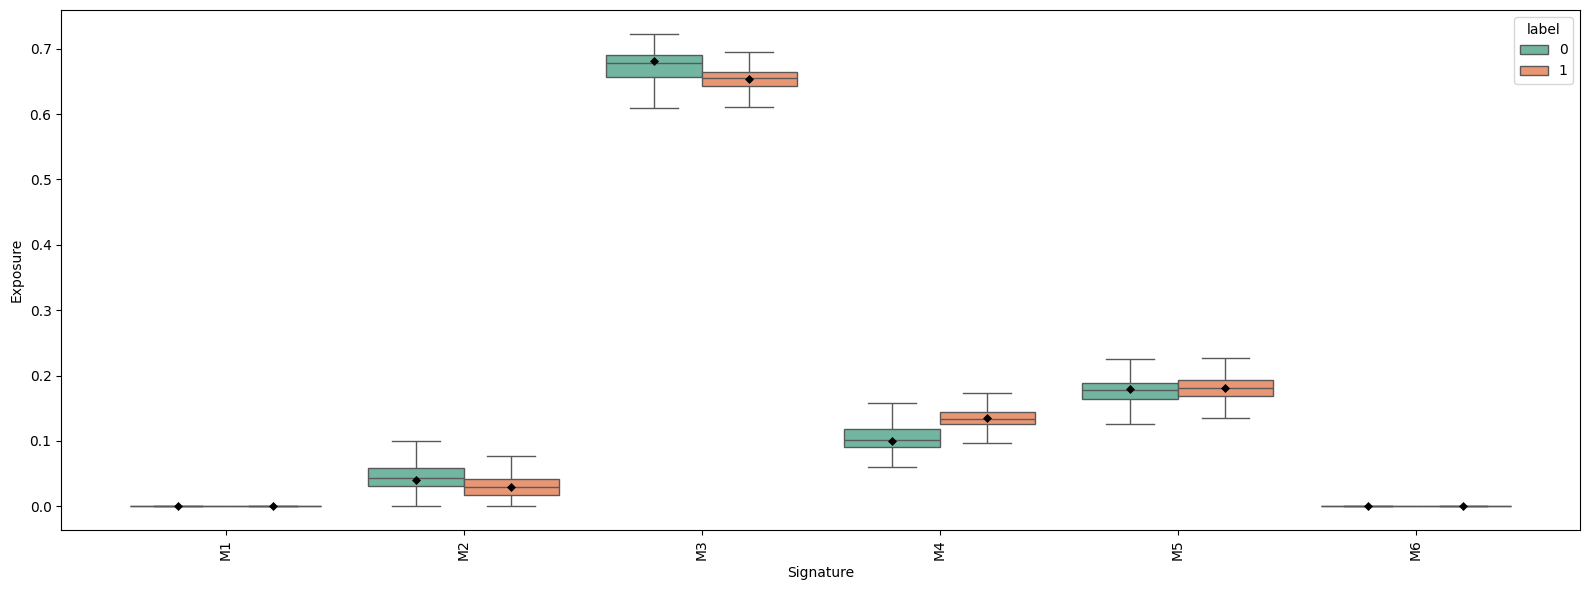




 ###  SA1292  ### 
number of cells: 404
Cluster B   -1   0   1   2   3
Cluster A                     
-1         117  42  21  18  10
 0          57  21   7  16  18
 1          38  24   7   4   4
cosine similarity siluette score: 0.23423732817173004
Hellinger siluette score: 0.15205030143260956


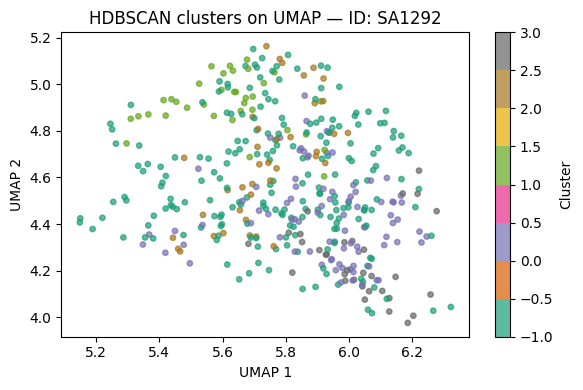

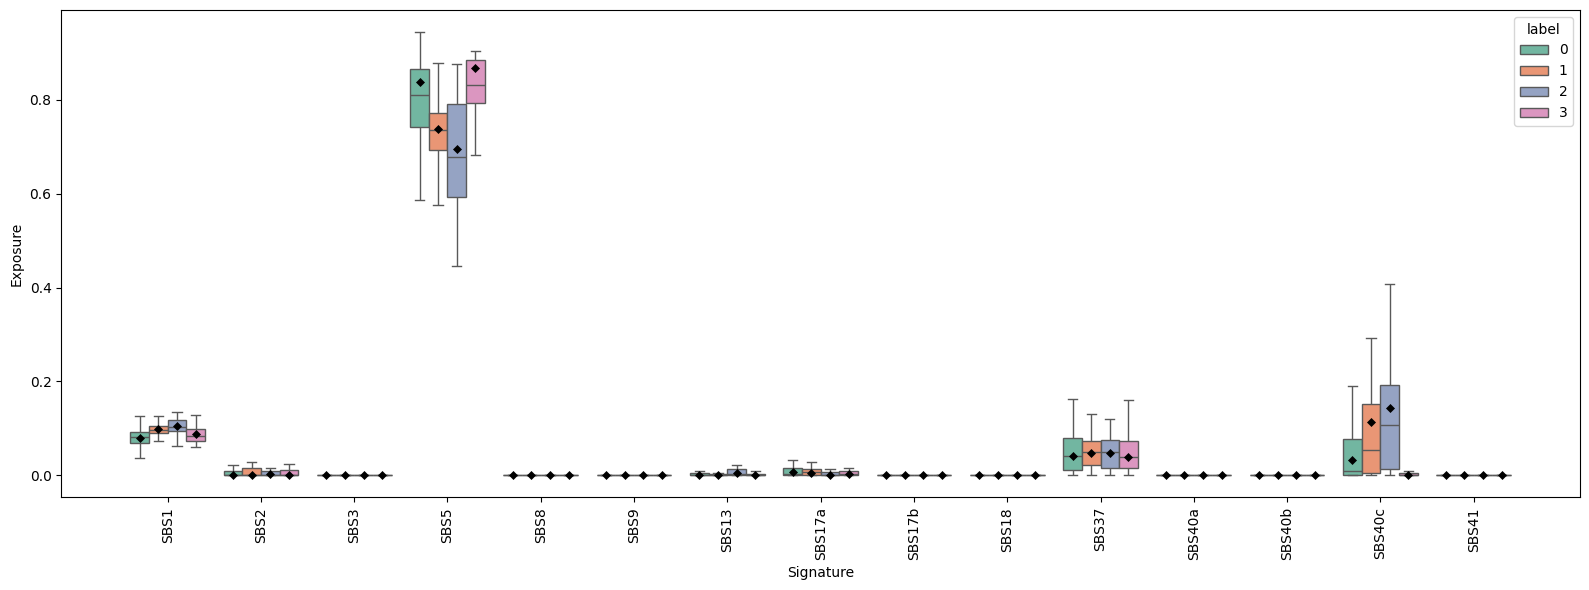

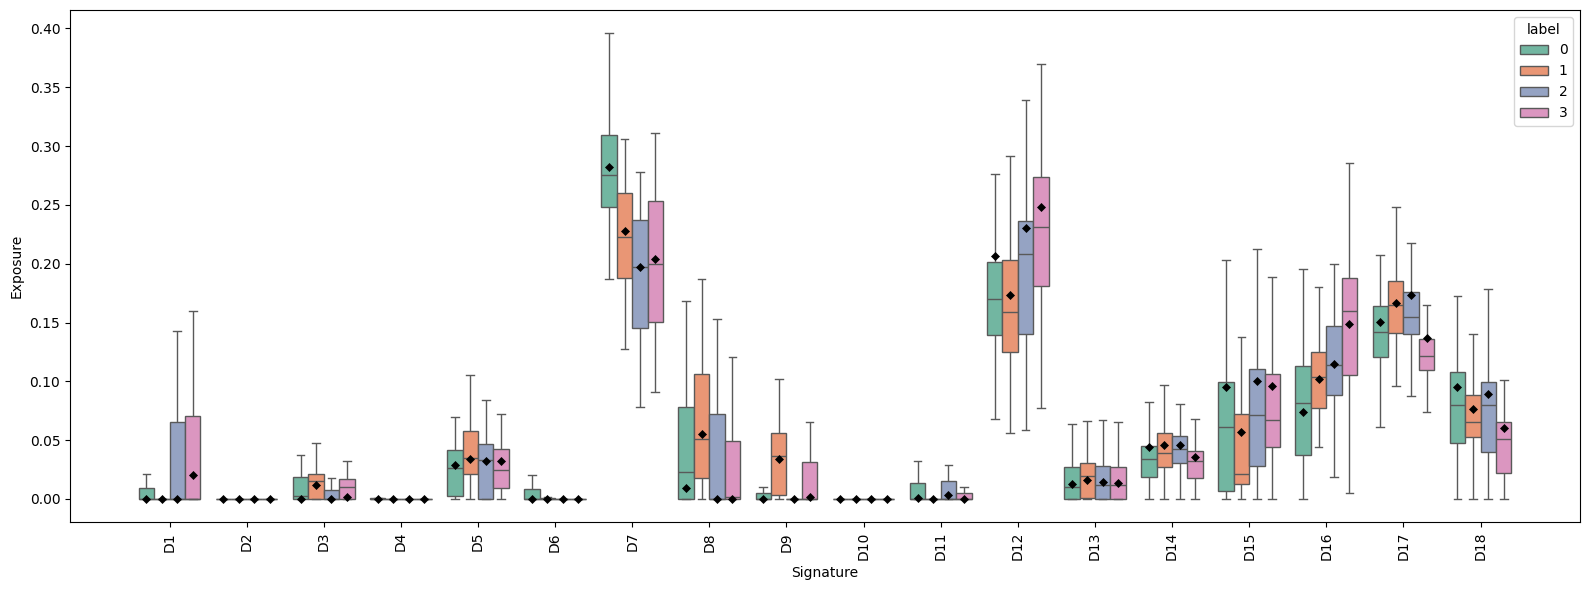

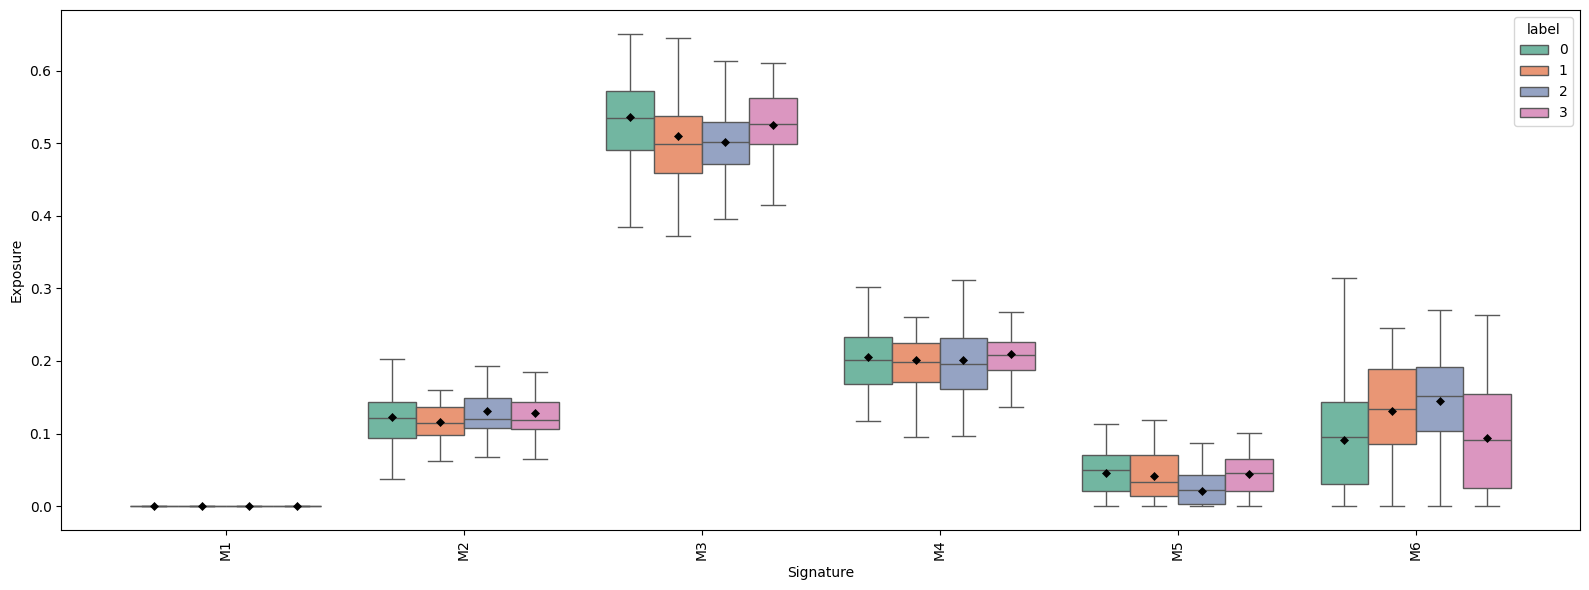




 ###  OV2295  ### 
number of cells: 1084
Cluster B    0    1    2
Cluster A               
0          389    0    0
1            0  390    0
2            0    0  305
cosine similarity siluette score: 0.9409919381141663
Hellinger siluette score: 0.9195001721382141


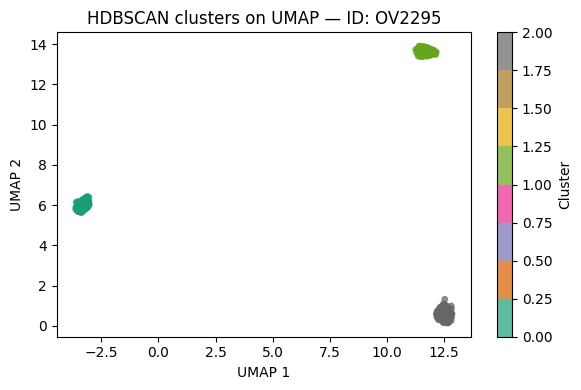

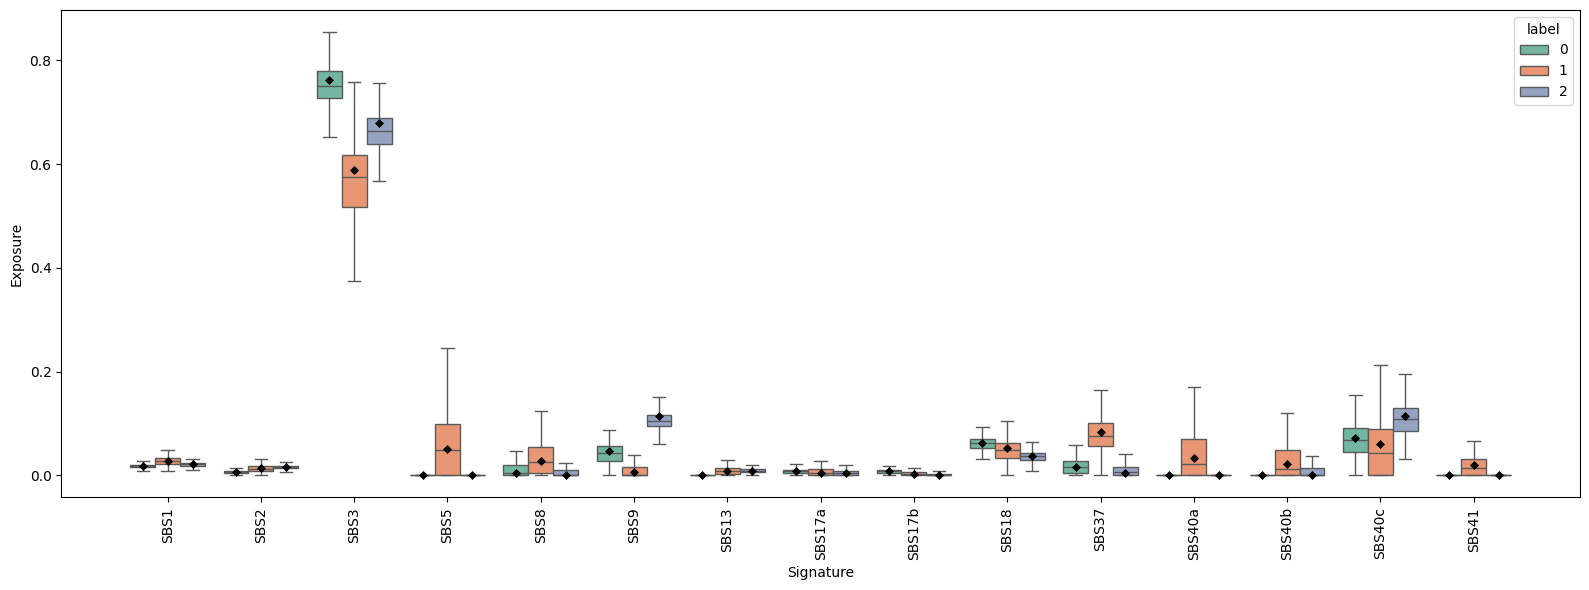

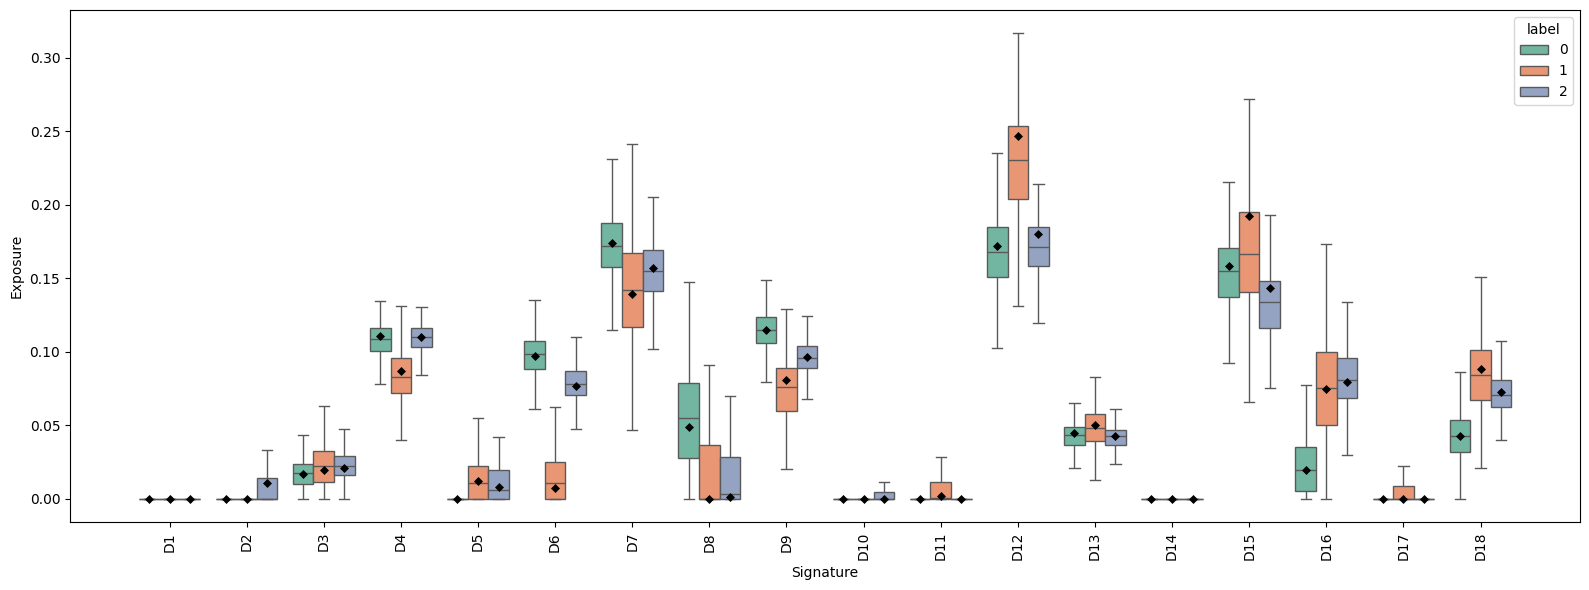

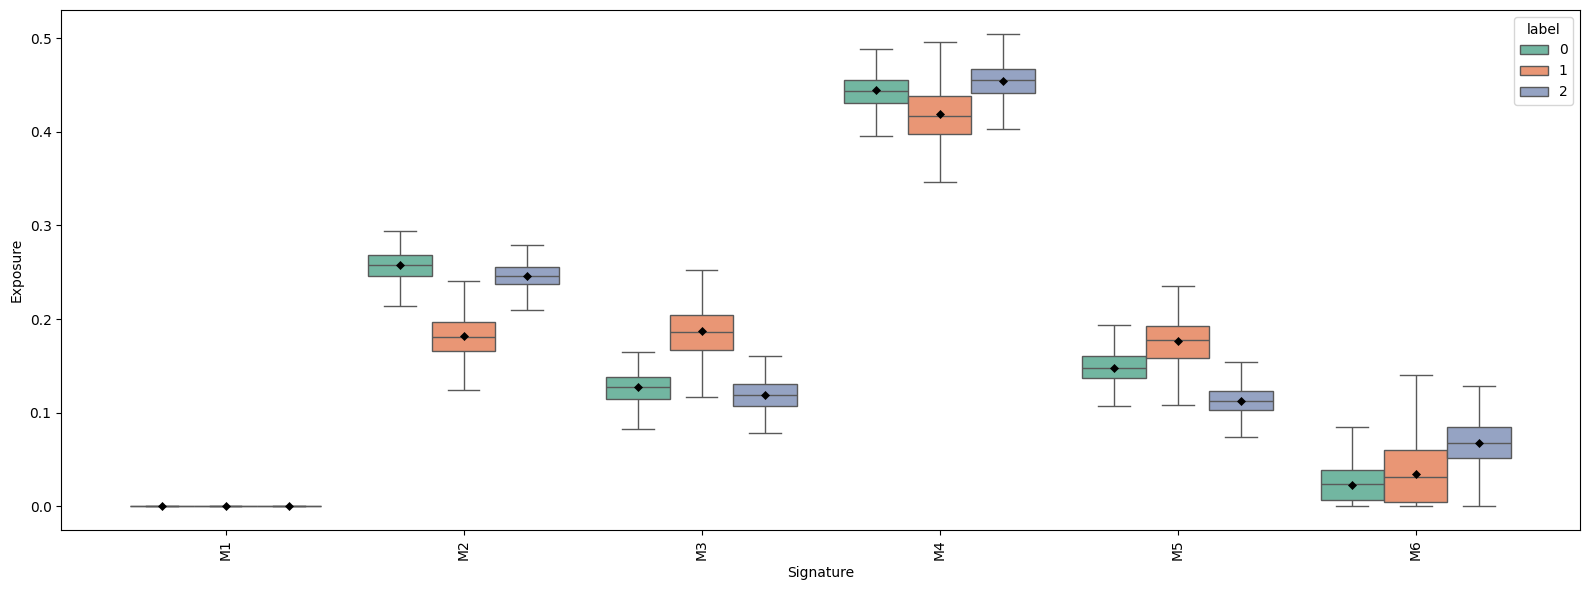




 ###  SA1053  ### 
number of cells: 825
Cluster B   -1    0   1    2
Cluster A                   
-1         150   71  33   56
 0          78  163   3    4
 1          44    6  17   17
 2          44    3  13  123
cosine similarity siluette score: 0.2739323675632477
Hellinger siluette score: 0.3089737296104431


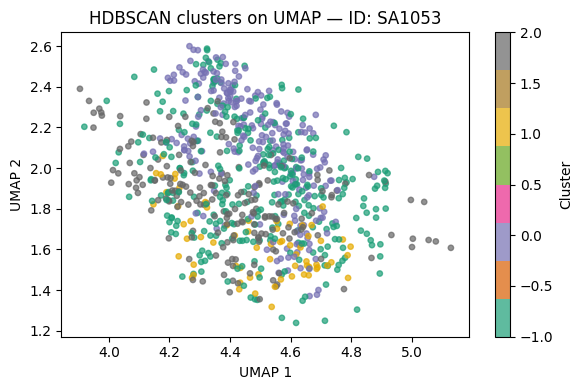

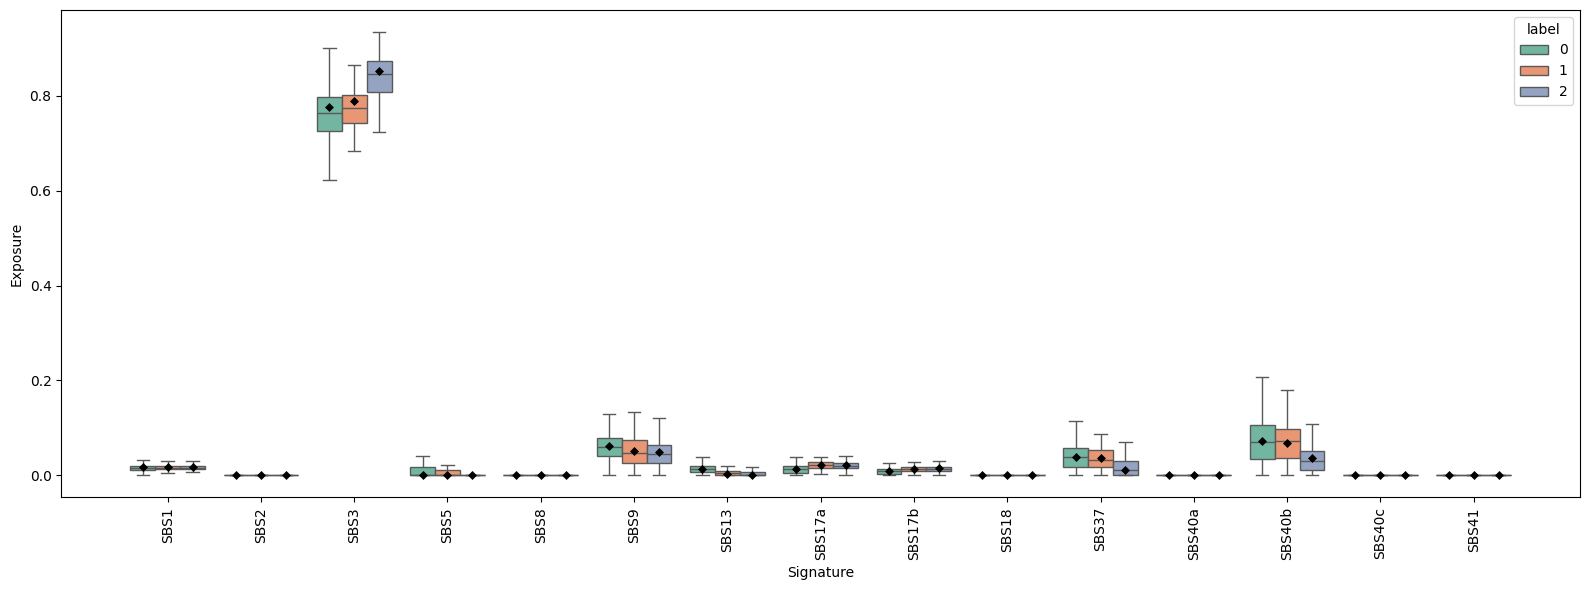

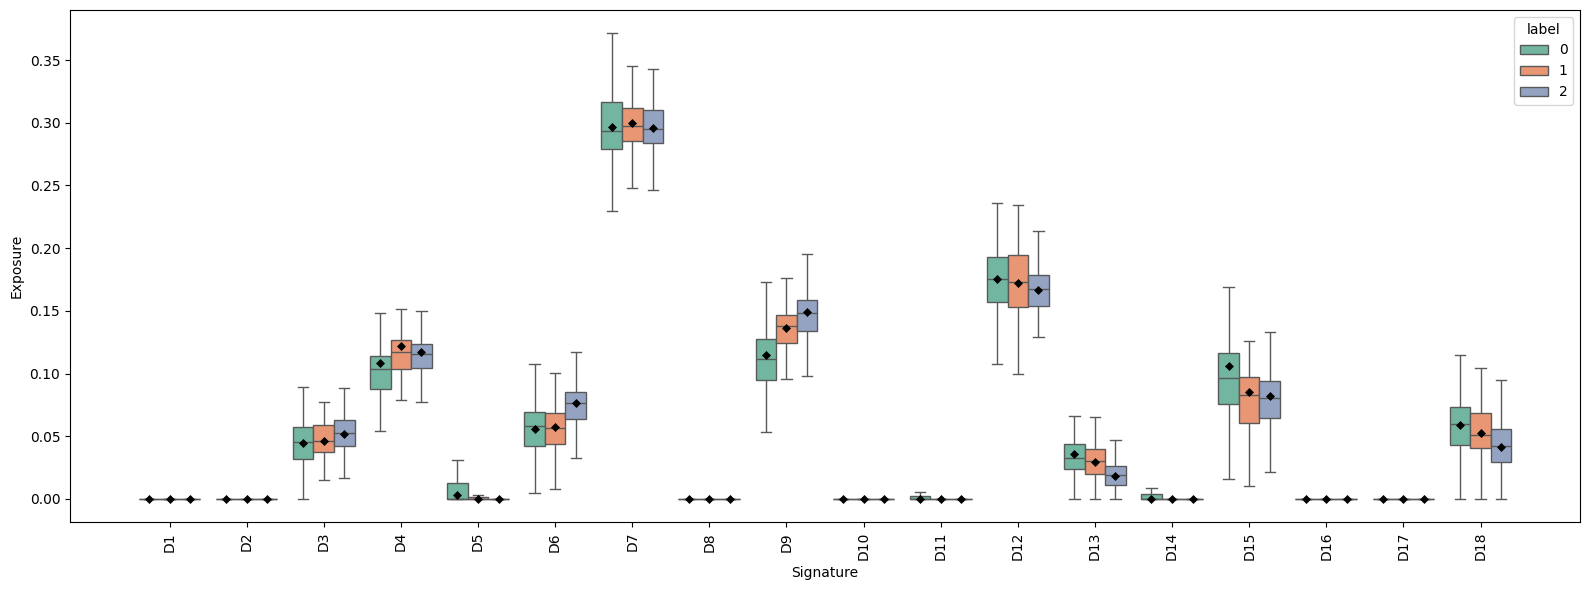

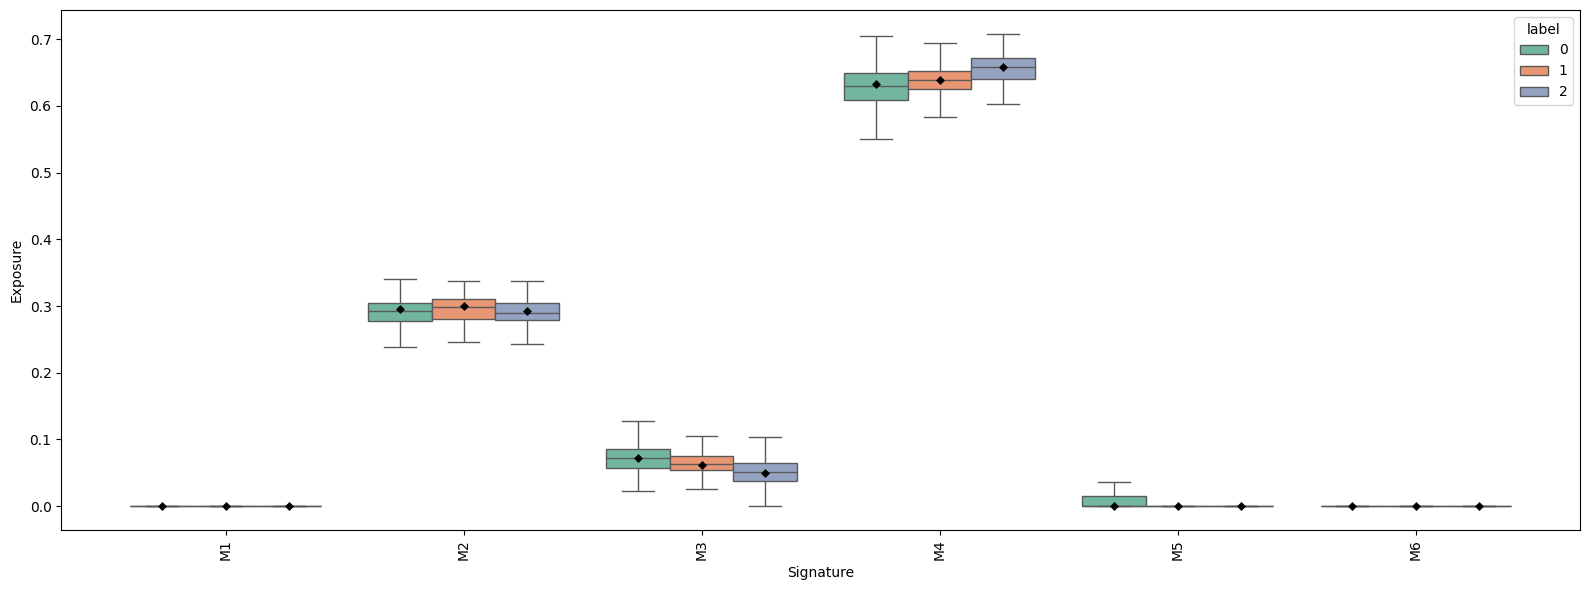




 ###  SA605  ### 
number of cells: 65
Cluster B  -1
Cluster A    
-1         65
ERROR for SA605: Silhouette score requires at least 2 clusters.



 ###  SA610  ### 
number of cells: 268
Cluster B  -1   0    1
Cluster A             
-1         16  38  101
 0          7   4   38
 1          7  18   39
cosine similarity siluette score: 0.32348373532295227
Hellinger siluette score: 0.14549778401851654


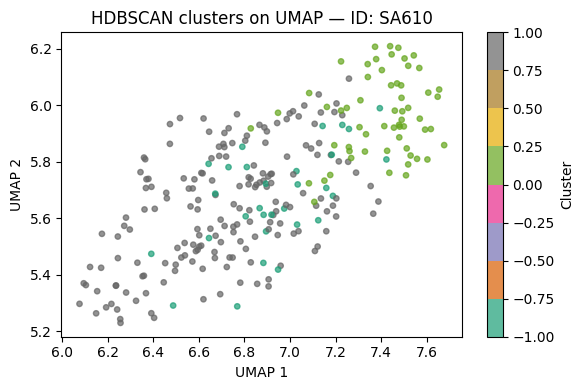

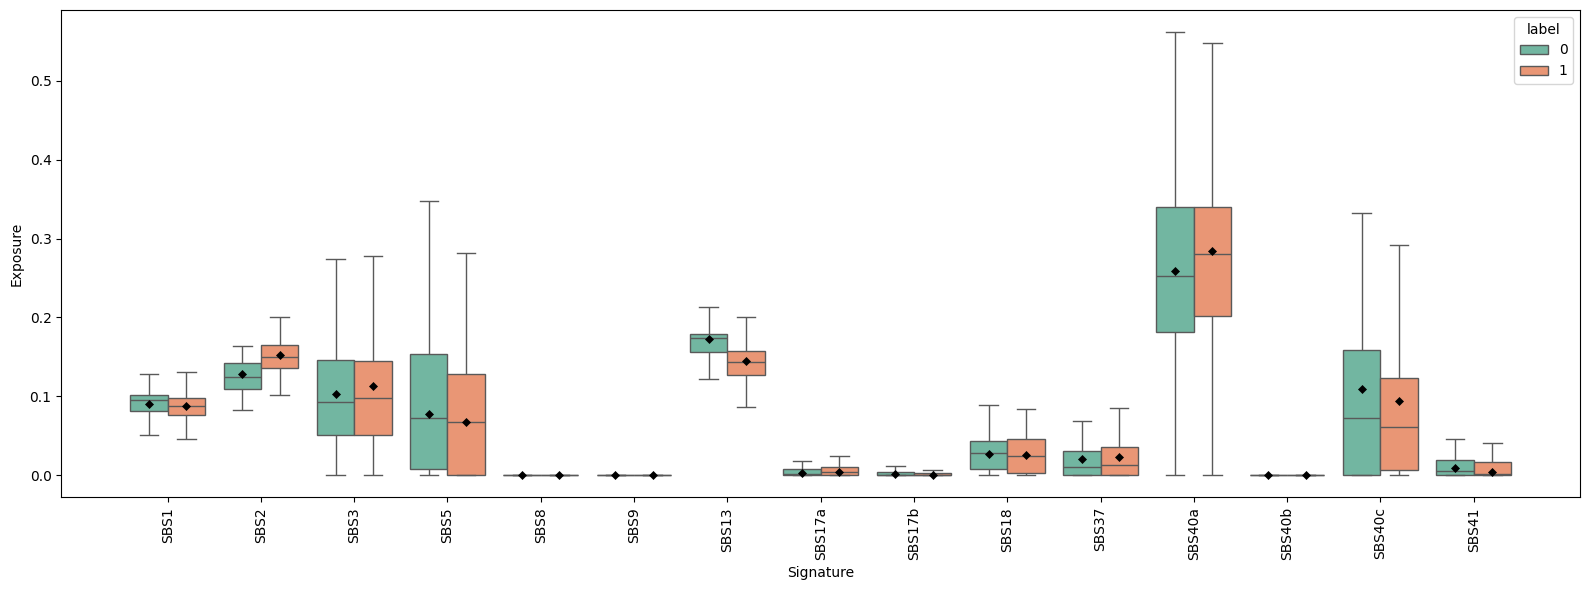

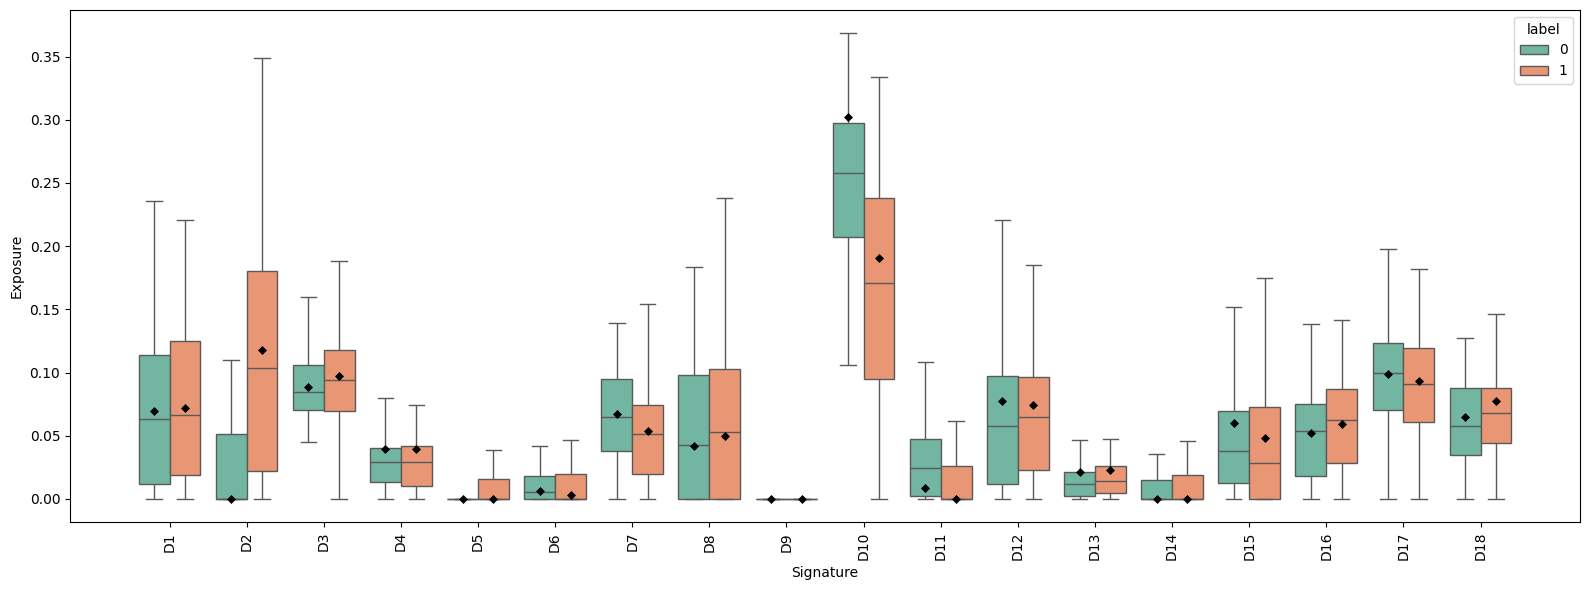

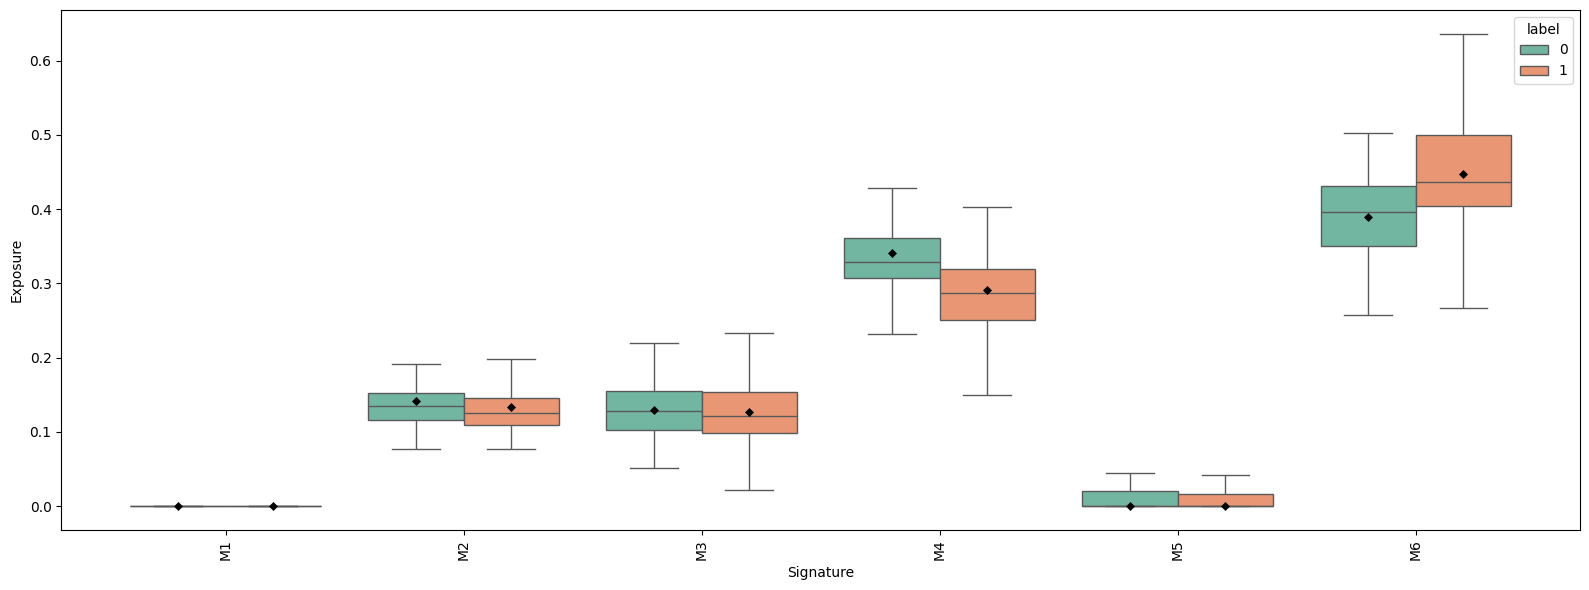




 ###  SA535  ### 
number of cells: 1801
Cluster B    0     1
Cluster A           
0          281     0
1            0  1520
cosine similarity siluette score: 0.9223642349243164
Hellinger siluette score: 0.9231685400009155


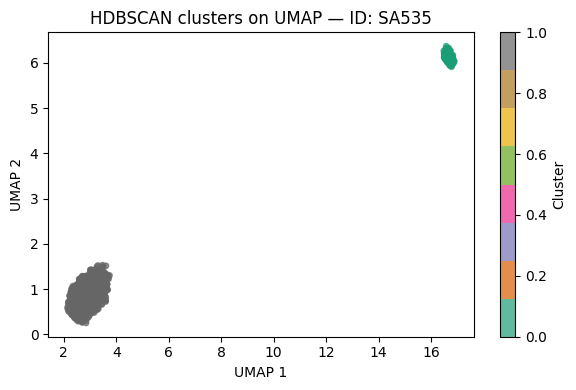

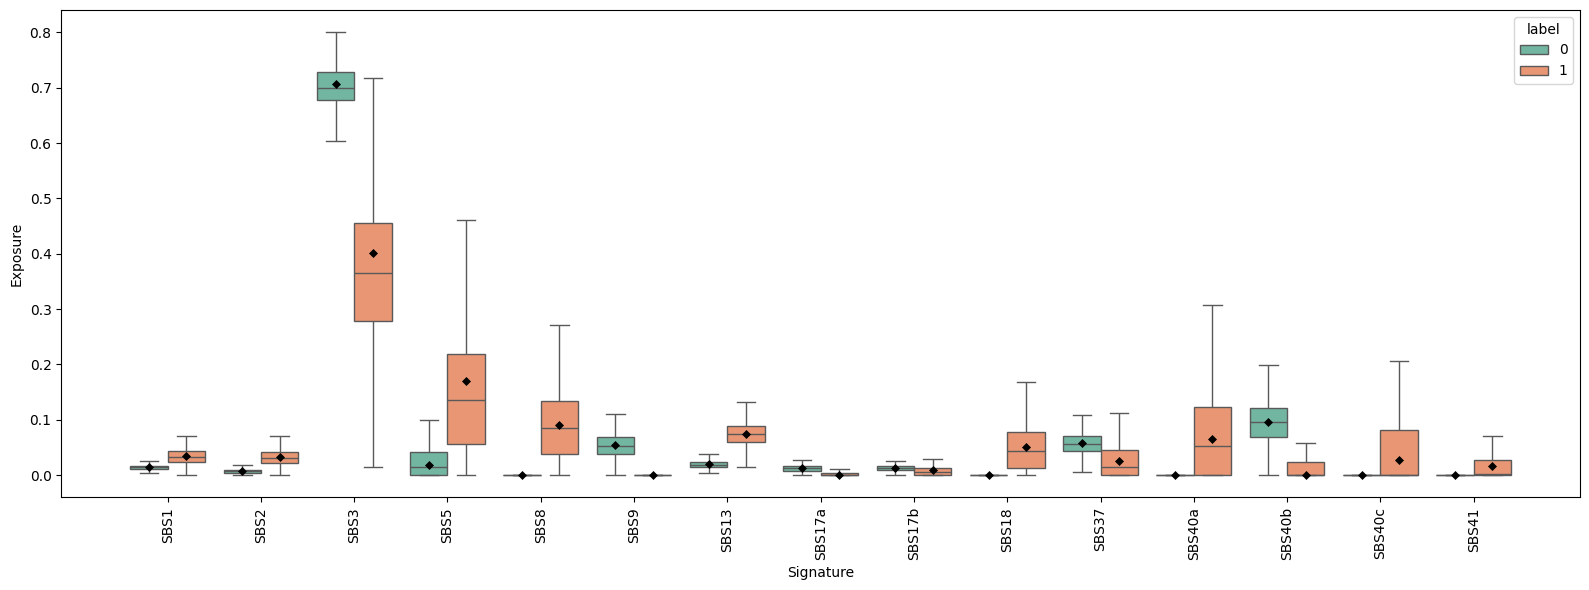

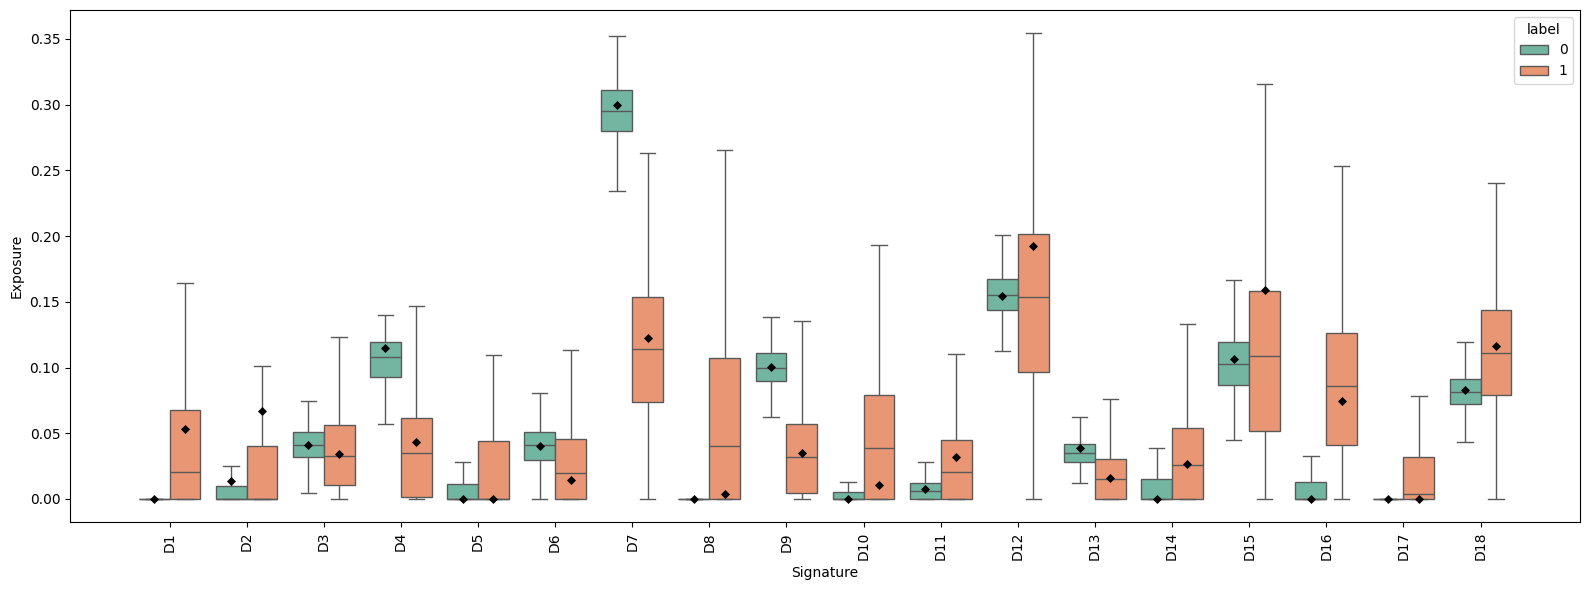

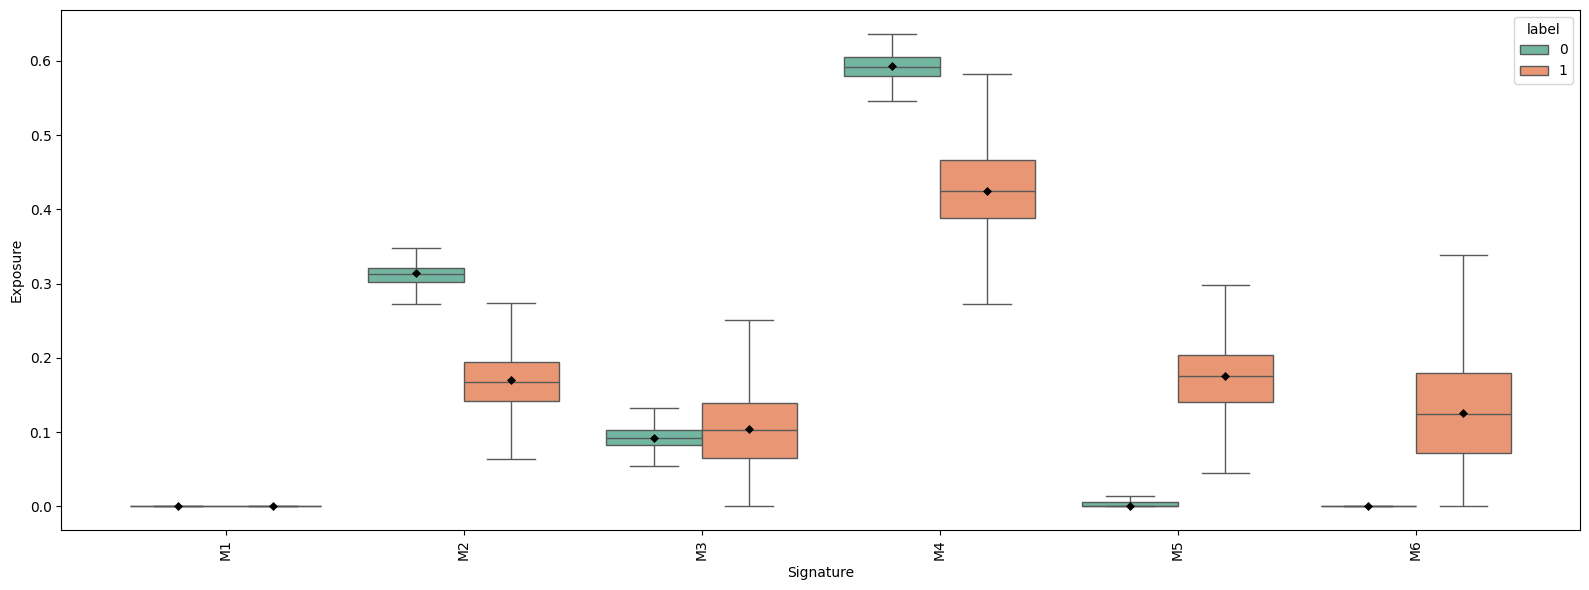




 ###  SA1035  ### 
number of cells: 2586
Cluster B     0    1
Cluster A           
0          1707   20
1             1  858
cosine similarity siluette score: 0.90118807554245
Hellinger siluette score: 0.9245892763137817


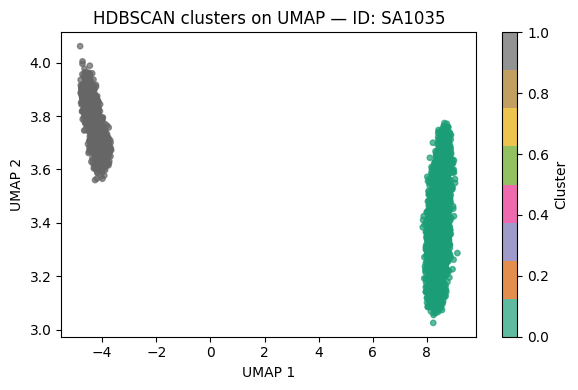

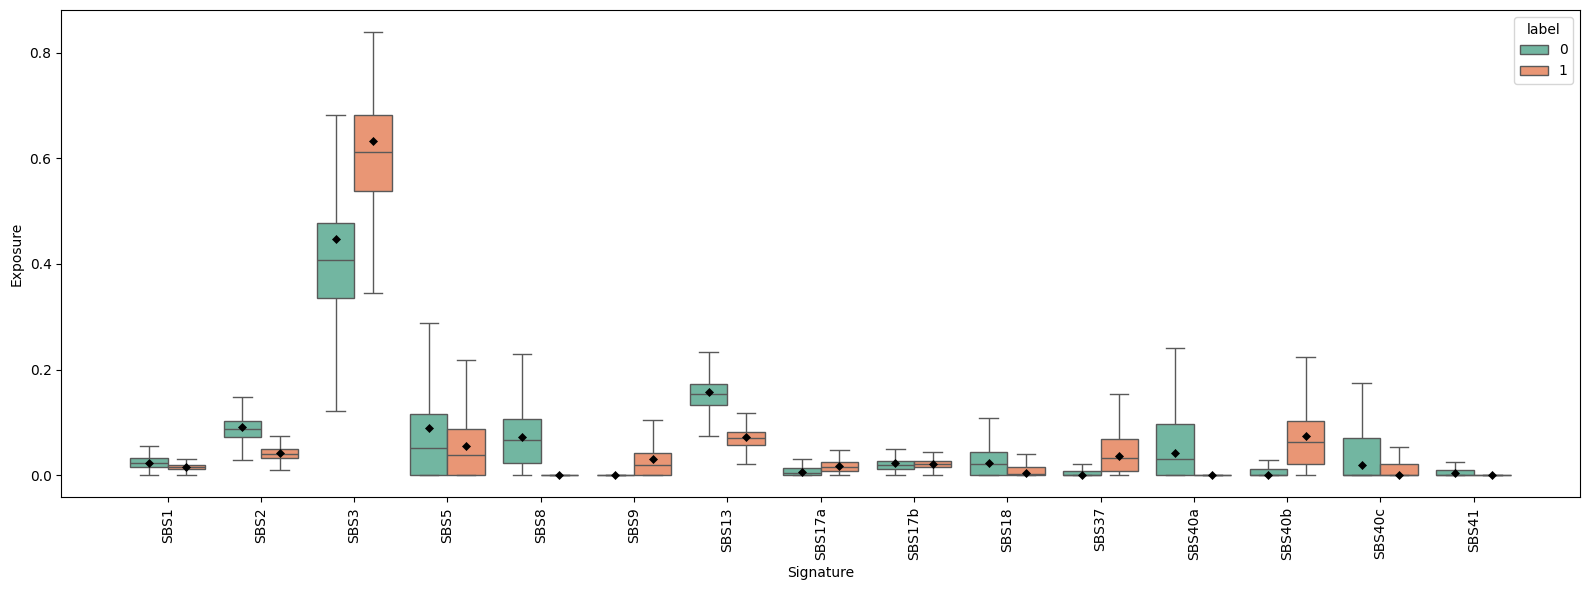

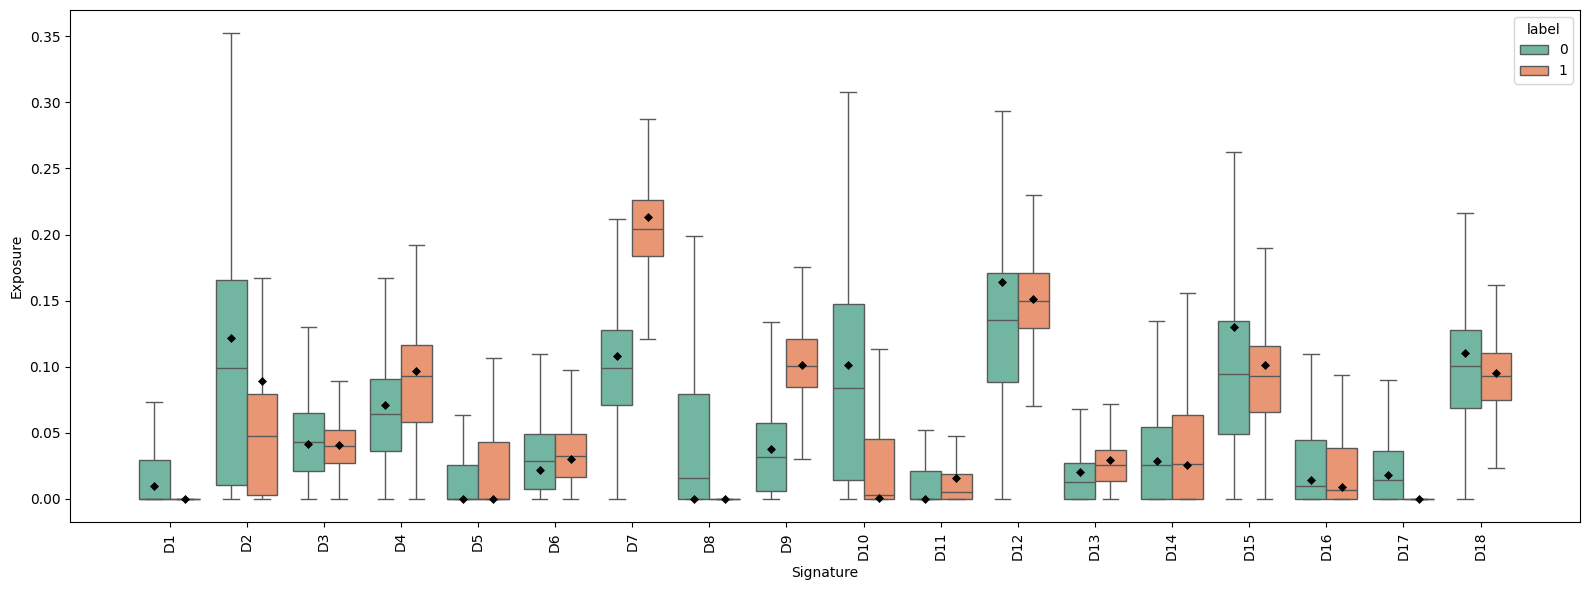

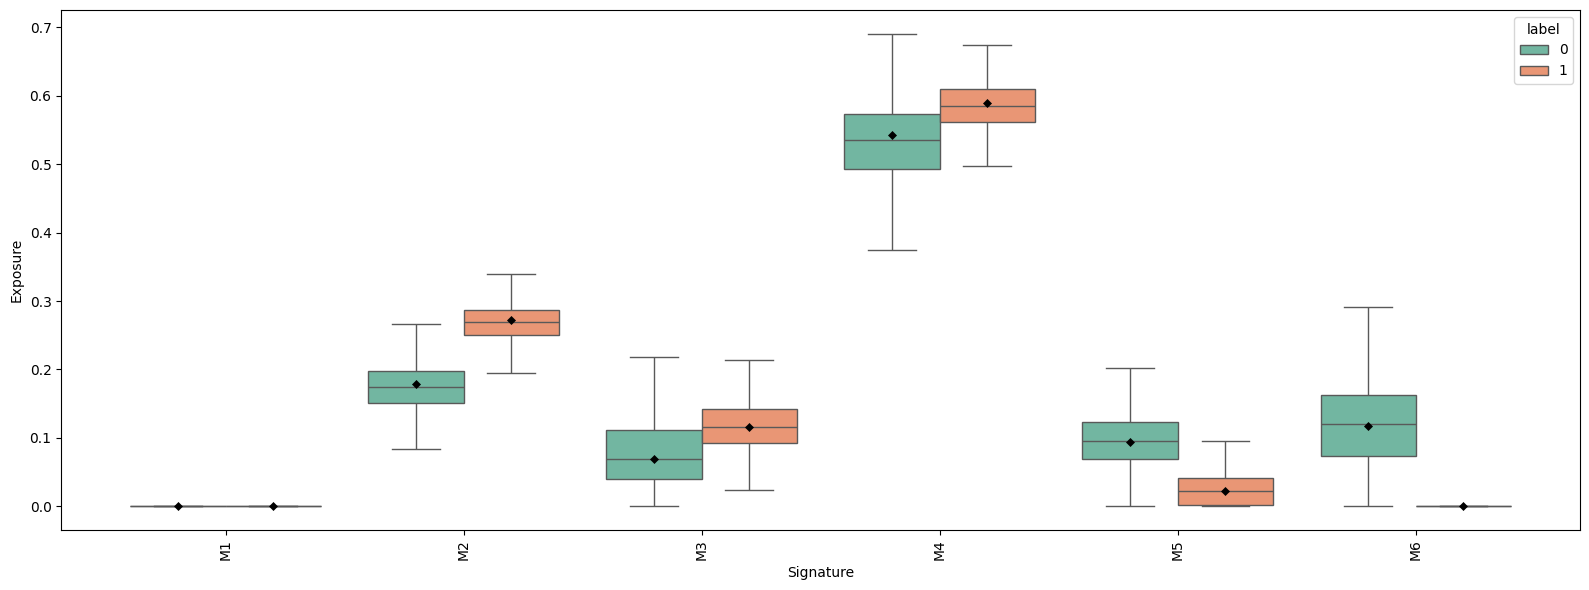




 ###  SA1051  ### 
number of cells: 892
Cluster B   -1    0   1   2
Cluster A                  
-1         162   13   8   8
 0          31    0   3   2
 1         407  136  77  45
cosine similarity siluette score: 0.2650642395019531
Hellinger siluette score: -0.005373070947825909


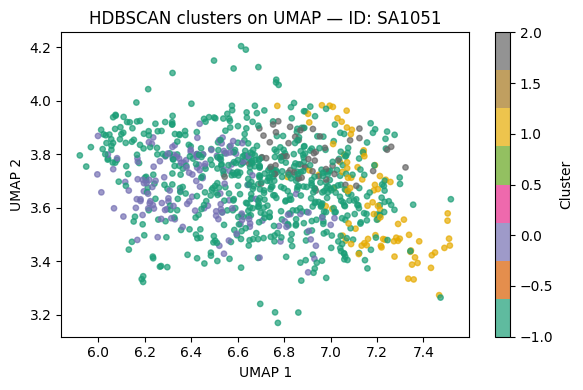

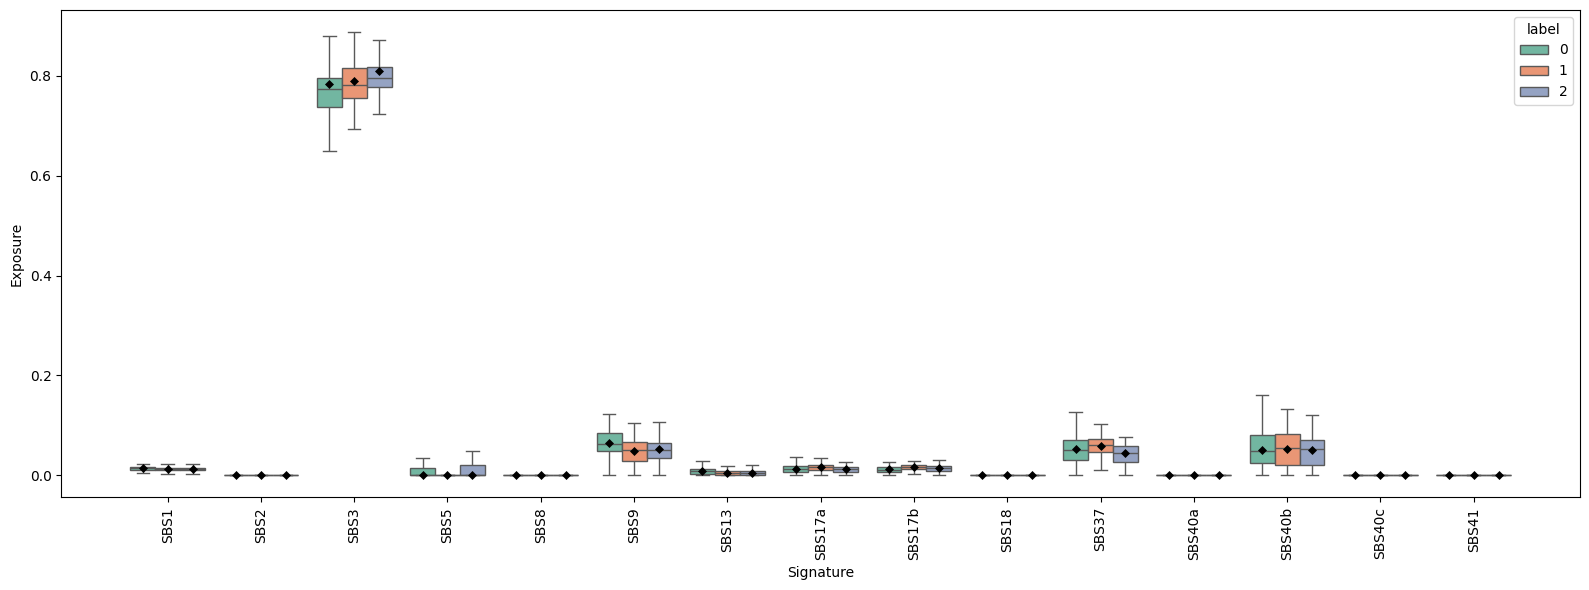

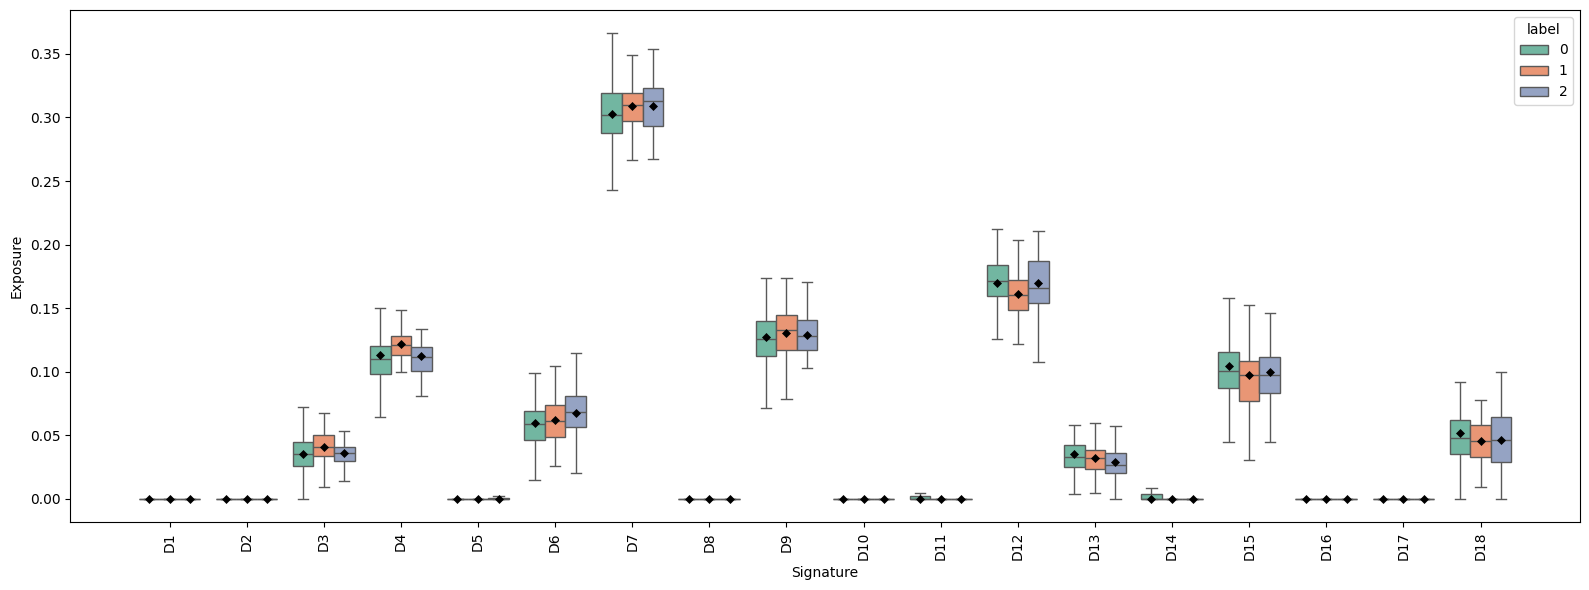

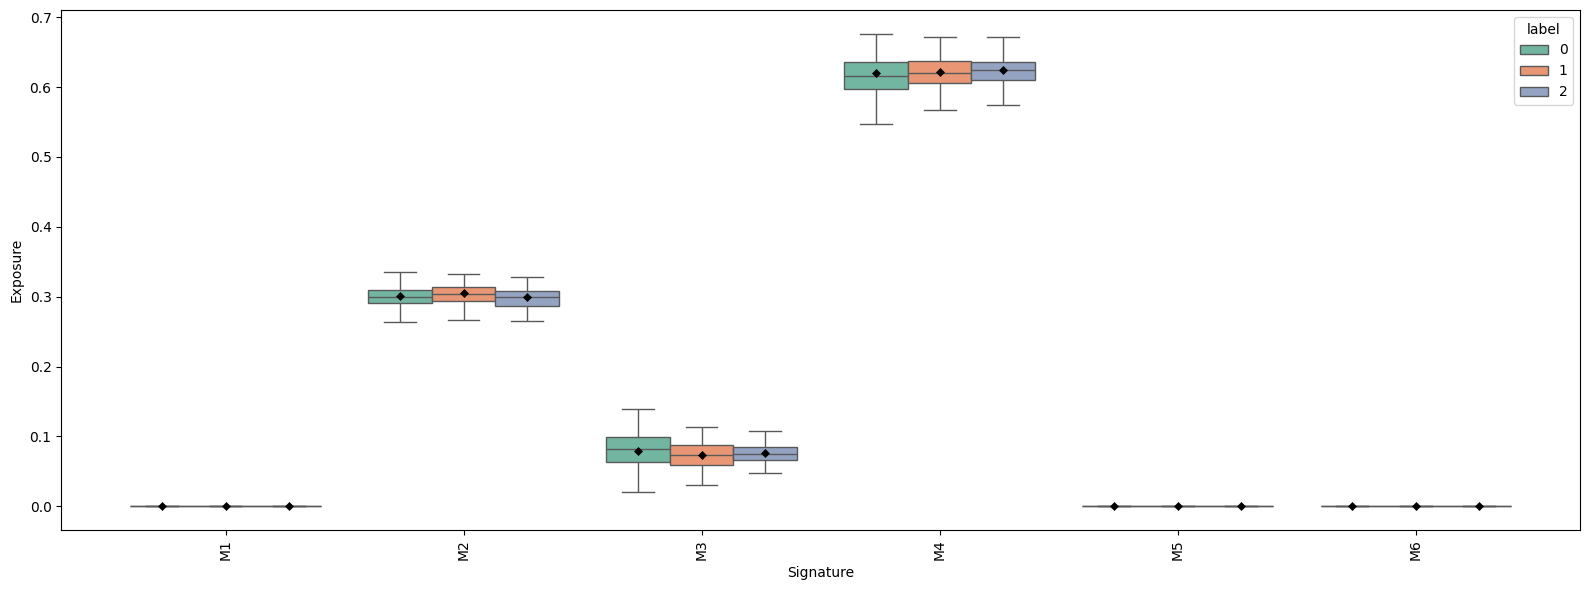




 ###  SA1056  ### 
number of cells: 496
Cluster B   -1   0   1   2   3
Cluster A                     
-1         175  21  20  29  19
 0         102  17  20  26  15
 1          26   2   1  14   9
cosine similarity siluette score: 0.2625690996646881
Hellinger siluette score: 0.08553735166788101


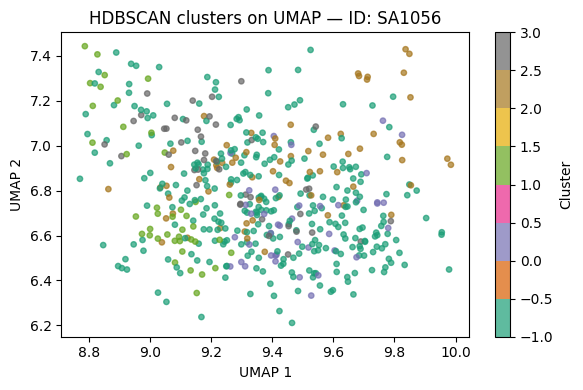

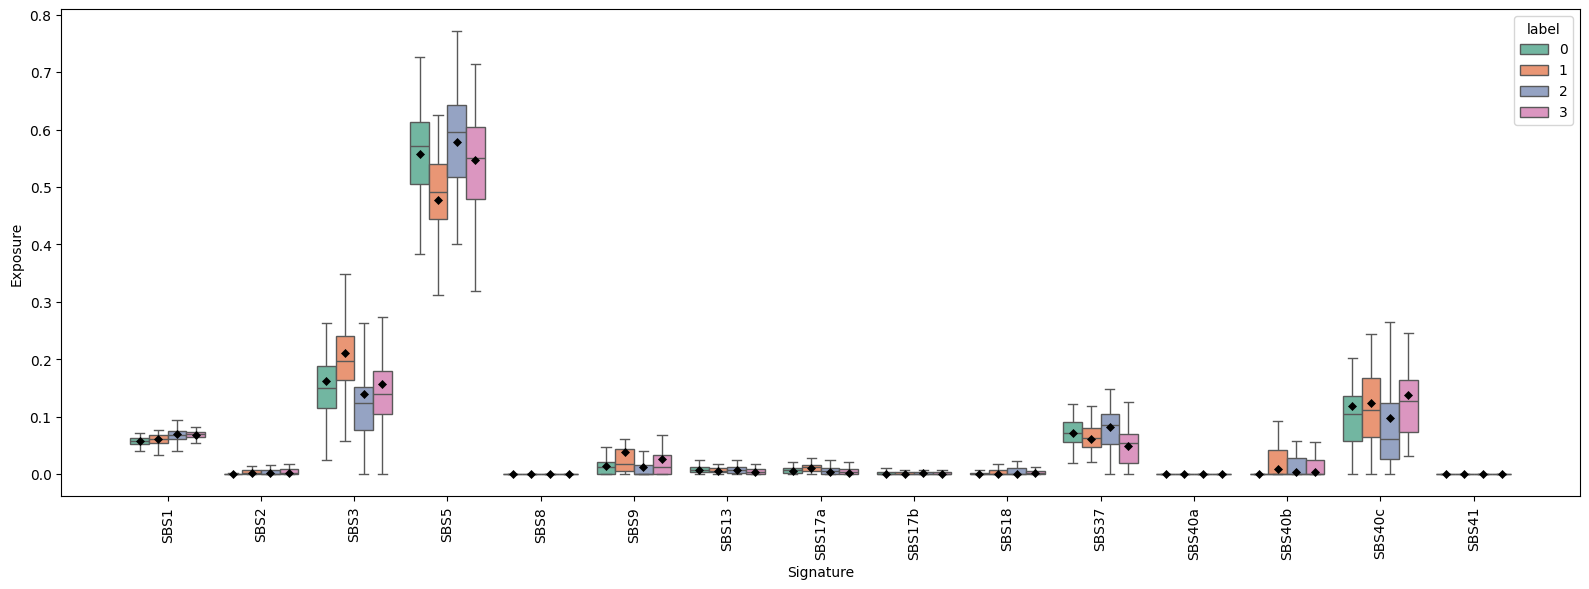

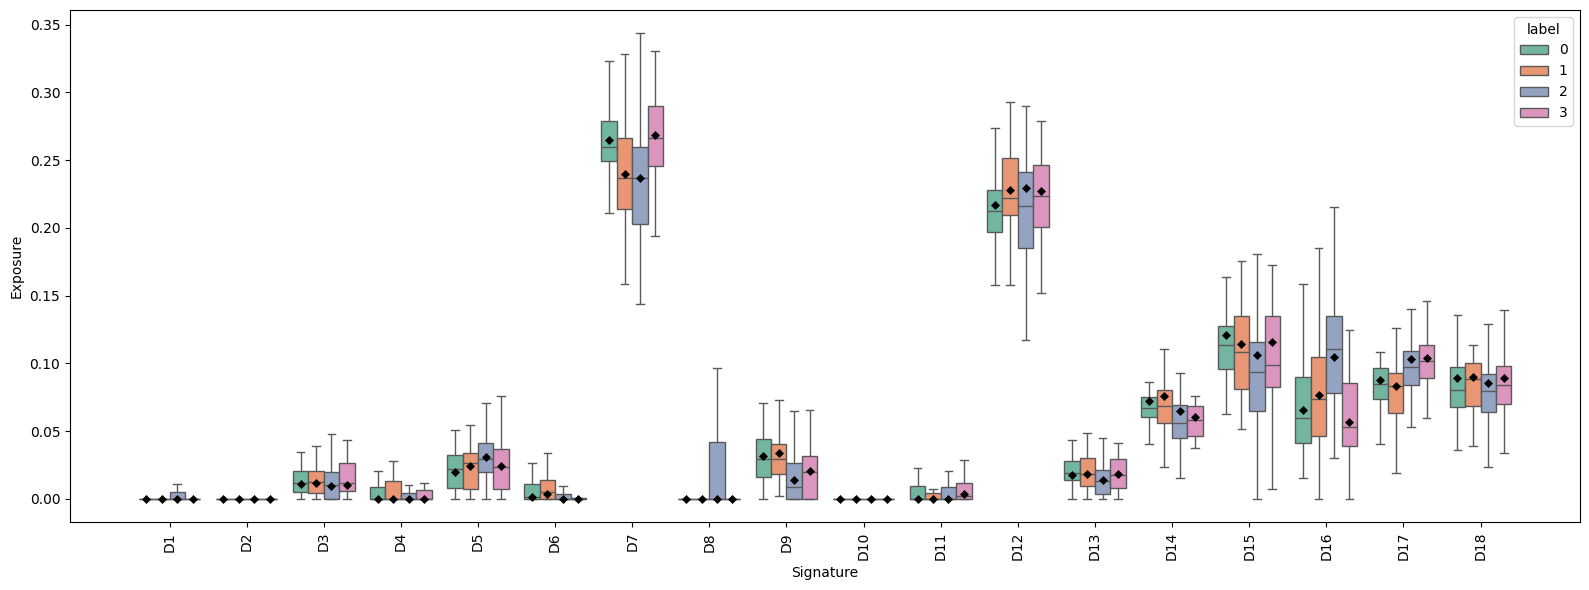

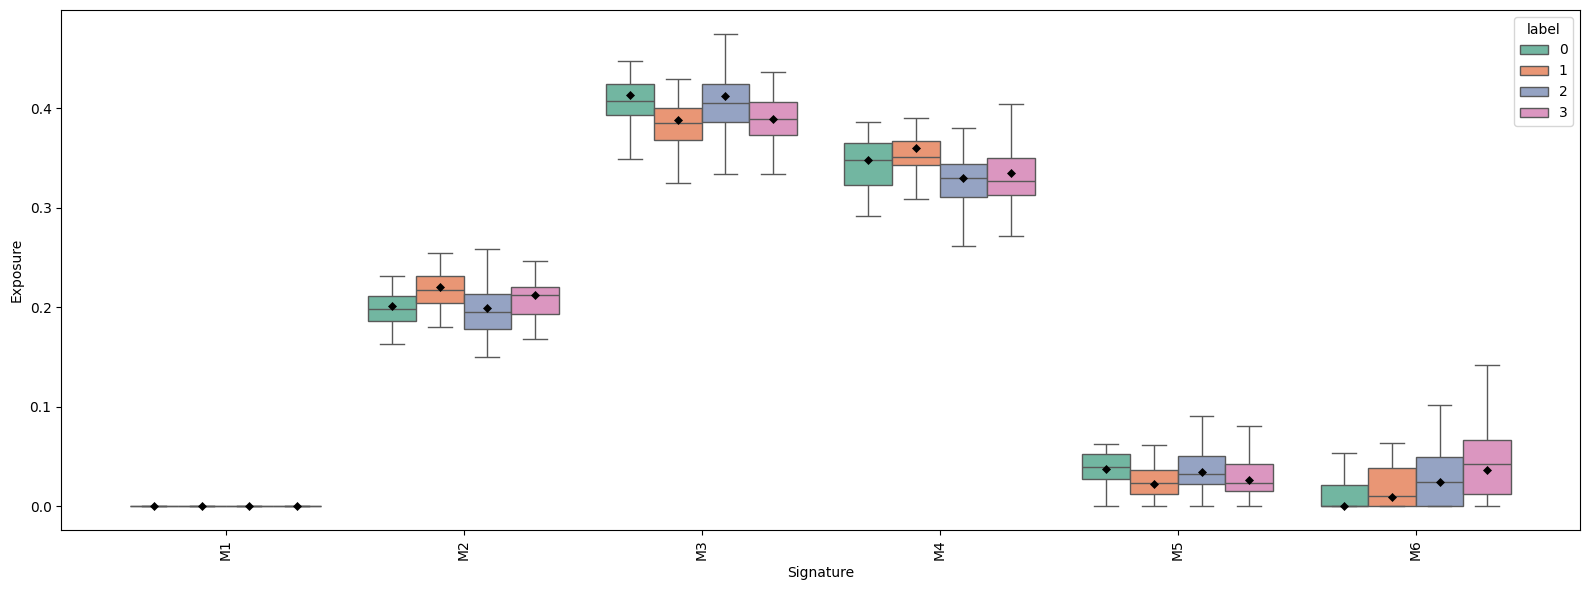




 ###  SA039  ### 
number of cells: 1959
Cluster B  -1    0    1
Cluster A              
-1         12  157  303
 0          6   21  770
 1          2  669   19
cosine similarity siluette score: 0.6433446407318115
Hellinger siluette score: 0.6165947914123535


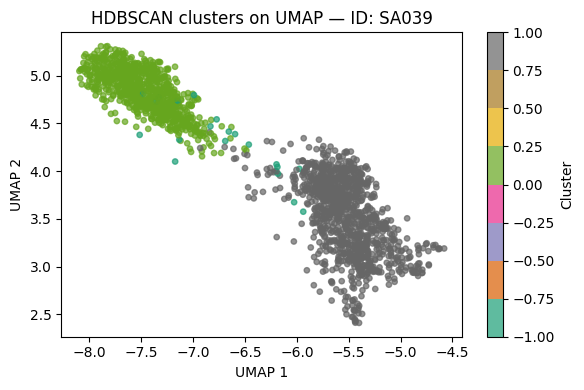

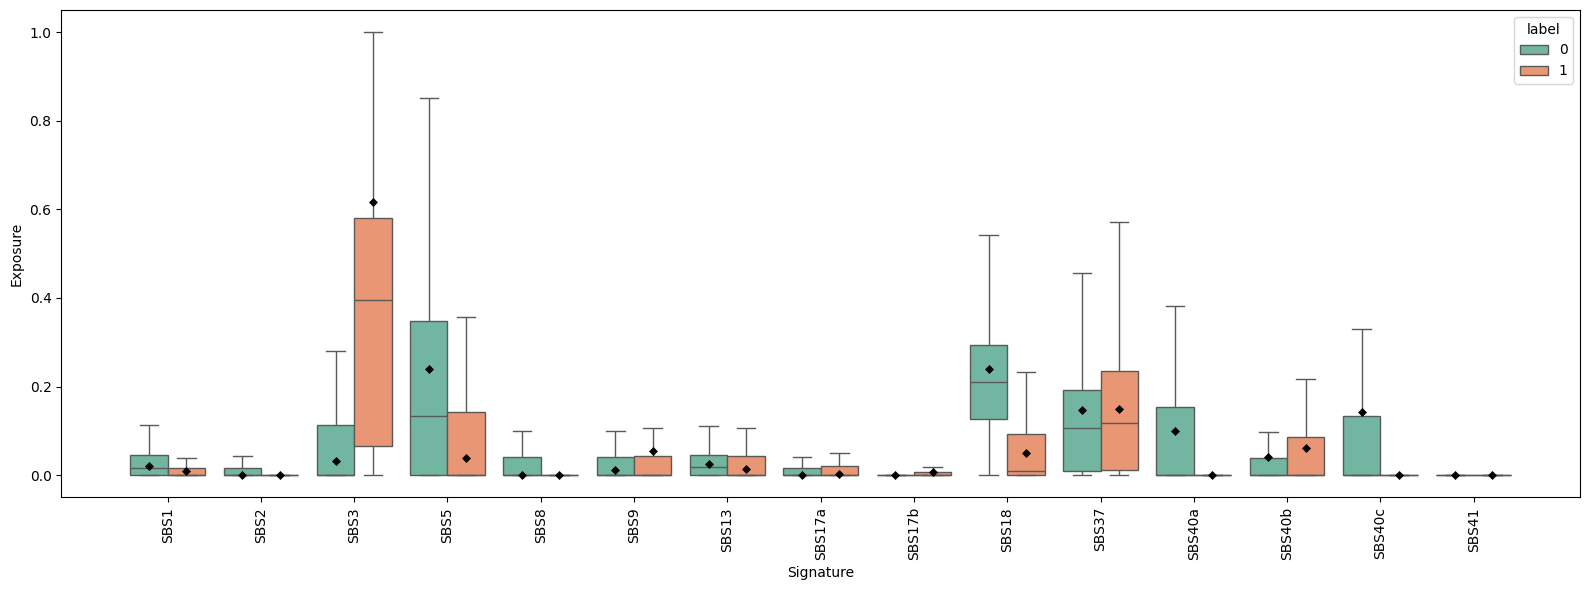

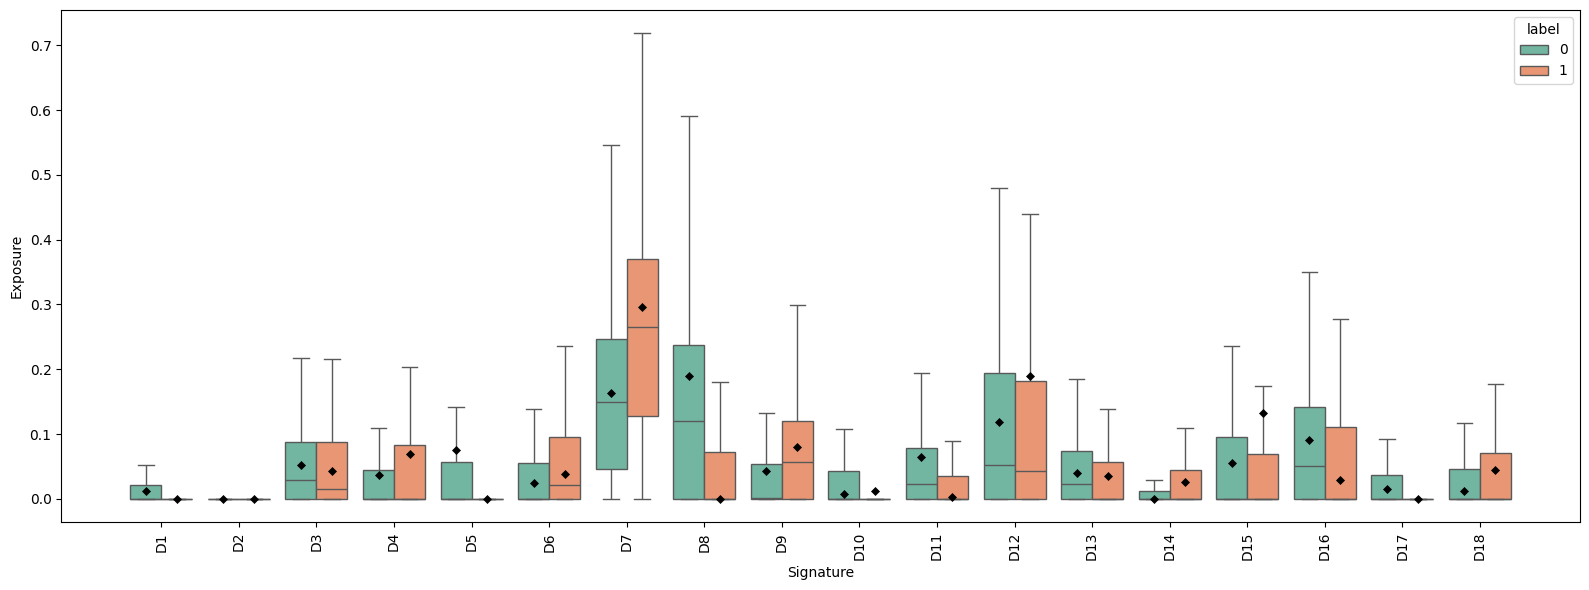

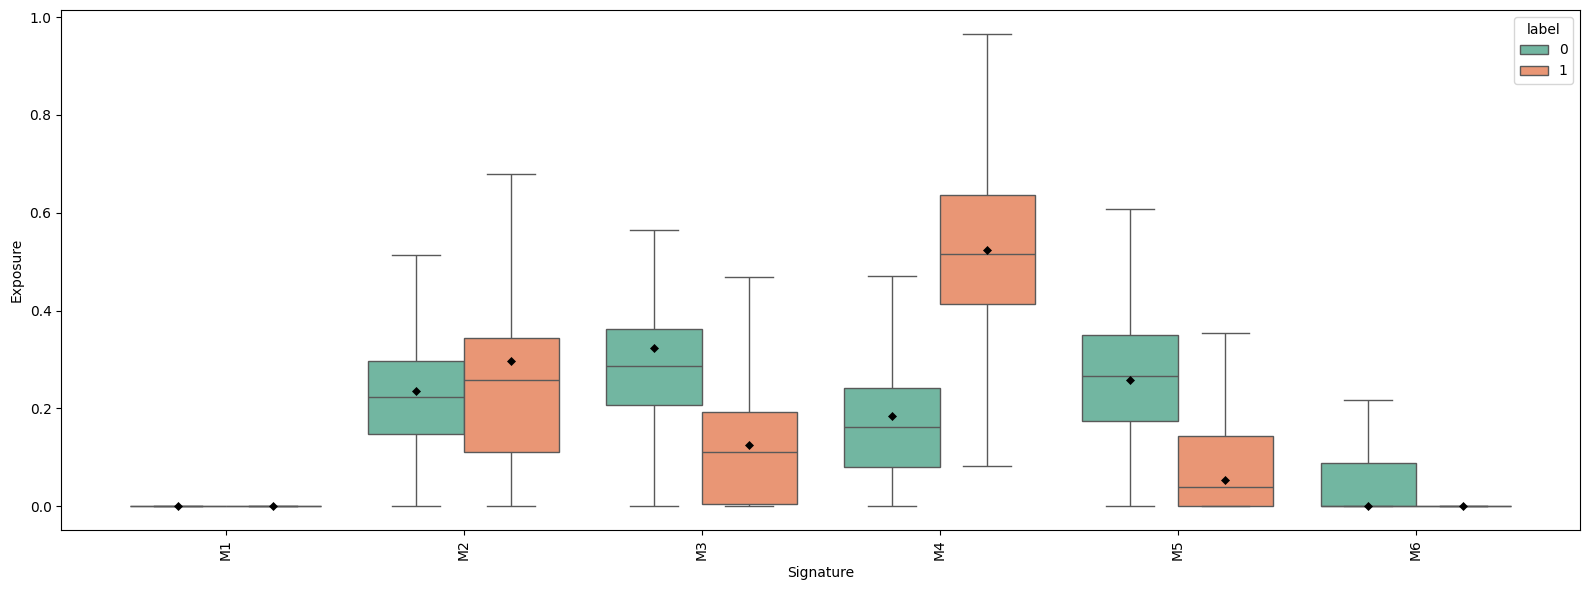




 ###  SA609  ### 
number of cells: 5993
Cluster B  -1    0     1
Cluster A               
-1          5   36  3623
 0          0    0    32
 1          0    0    32
 2          0    0    39
 3          0    0   400
 4          0    0   500
 5          0    0    35
 6          0    0   186
 7          0  452    64
 8          0    0    52
 9          0    1   536
cosine similarity siluette score: 0.5701236128807068
Hellinger siluette score: 0.4647957980632782


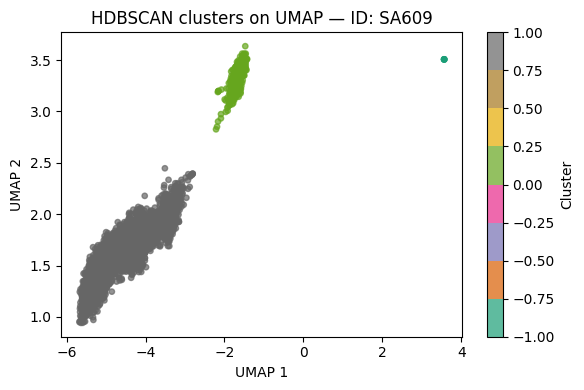

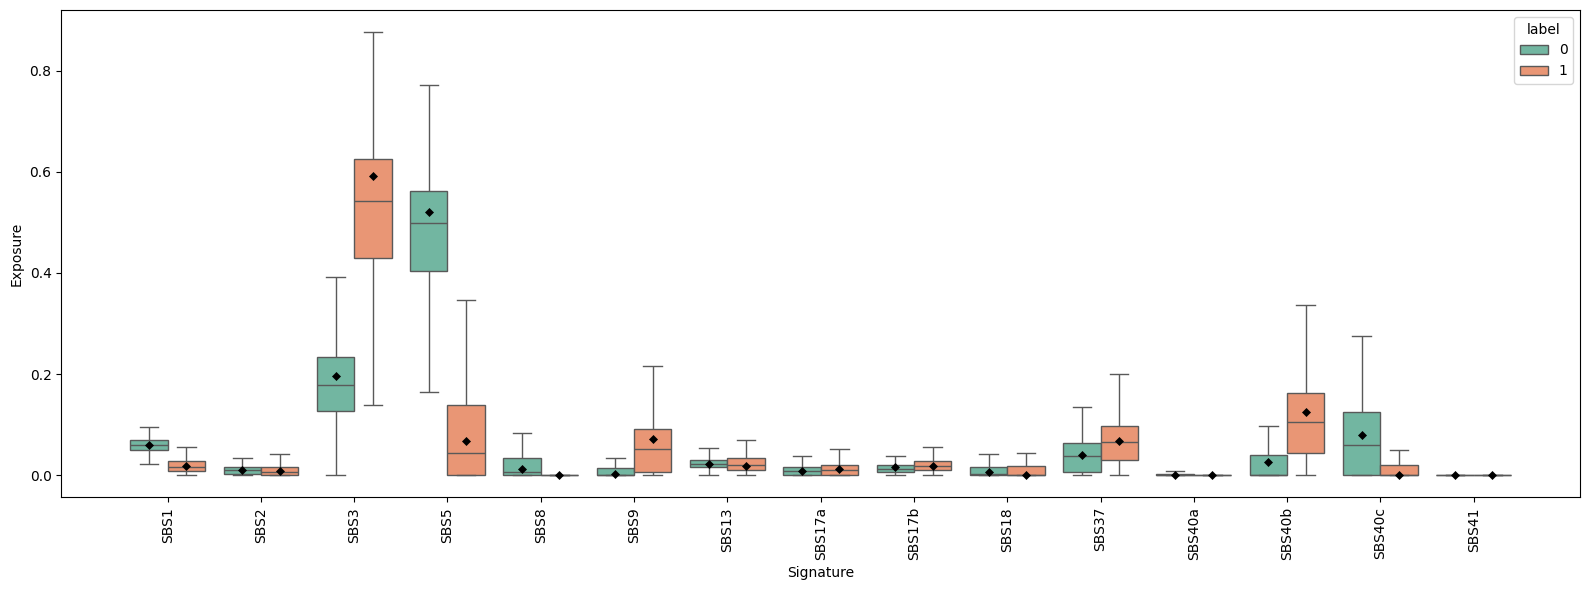

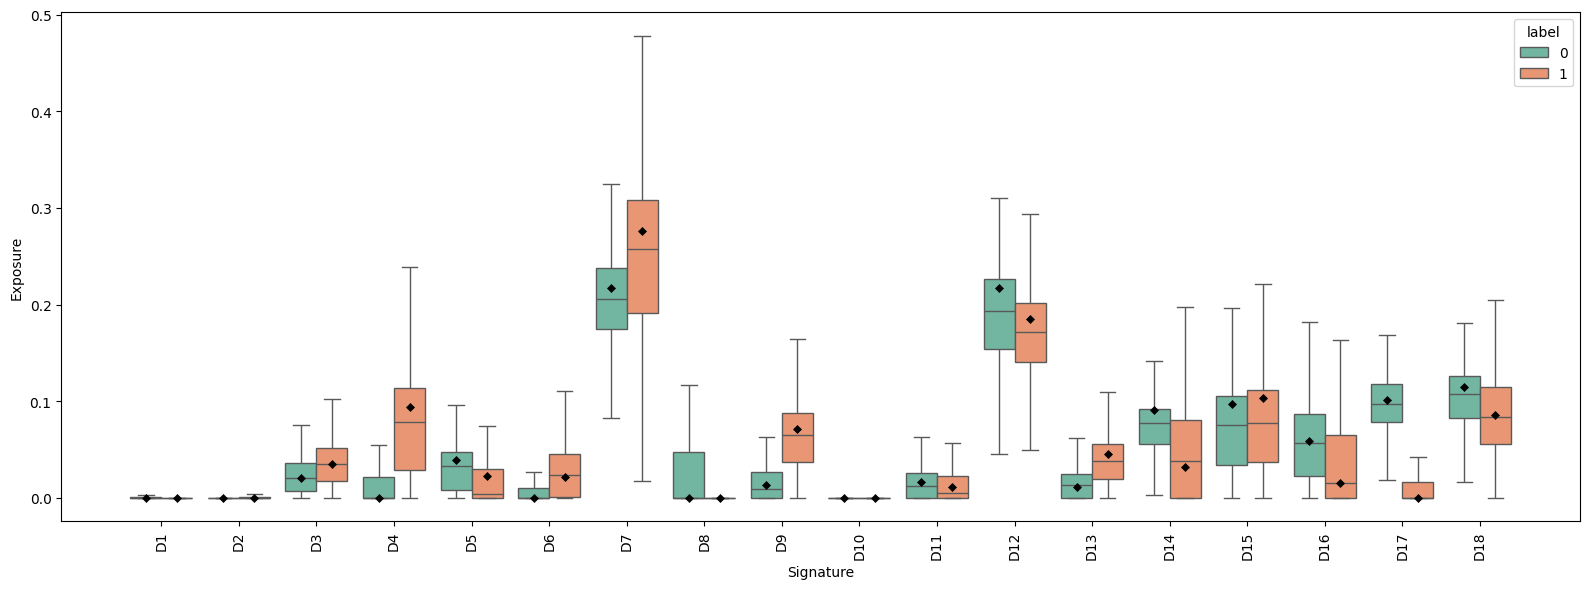

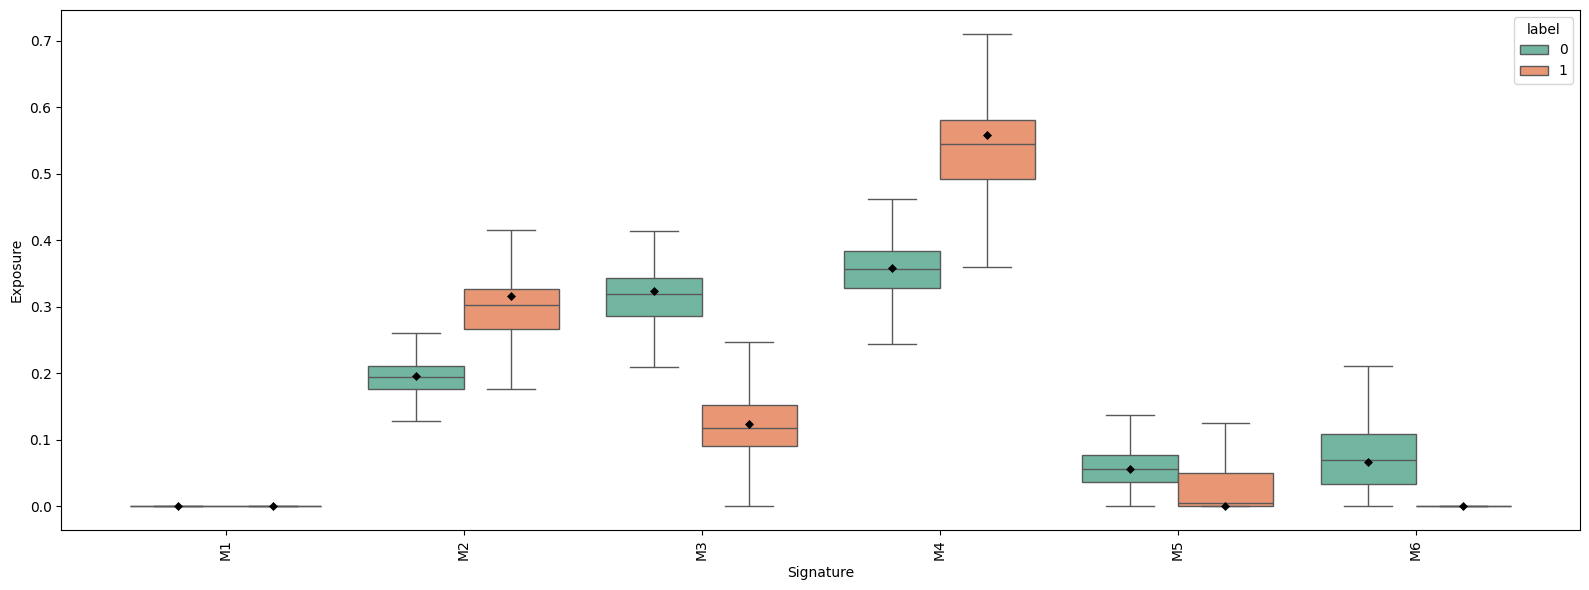




 ###  SA1050  ### 
number of cells: 990
Cluster B    0    1
Cluster A          
0          483    8
1            2  497
cosine similarity siluette score: 0.9270468354225159
Hellinger siluette score: 0.888730525970459


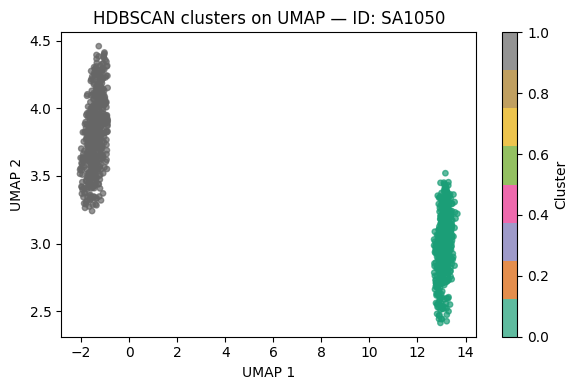

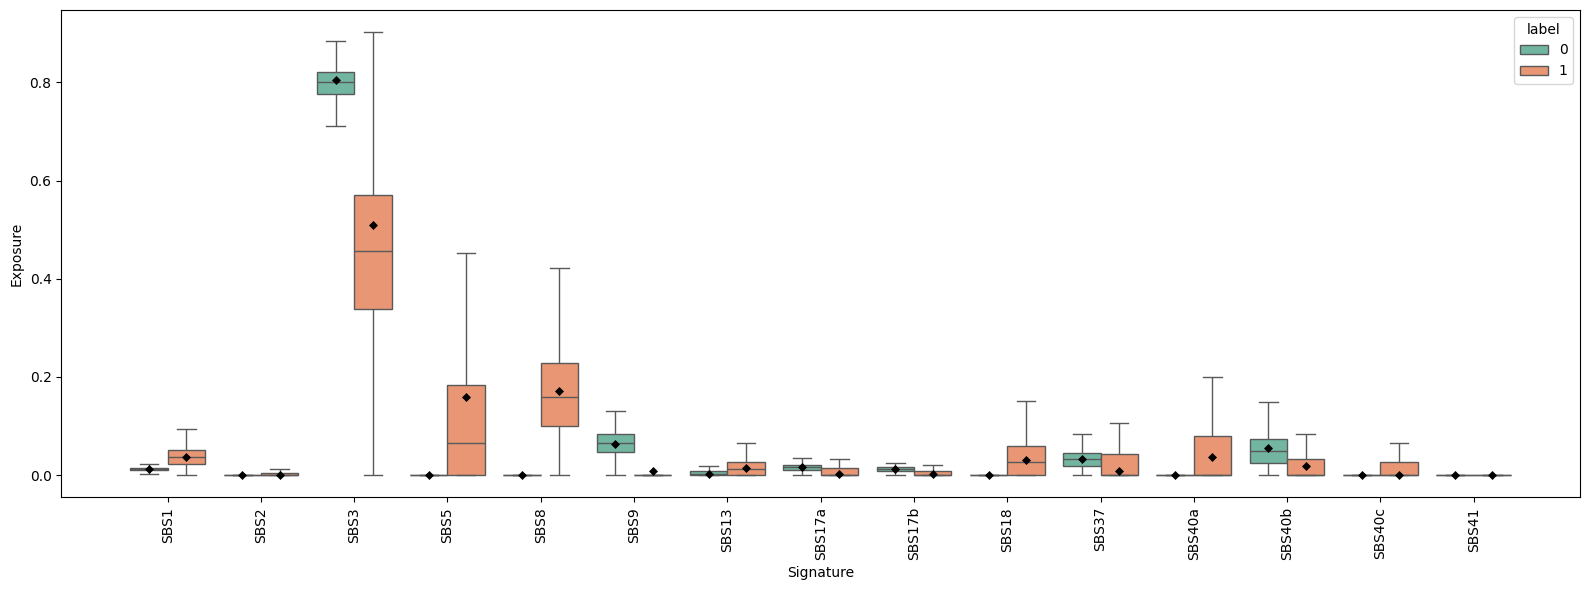

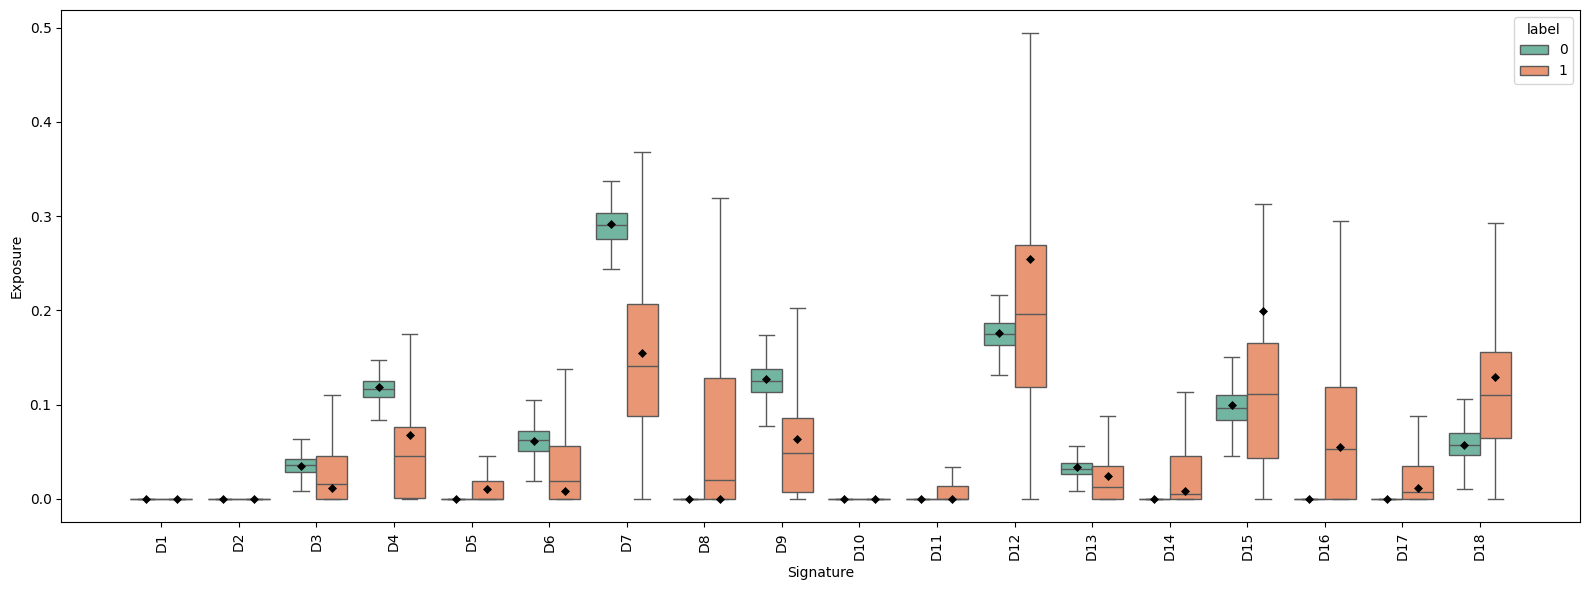

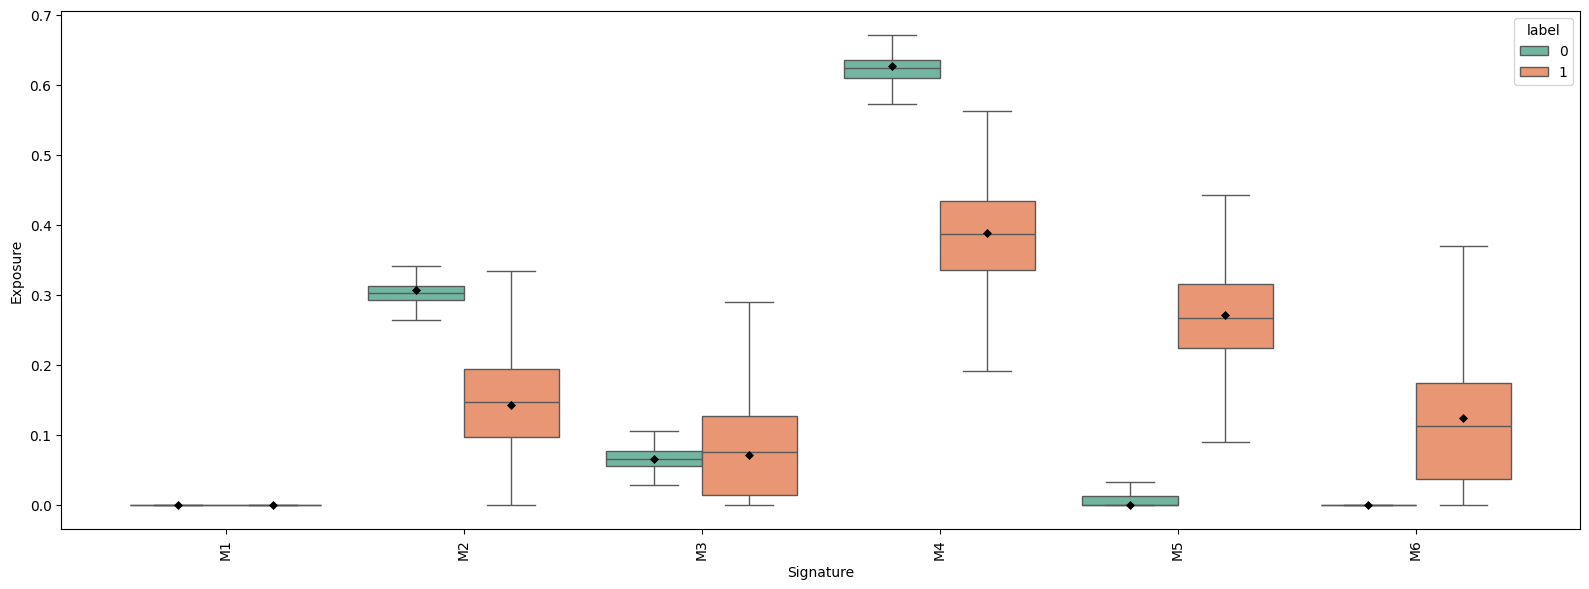




 ###  DG1134  ### 
number of cells: 113
Cluster B  -1   0   1
Cluster A            
-1         48  30  35
cosine similarity siluette score: 0.19563160836696625
ERROR for DG1134: Silhouette score requires at least 2 clusters.



 ###  SA1093  ### 
number of cells: 346
Cluster B  -1   0   1
Cluster A            
-1         80   9  61
 0         52  24  74
 1         22   3  21
cosine similarity siluette score: 0.11246629804372787
Hellinger siluette score: 0.1333559900522232


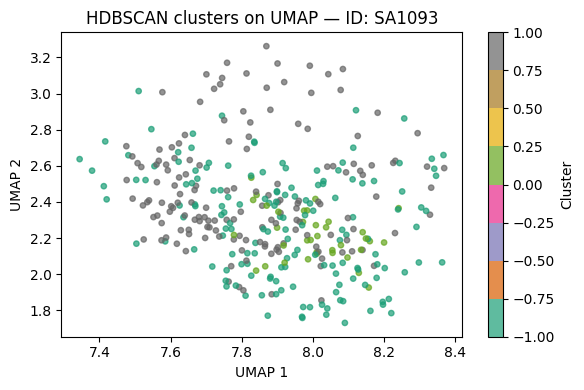

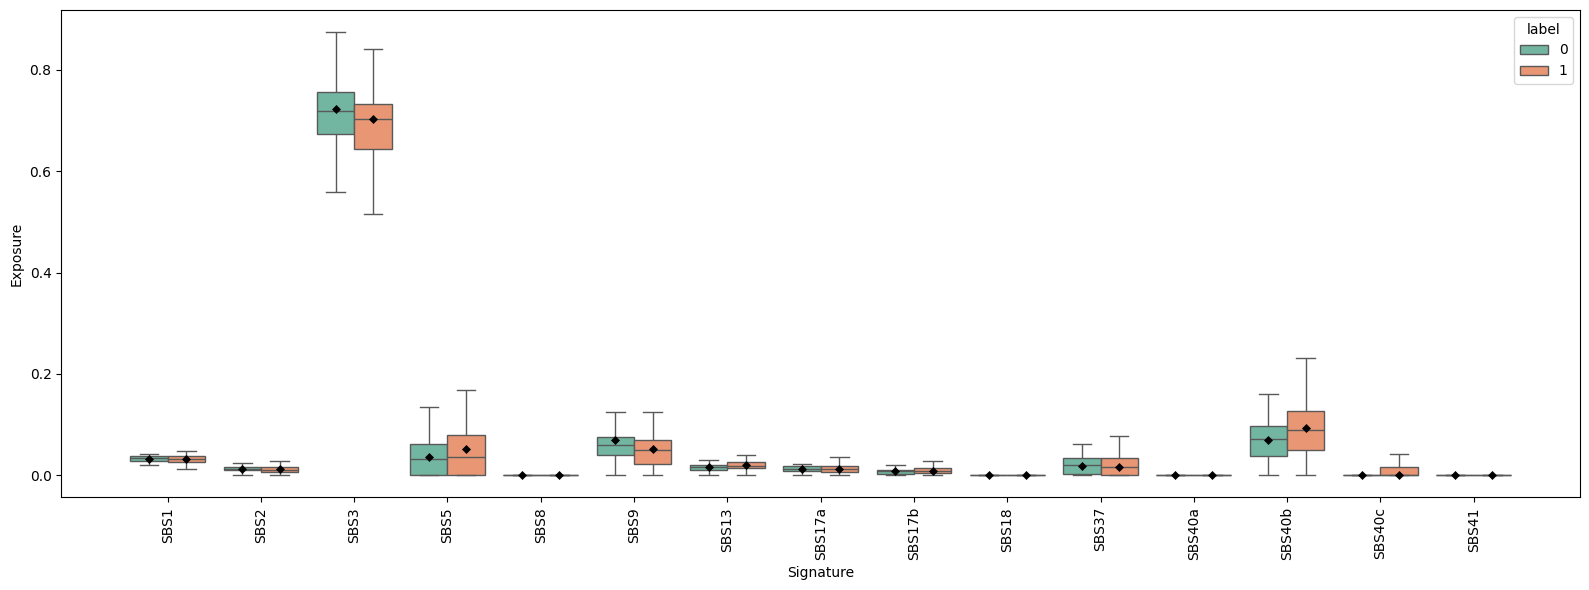

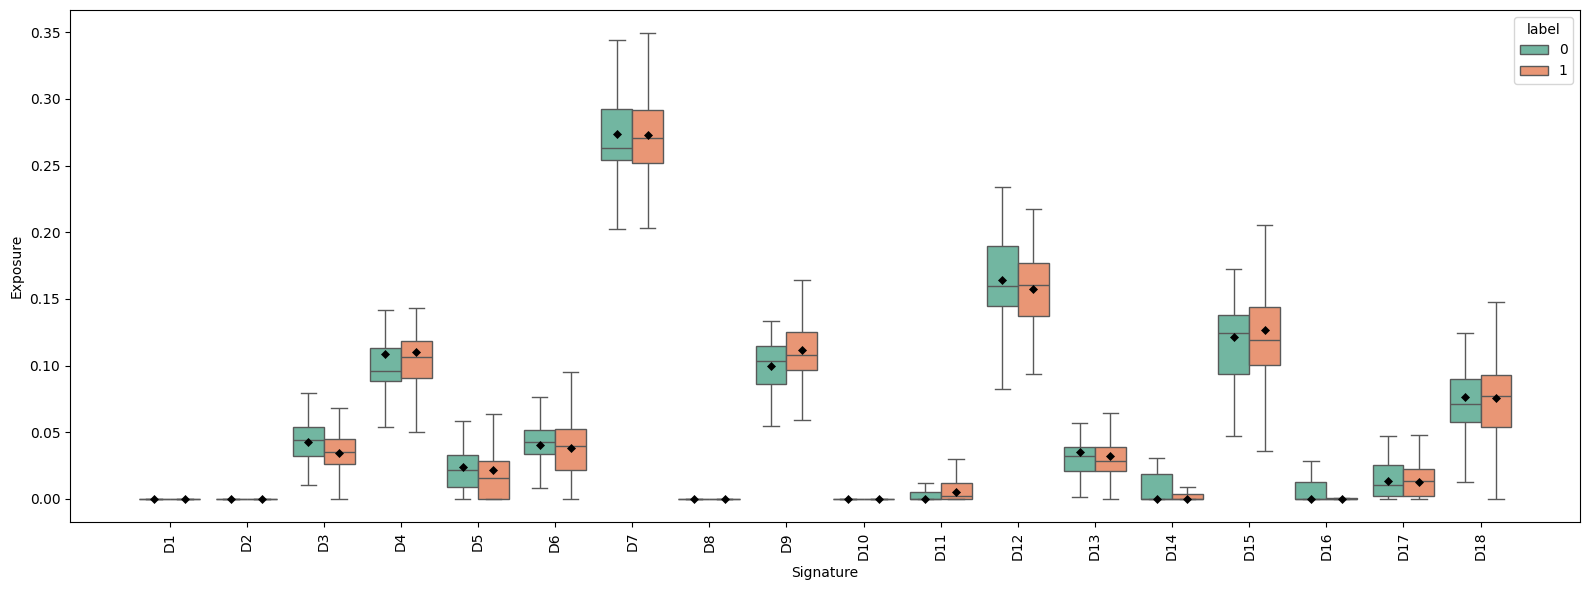

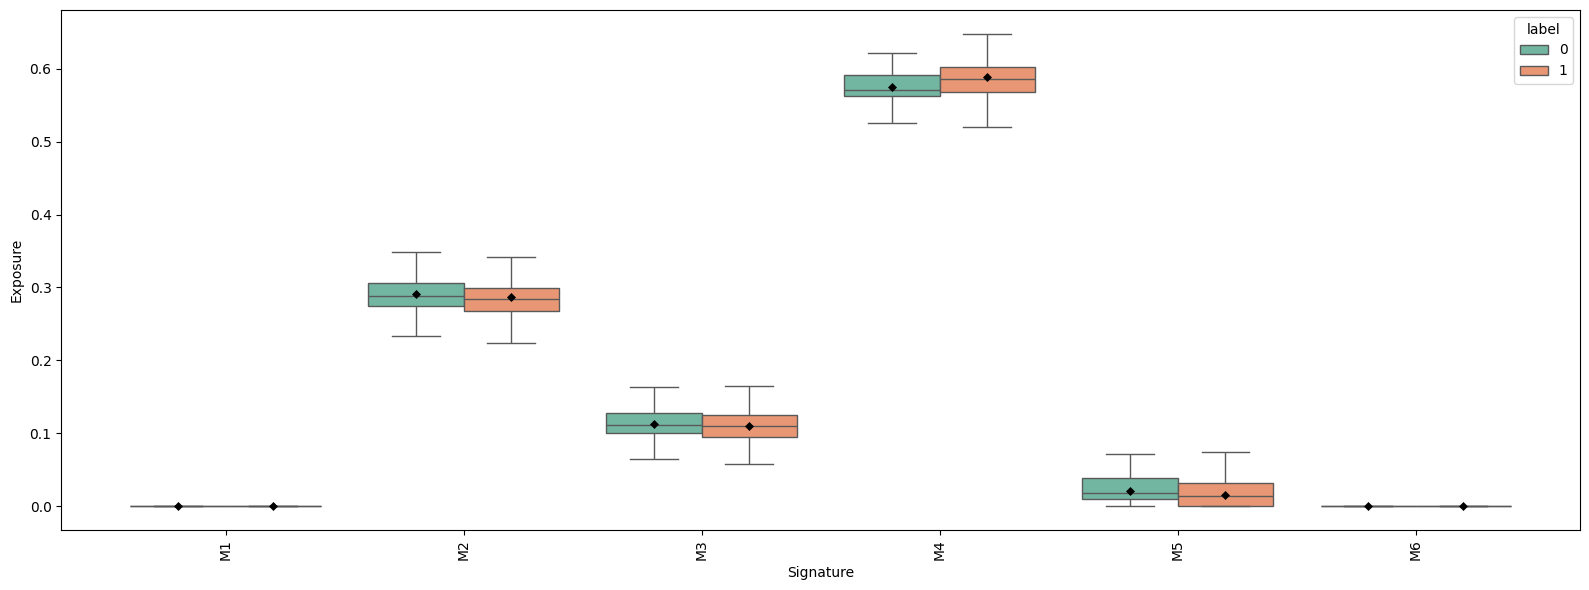




 ###  SA906a  ### 
number of cells: 3711
Cluster B   -1     0     1
Cluster A                 
-1         667  1145    74
 0         101    50  1055
 1          54   140     3
 2          16    40     1
 3           7    26     3
 4          18    27     2
 5          18    30     1
 6          31    92     1
 7          21    39     1
 8          12    36     0
cosine similarity siluette score: 0.5703544616699219
Hellinger siluette score: 0.4035557508468628


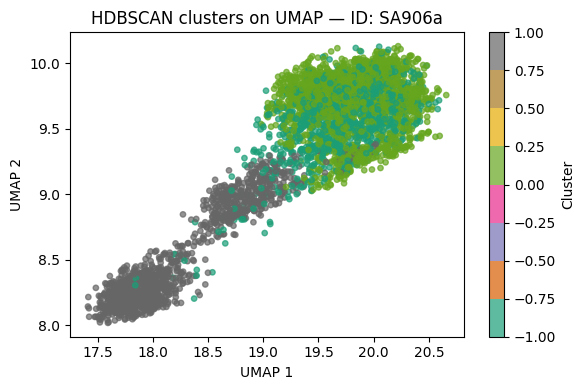

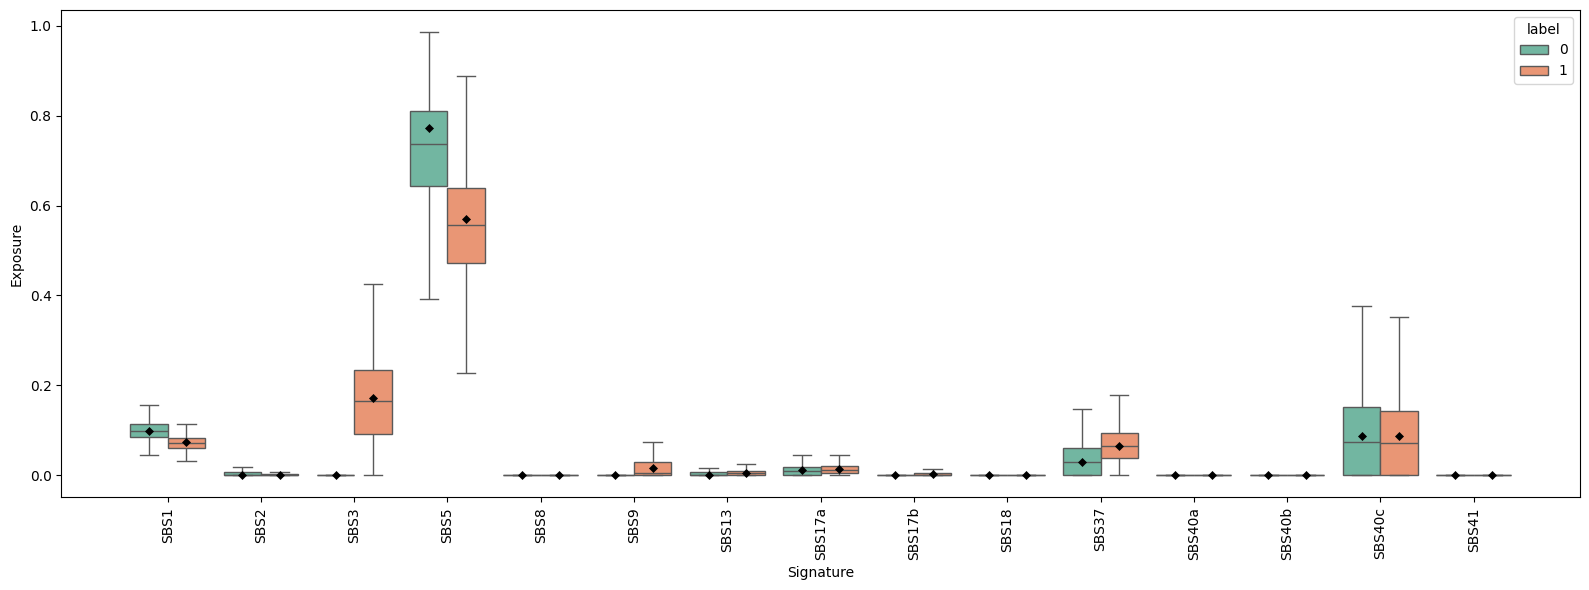

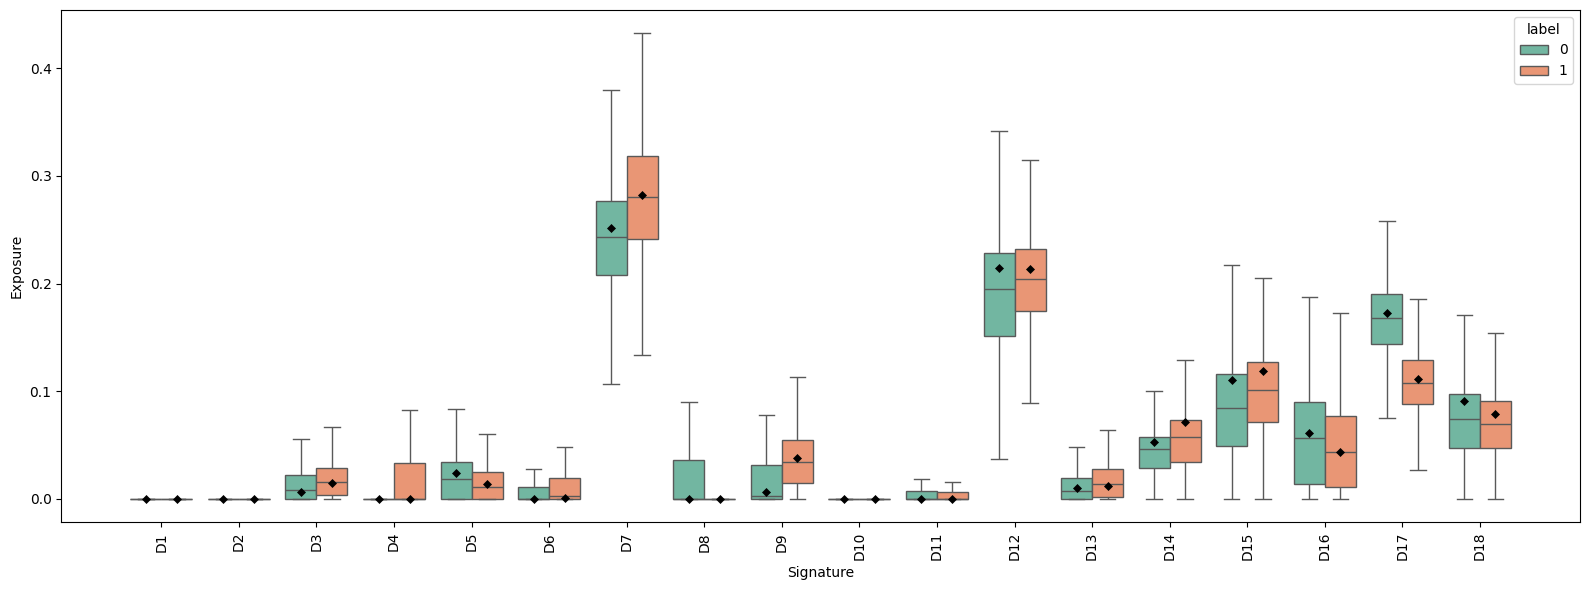

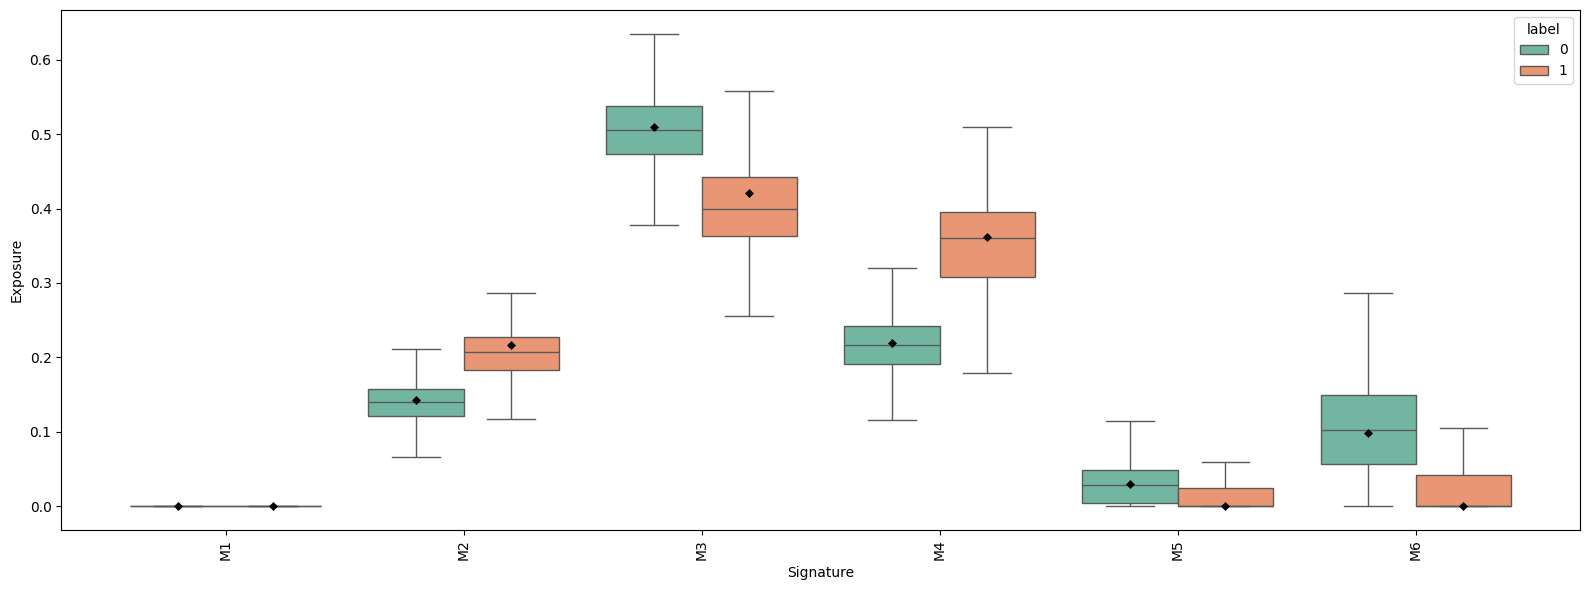




 ###  SA1182  ### 
number of cells: 214
Cluster B   -1
Cluster A     
-1         121
 0          52
 1          41
ERROR for SA1182: Silhouette score requires at least 2 clusters.



 ###  SA501  ### 
number of cells: 2473
Cluster B   -1   0    1    2
Cluster A                   
-1         642  25  442  543
 0          56   1  246    3
 1          41   4   94    2
 2           5  28    0    1
 3          19   0    1  146
 4          10   0    1   33
 5          23   3    1  103
cosine similarity siluette score: 0.32093334197998047
Hellinger siluette score: 0.4266335964202881


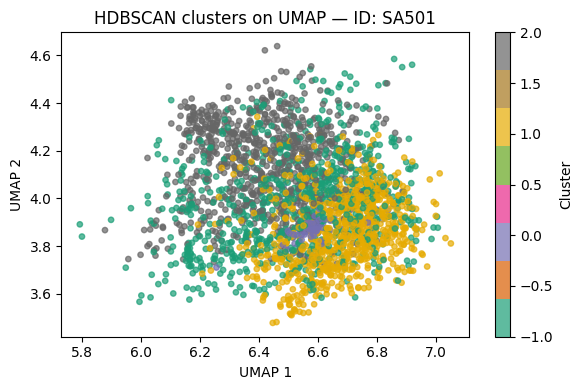

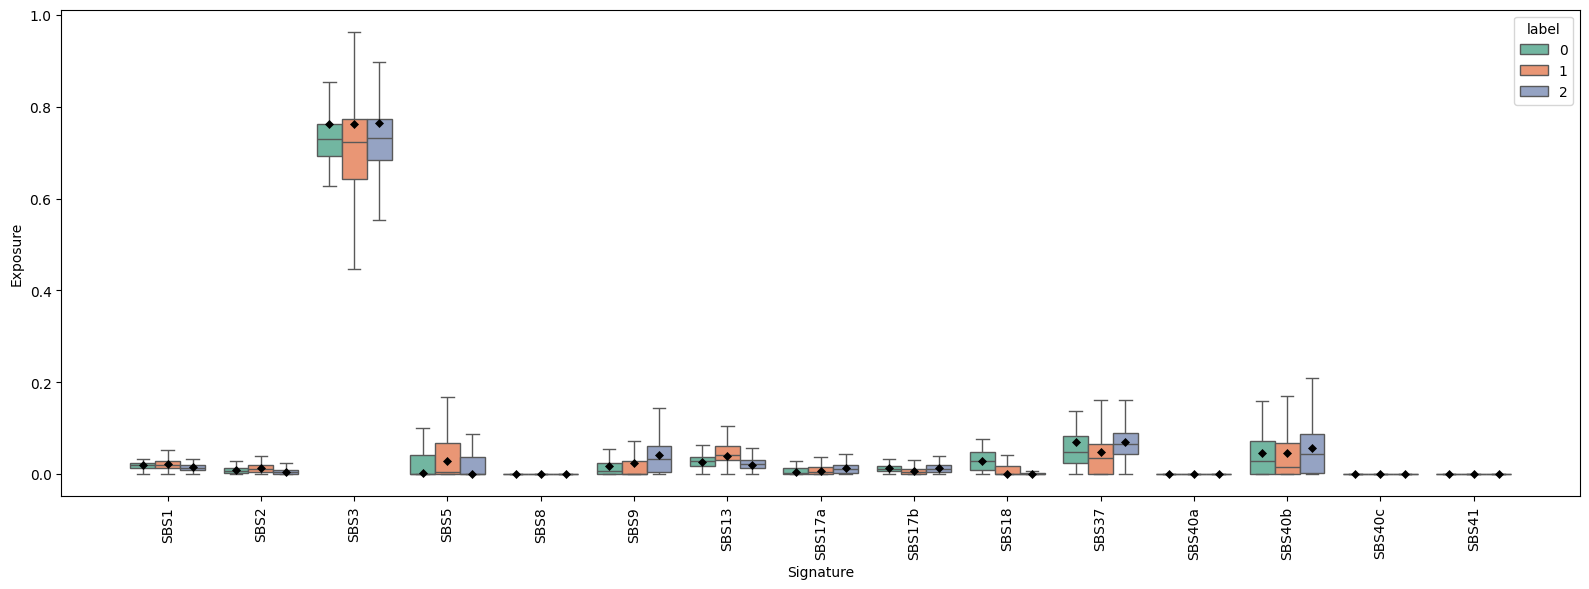

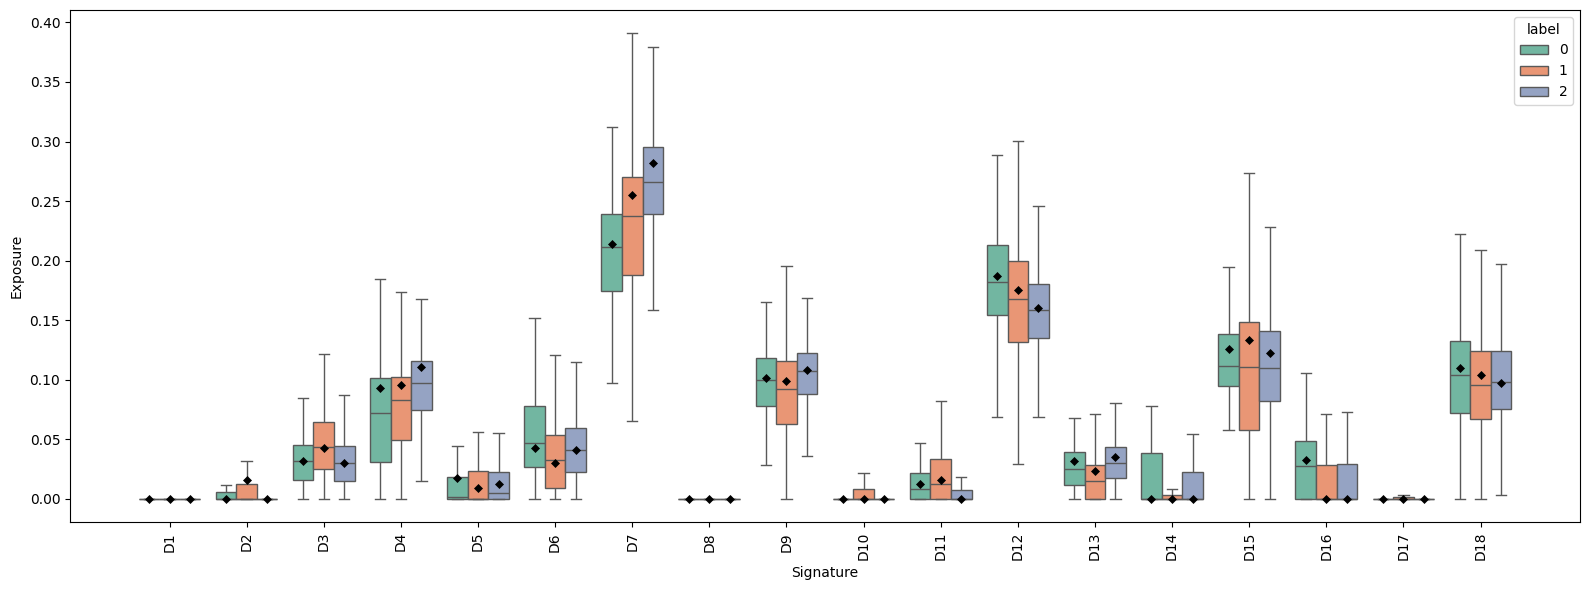

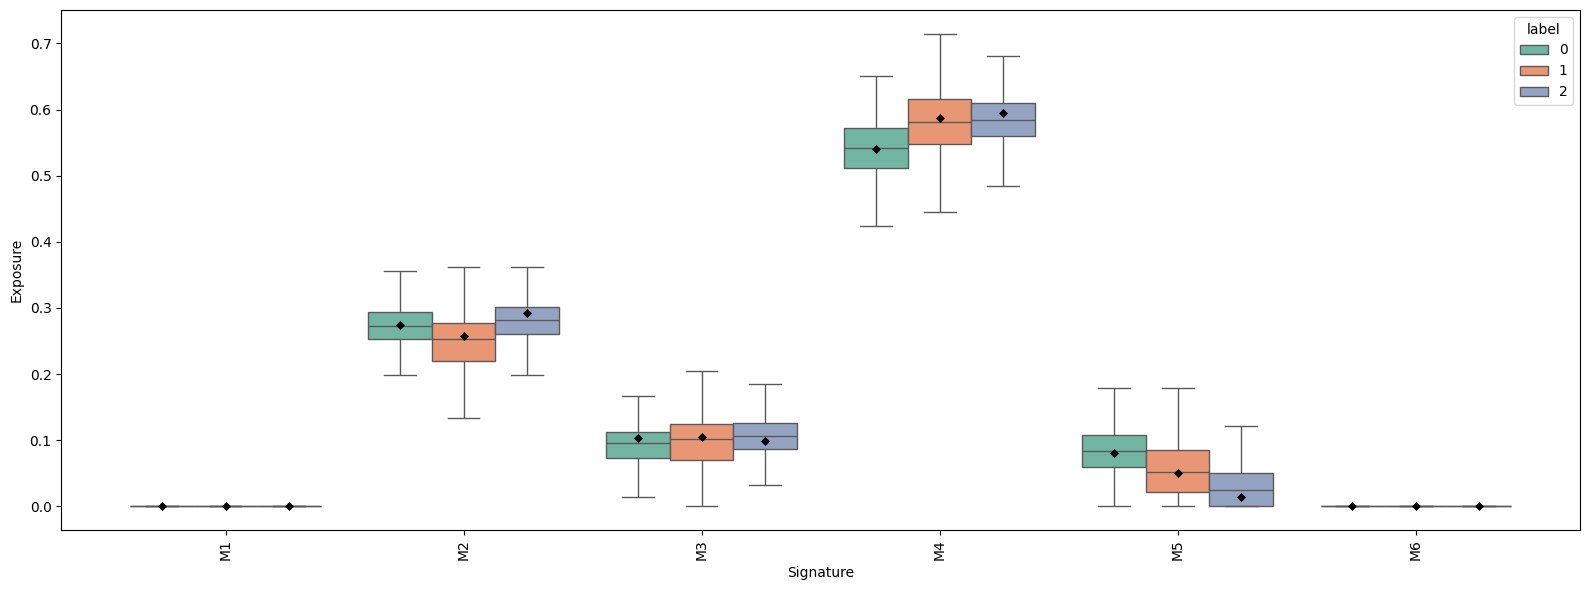




 ###  SA1184  ### 
number of cells: 621
Cluster B   -1   0   1   2
Cluster A                 
-1         137  13  88  50
 0          22   6  21  10
 1         135  13  67  59
cosine similarity siluette score: 0.22993381321430206
Hellinger siluette score: 0.07268481701612473


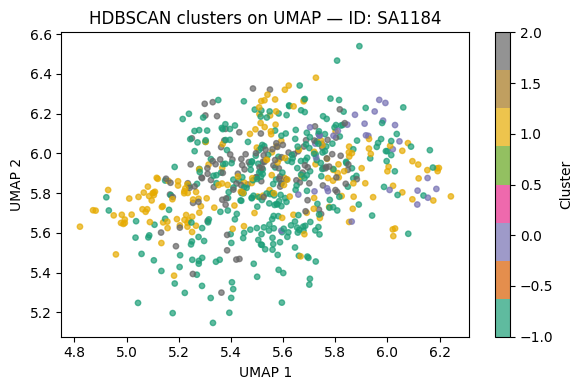

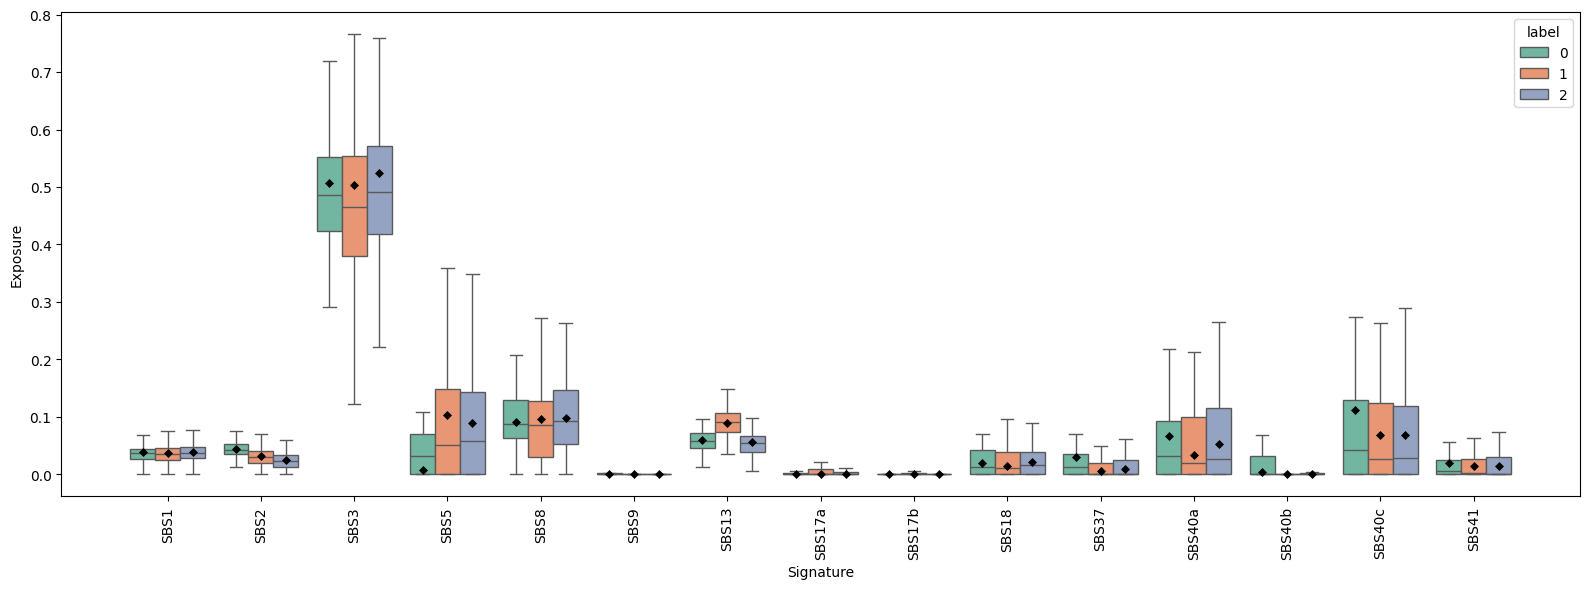

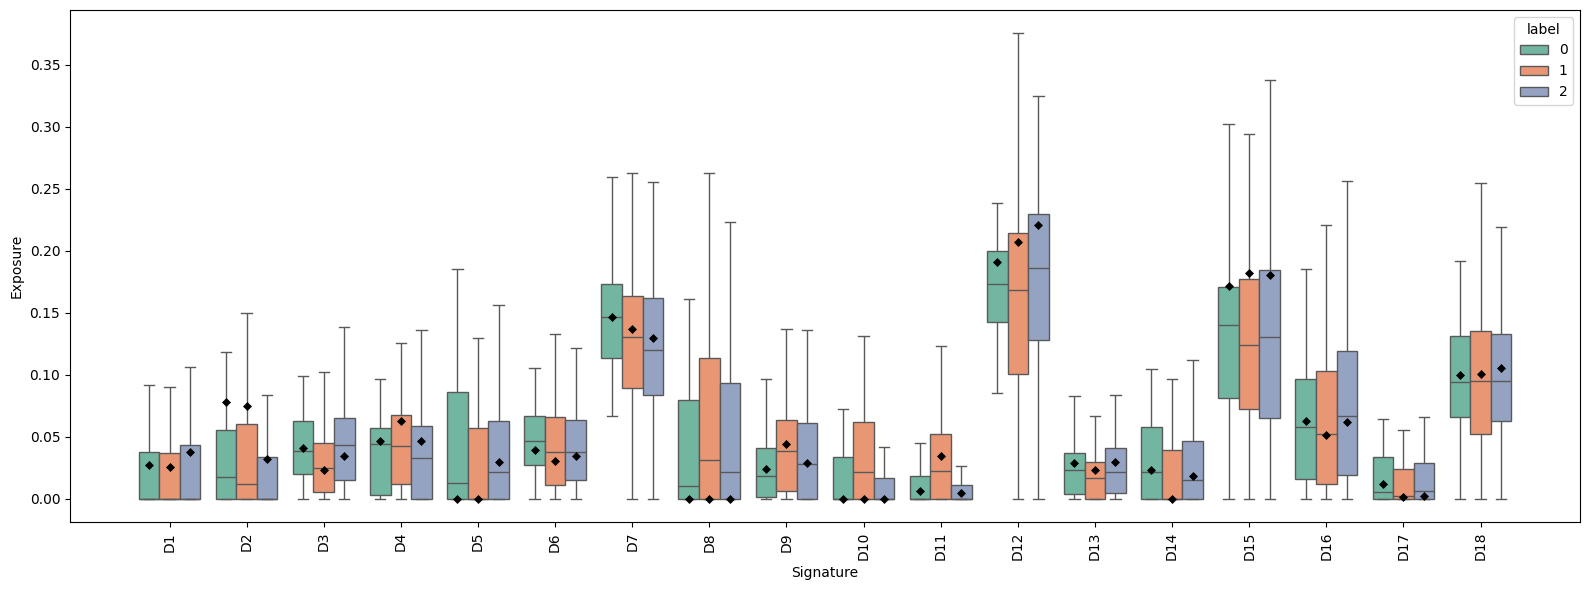

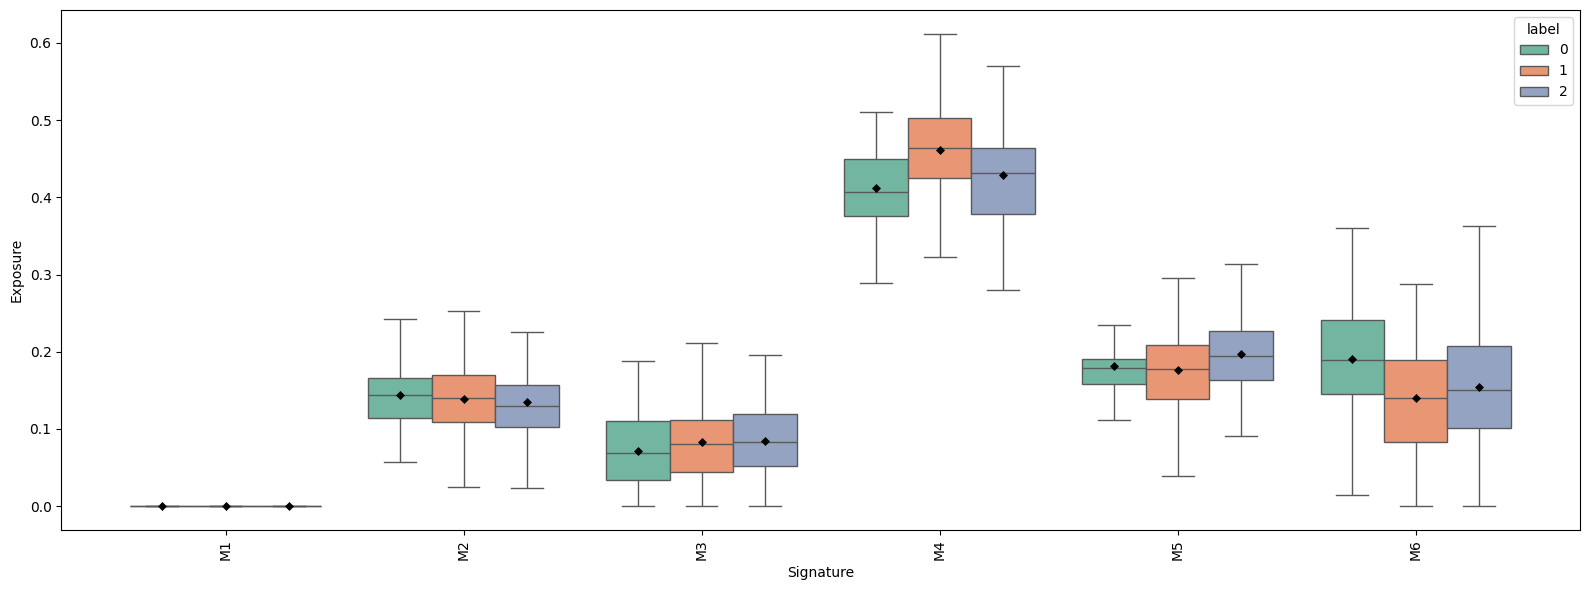




 ###  SA1181  ### 
number of cells: 296
Cluster B   -1   0   1
Cluster A             
-1         133  17  22
 0          20   5   8
 1          21   2  11
 2          42   6   9
cosine similarity siluette score: 0.386303573846817
Hellinger siluette score: 0.1937580108642578


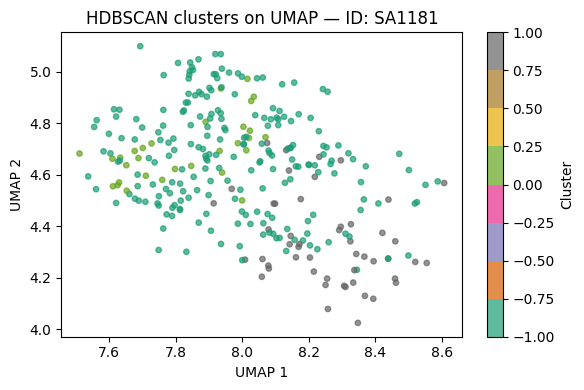

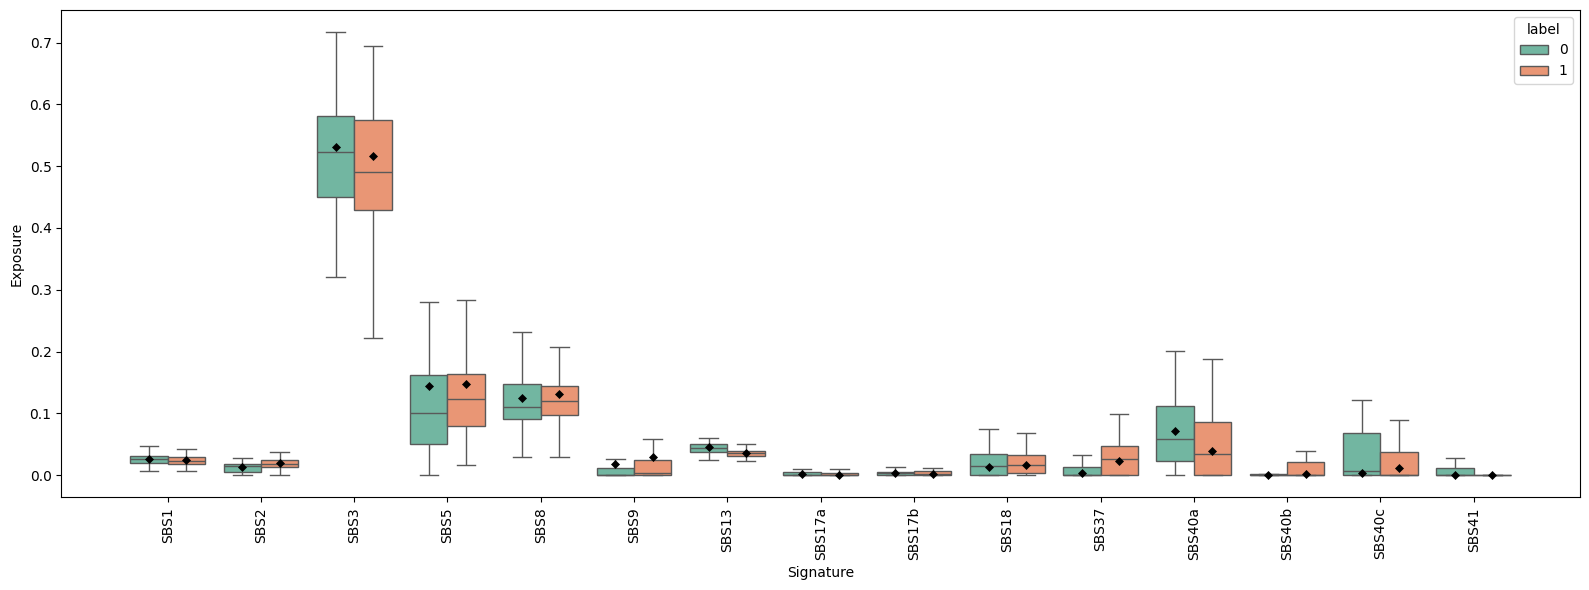

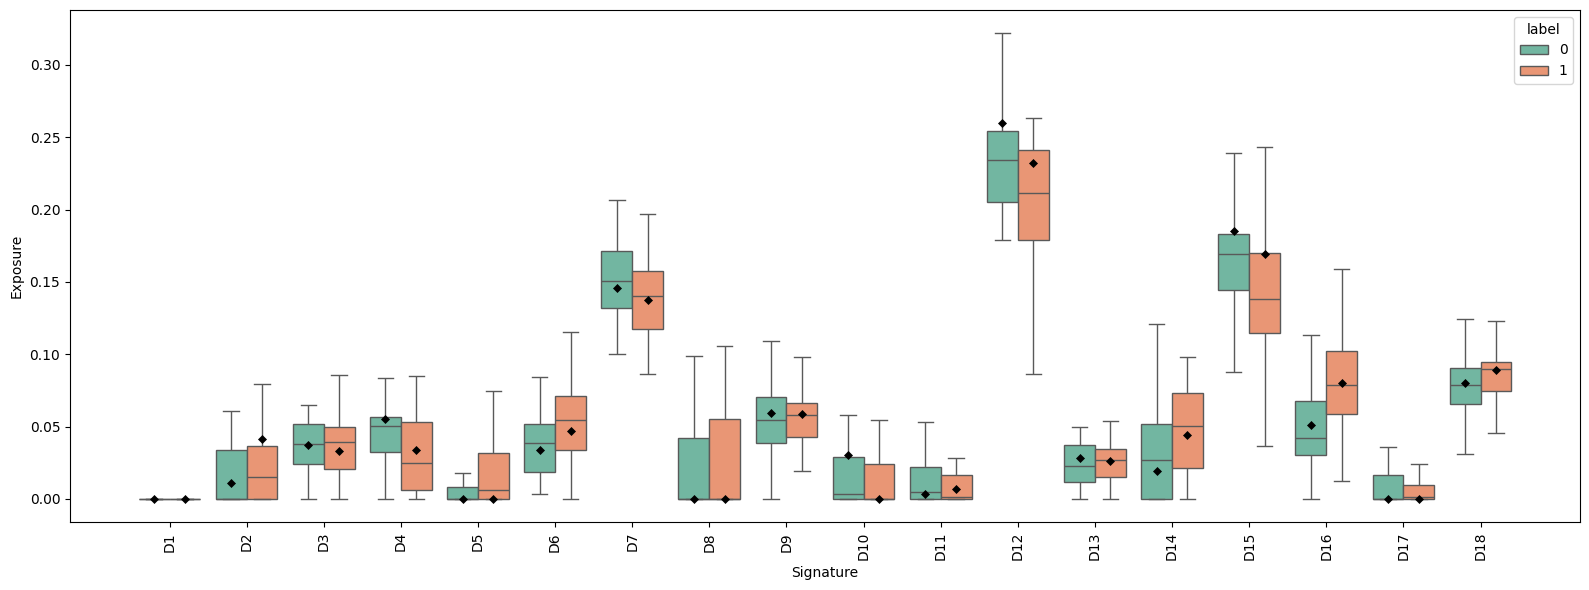

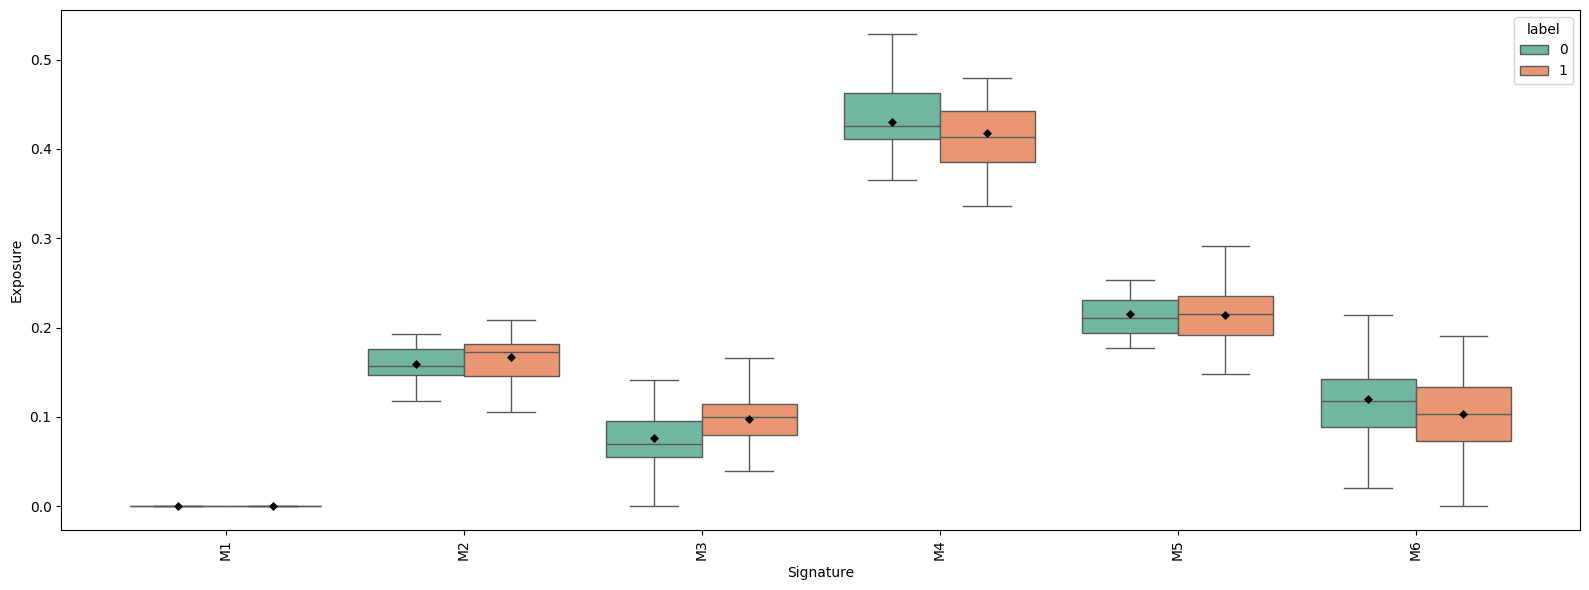




 ###  SA906b  ### 
number of cells: 5716
Cluster B     0     1
Cluster A            
0           146  3109
1          2410    51
cosine similarity siluette score: 0.803070604801178
Hellinger siluette score: 0.8698177933692932


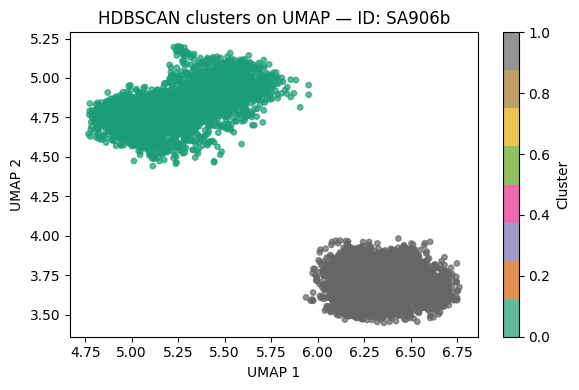

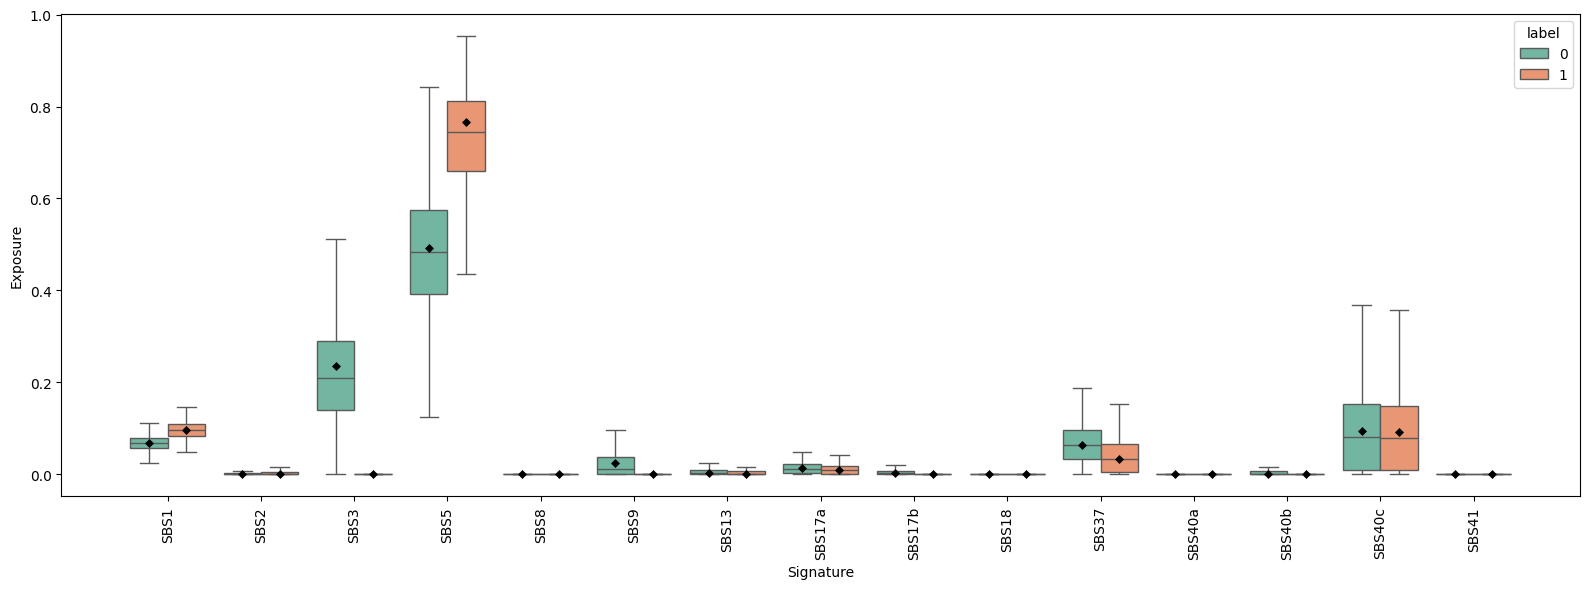

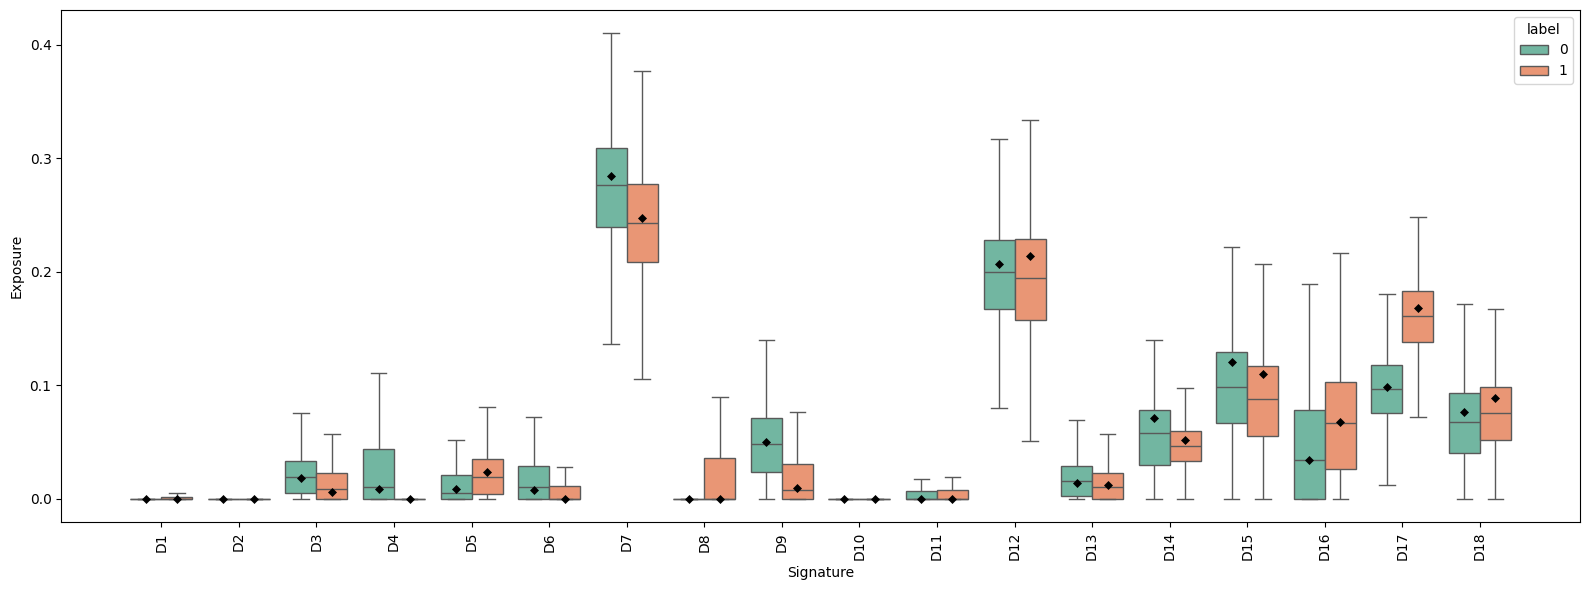

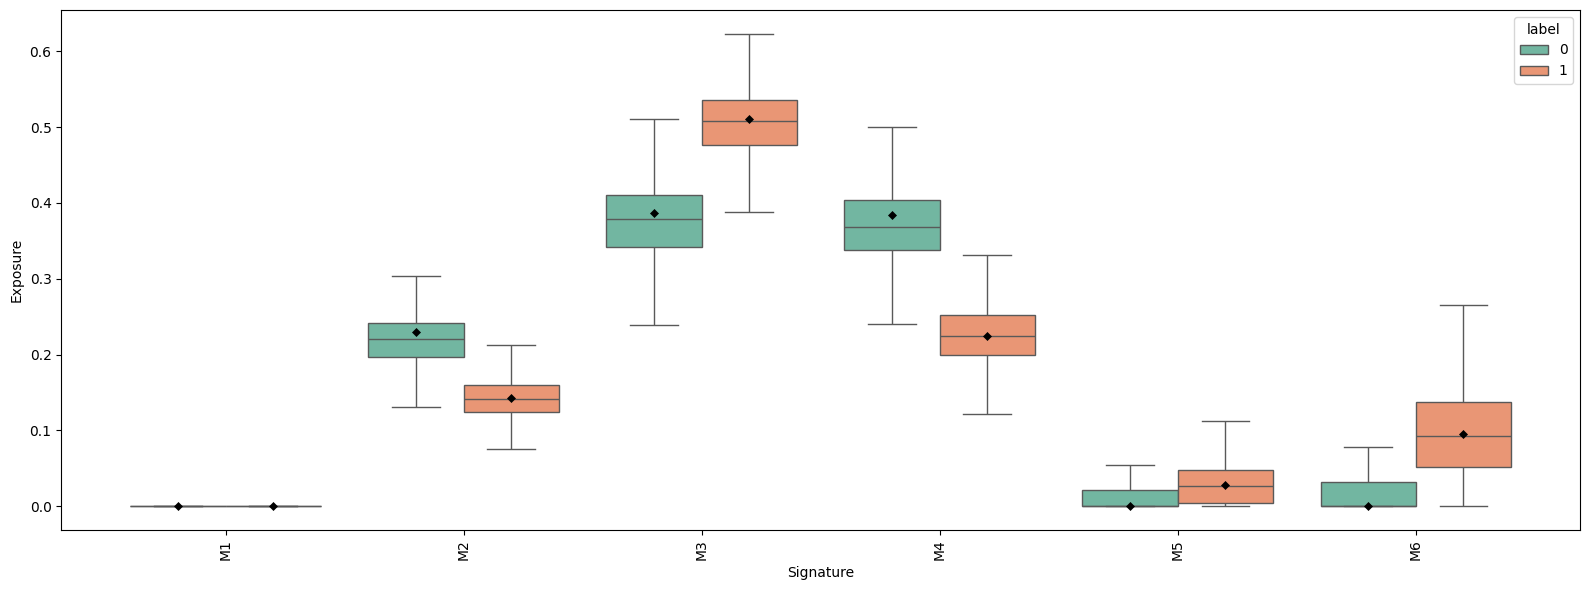




 ###  DG1197  ### 
number of cells: 77
Cluster B  -1
Cluster A    
-1         77
ERROR for DG1197: Silhouette score requires at least 2 clusters.



 ###  SA1162  ### 
number of cells: 254
Cluster B    0   1
Cluster A         
0           12  55
1          185   2
cosine similarity siluette score: 0.8110373616218567
Hellinger siluette score: 0.9290040731430054


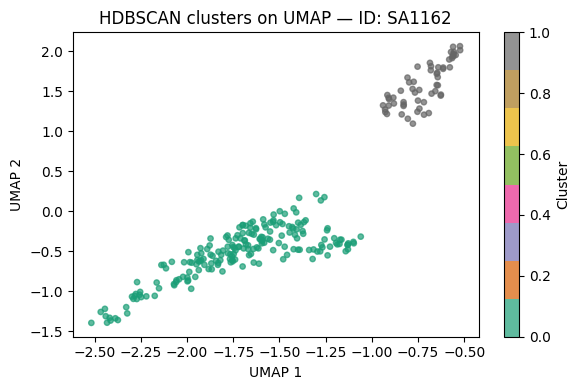

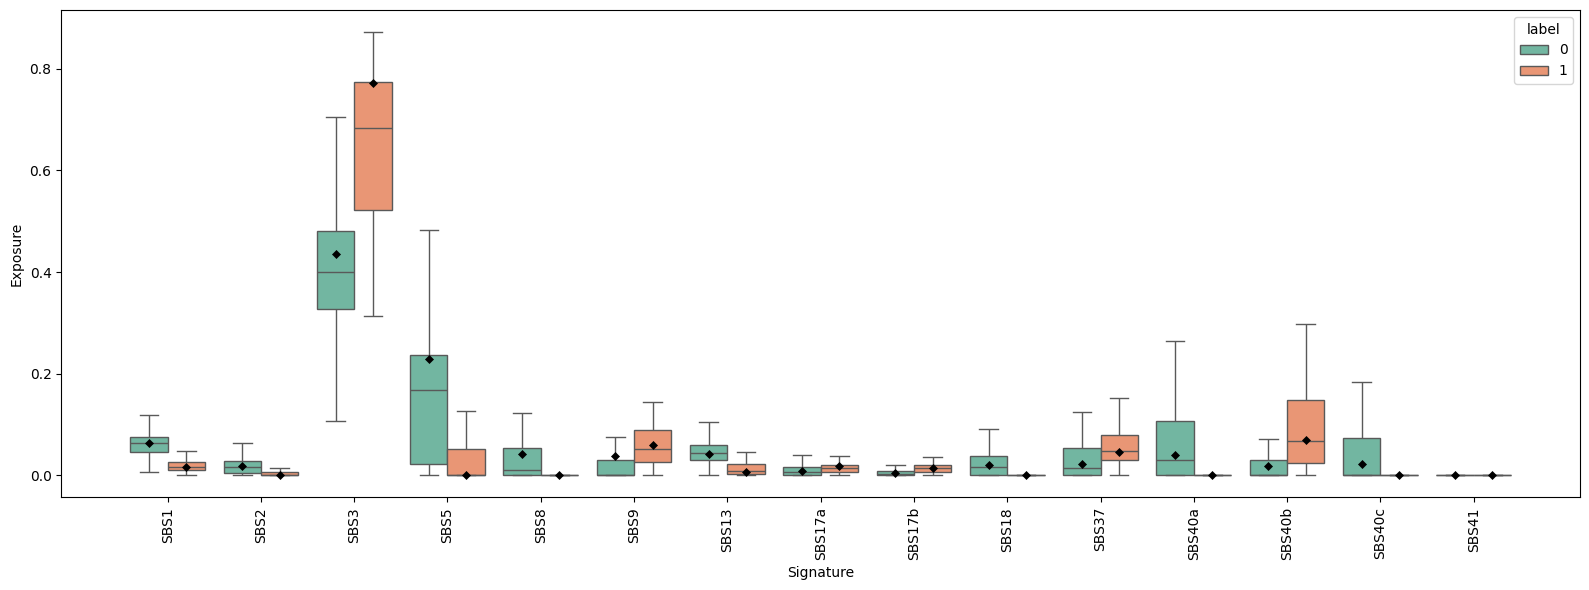

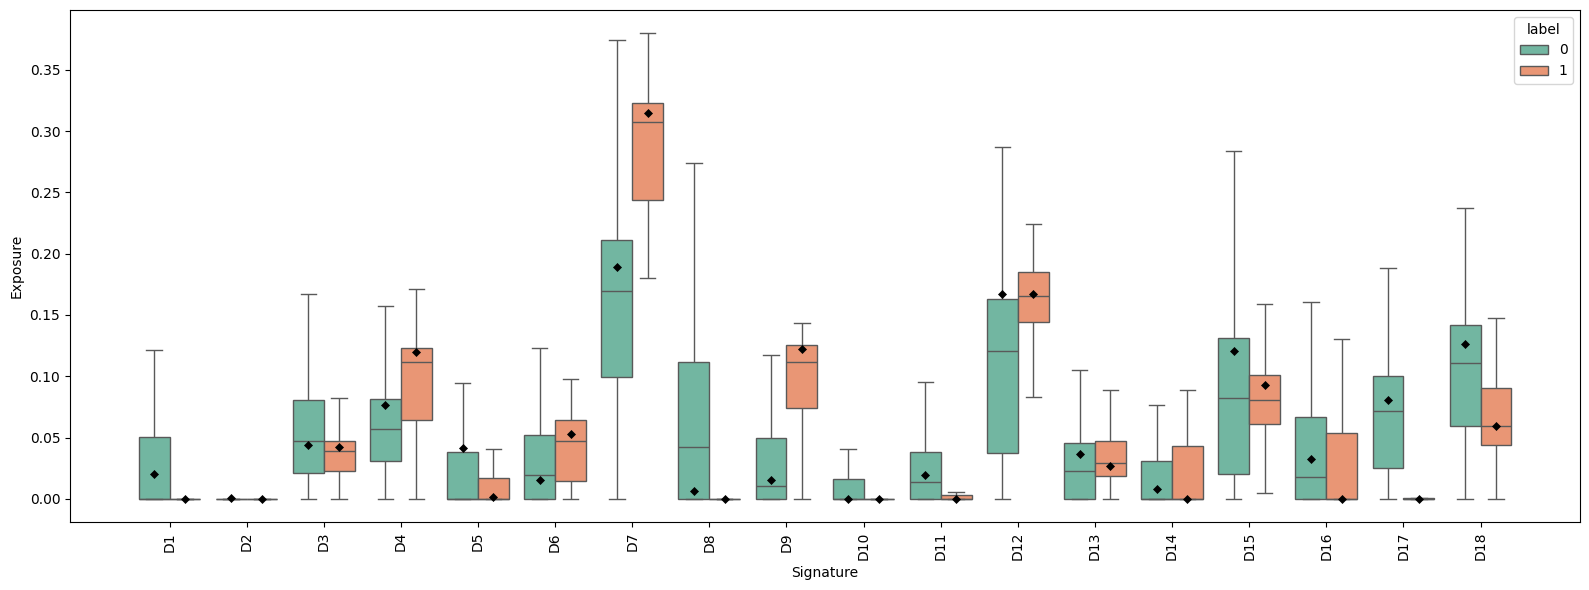

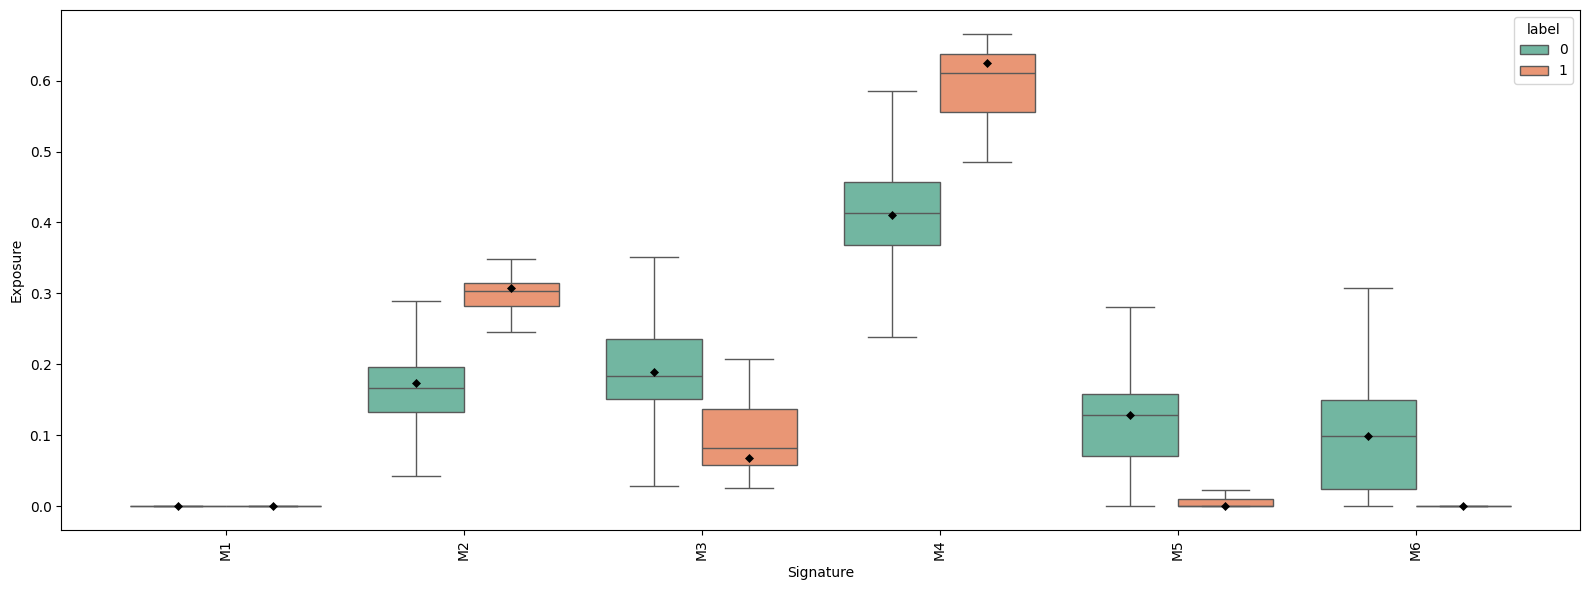




 ###  SA1188  ### 
number of cells: 2003
Cluster B   -1   0    1   2   3   4
Cluster A                          
-1         773  18  289  21  53  48
 0          23   0    6   0   0   1
 1          17   0    7   1   2   3
 2         181  15   15   6  39  40
 3          35   0   14   0   0   0
 4          33   0    3   3   1   3
 5          22   0    5   2   1   0
 6          22   0    9   0   2   1
 7          22   1   13   0   0   0
 8         133   0  116   2   1   1
cosine similarity siluette score: 0.21155764162540436
Hellinger siluette score: 0.1456986963748932


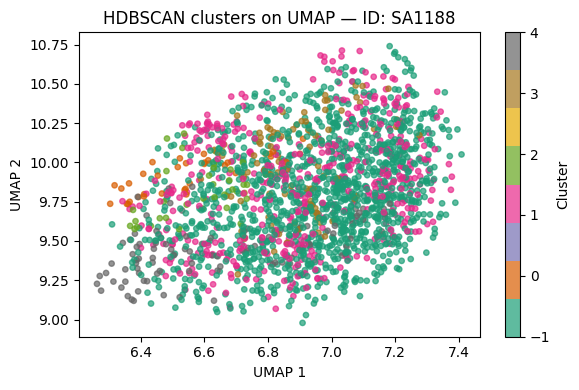

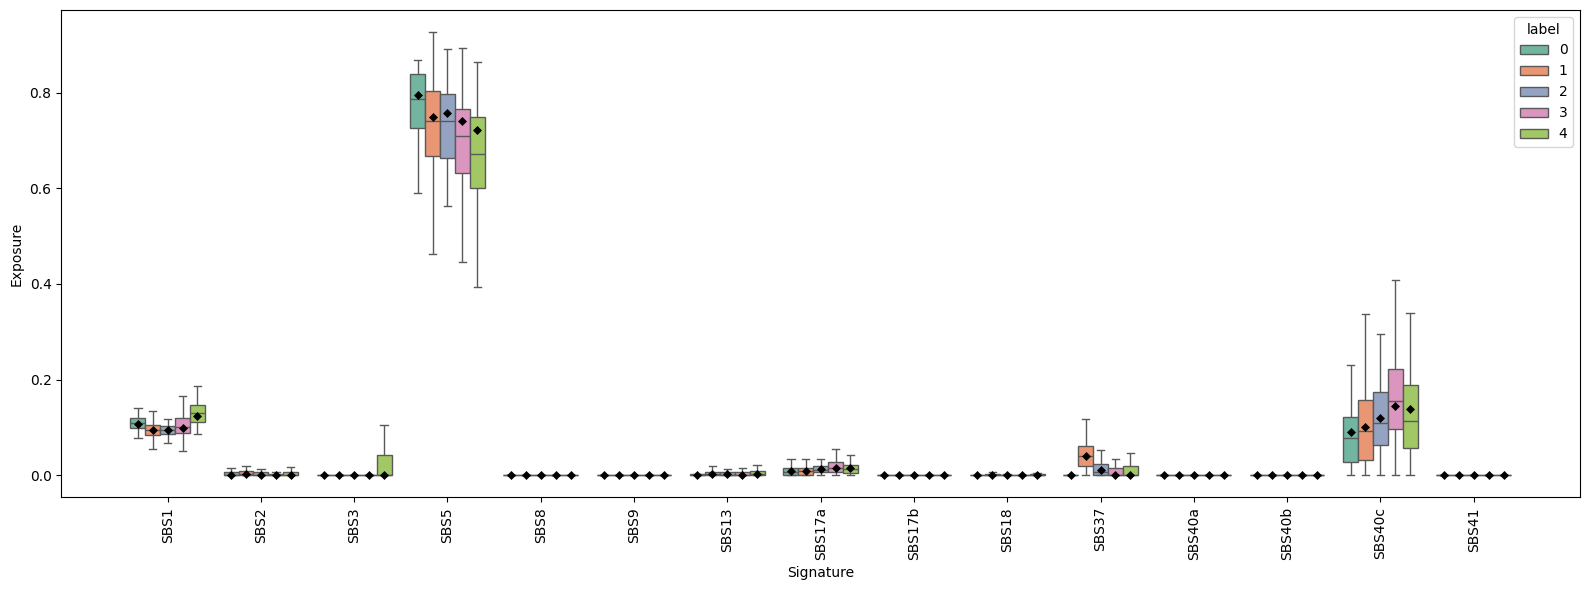

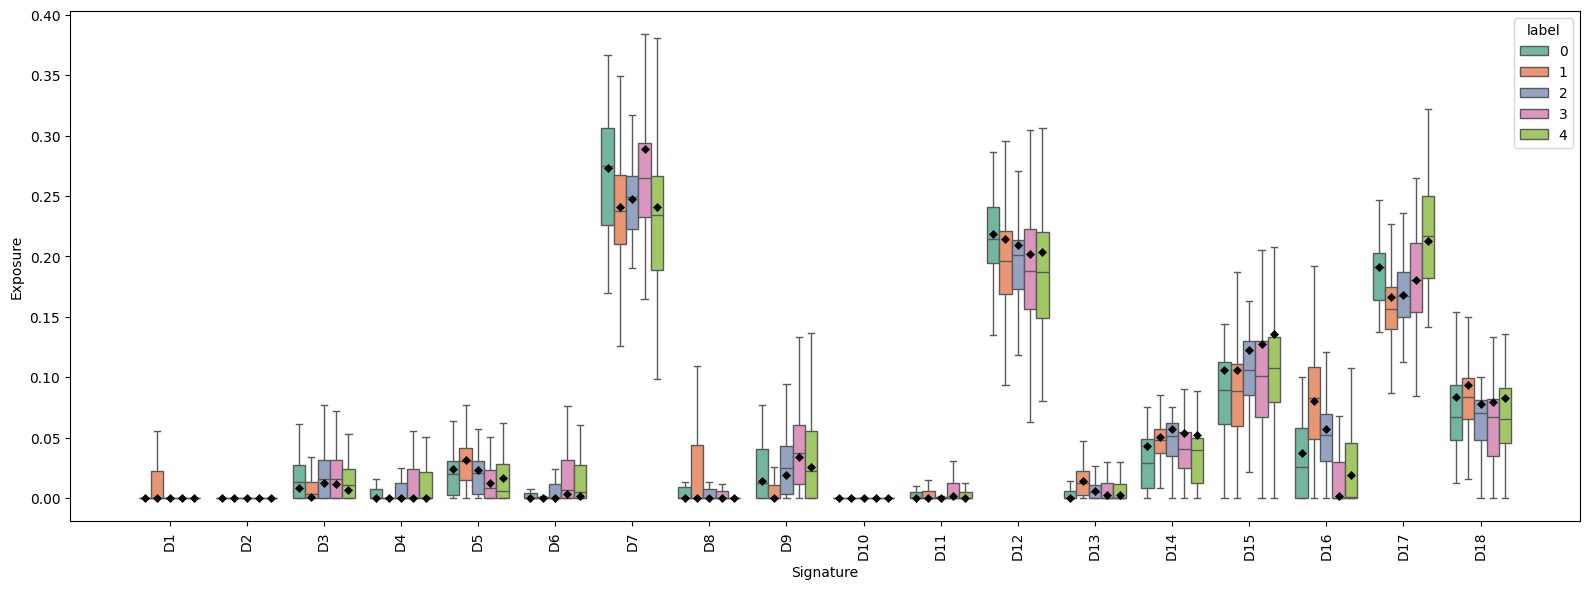

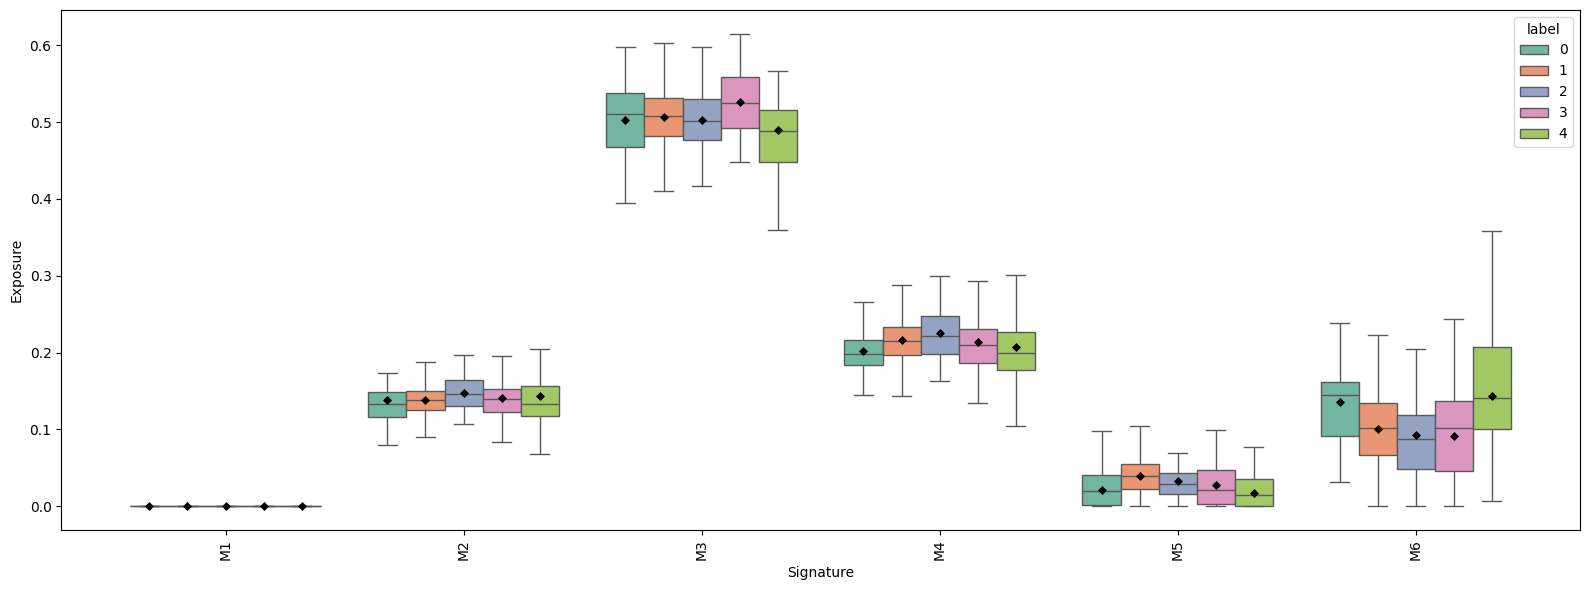




 ###  SA1096  ### 
number of cells: 802
Cluster B    0    1
Cluster A          
0          262    0
1            1  539
cosine similarity siluette score: 0.9354193210601807
Hellinger siluette score: 0.9471142292022705


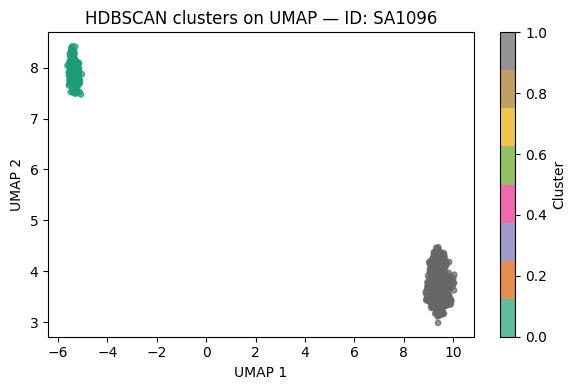

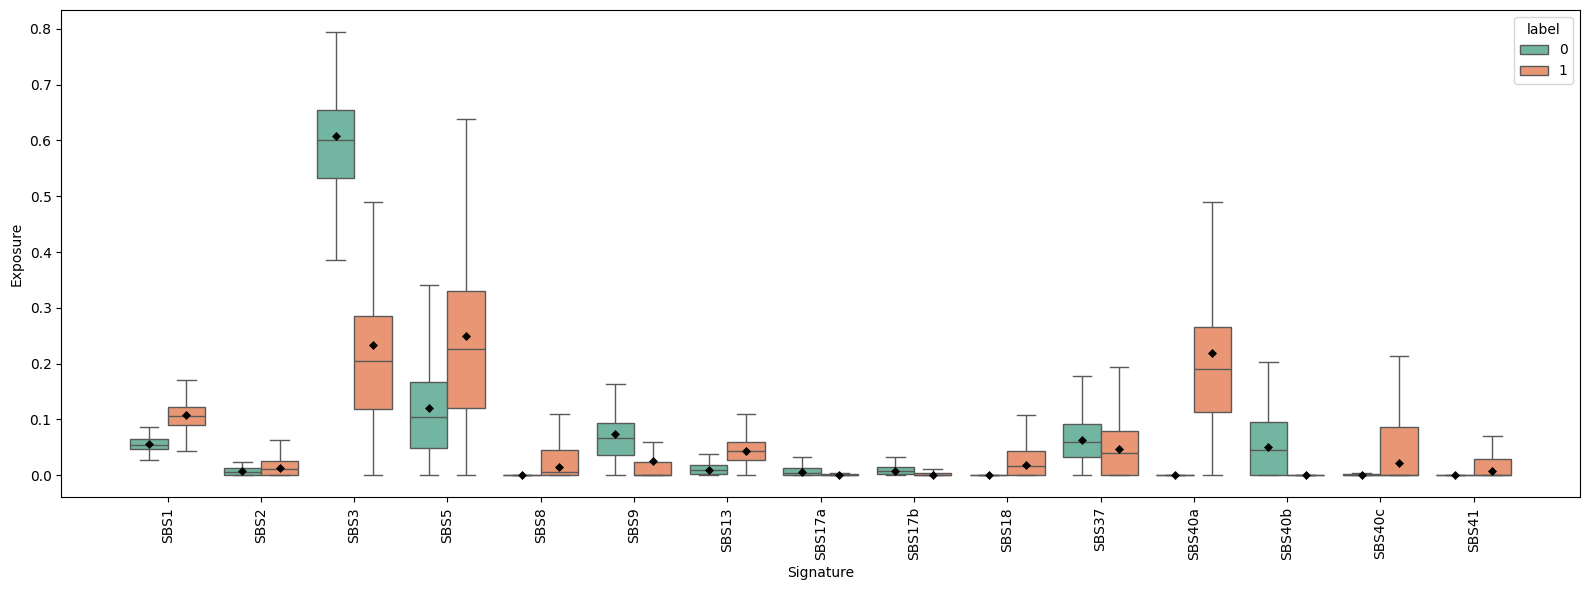

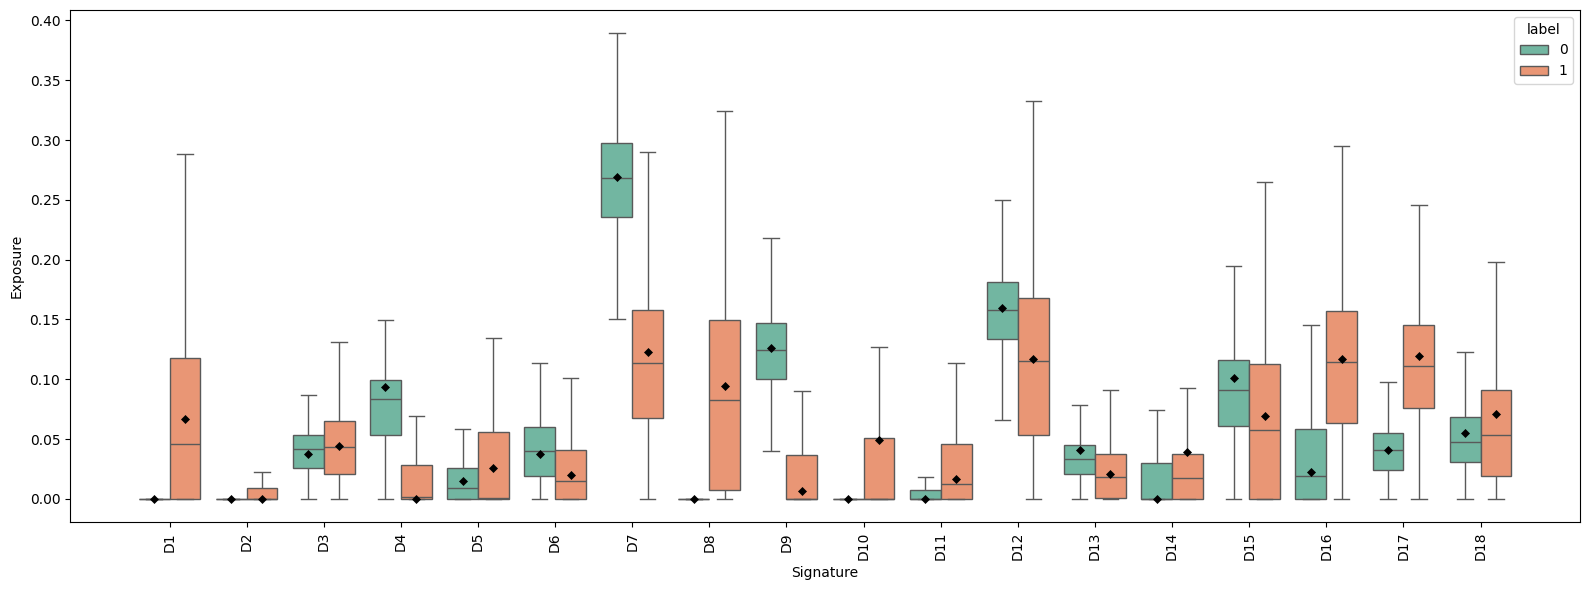

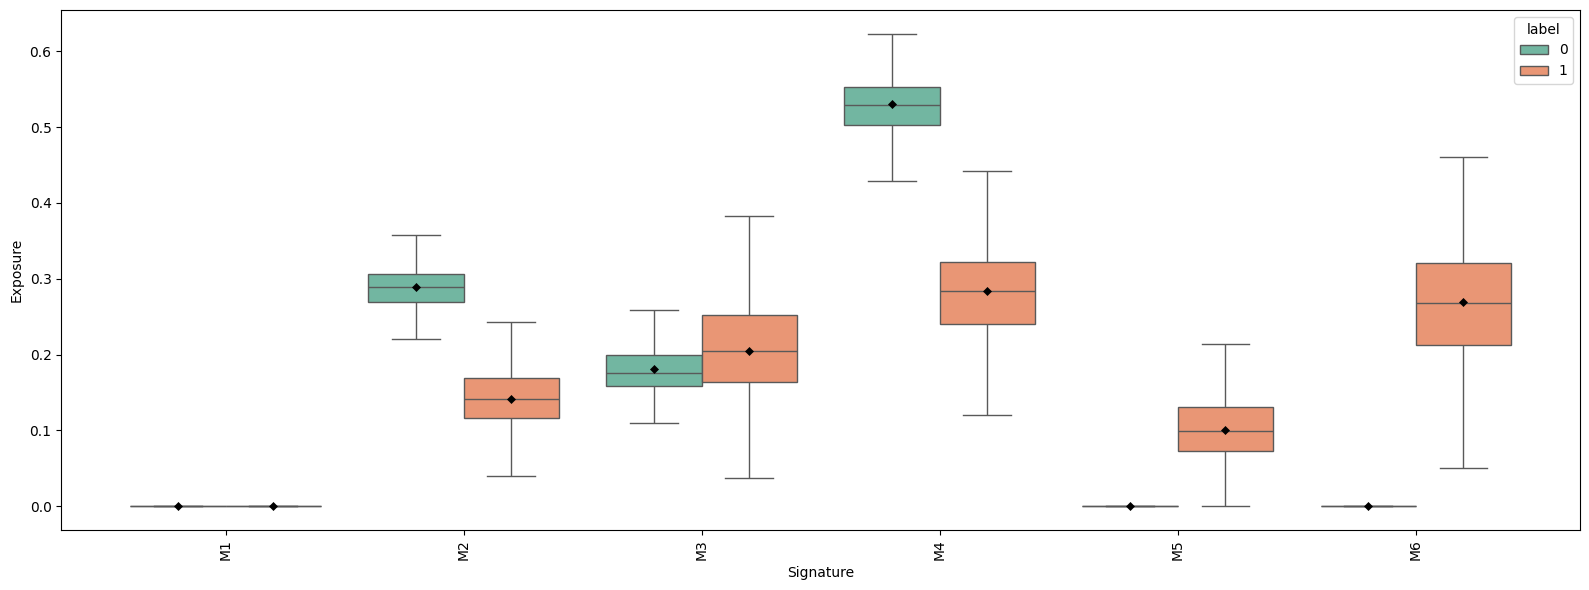




 ###  SA1180  ### 
number of cells: 774
Cluster B   -1   0    1
Cluster A              
-1         186  19  229
 0          39   8   64
 1           9   2   23
 2          31   2   62
 3          17   0   38
 4          13   0   32
cosine similarity siluette score: 0.03309236466884613
Hellinger siluette score: 0.175510436296463


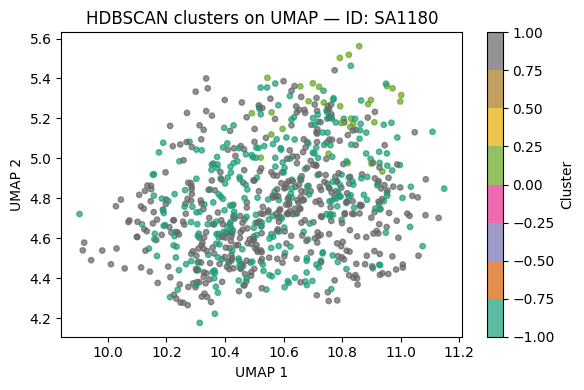

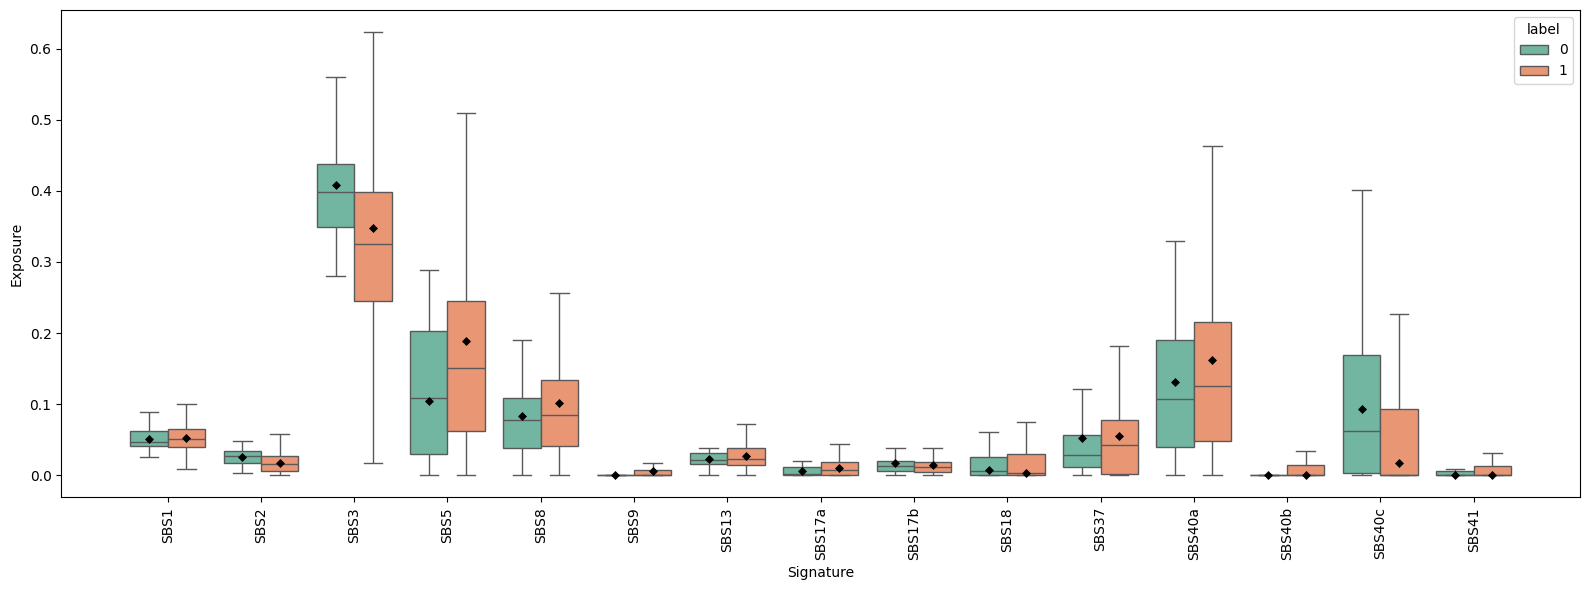

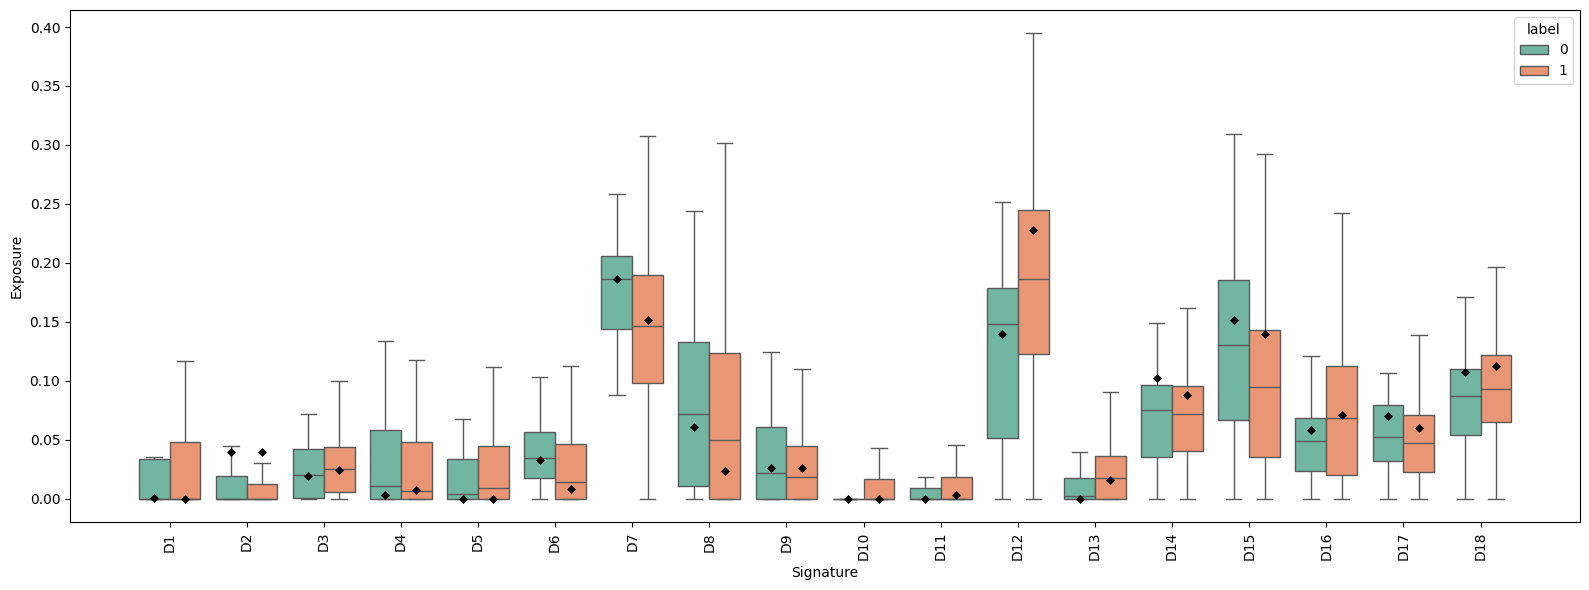

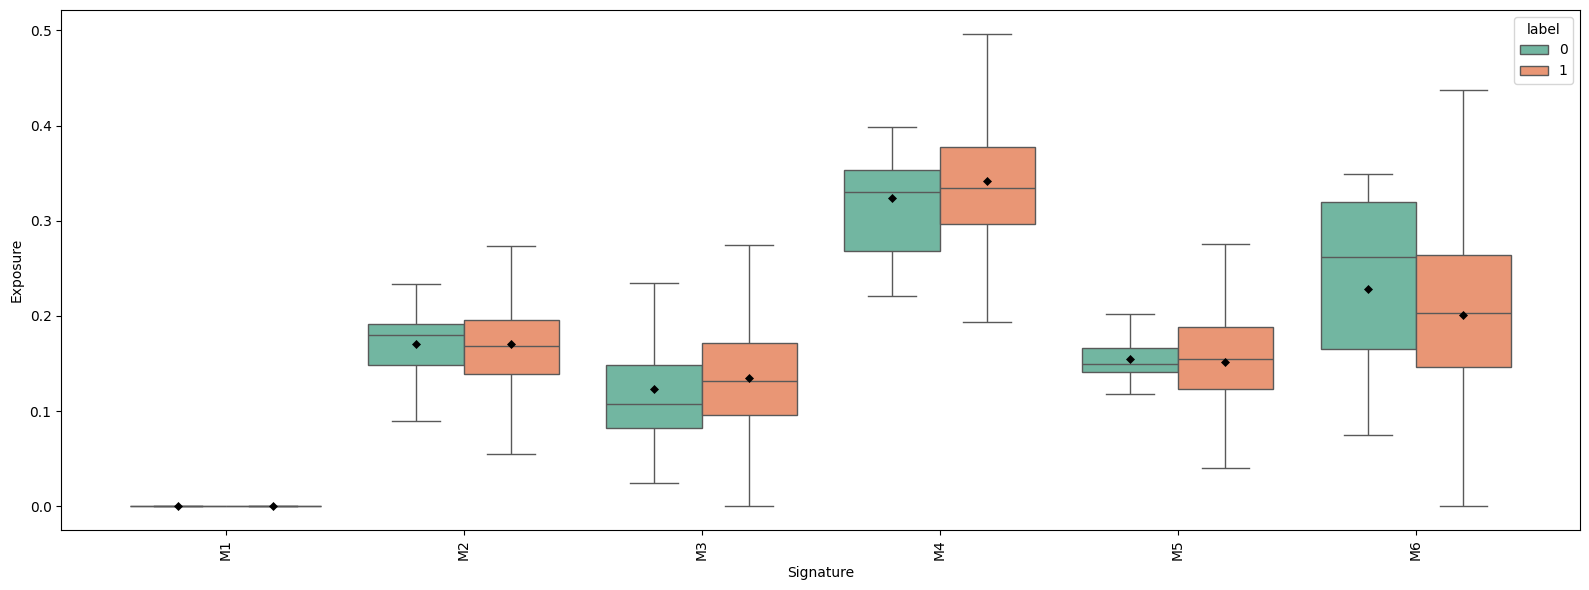




 ###  SA1091  ### 
number of cells: 506
Cluster B   -1   0    1
Cluster A              
-1         108  53  133
 0          16   4   11
 1          18  10   30
 2          38  28   57
cosine similarity siluette score: 0.1530228853225708
Hellinger siluette score: 0.12592986226081848


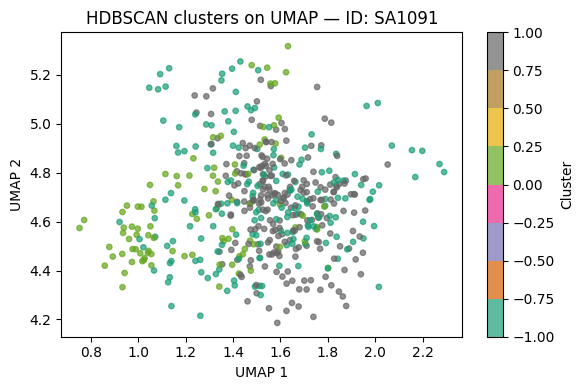

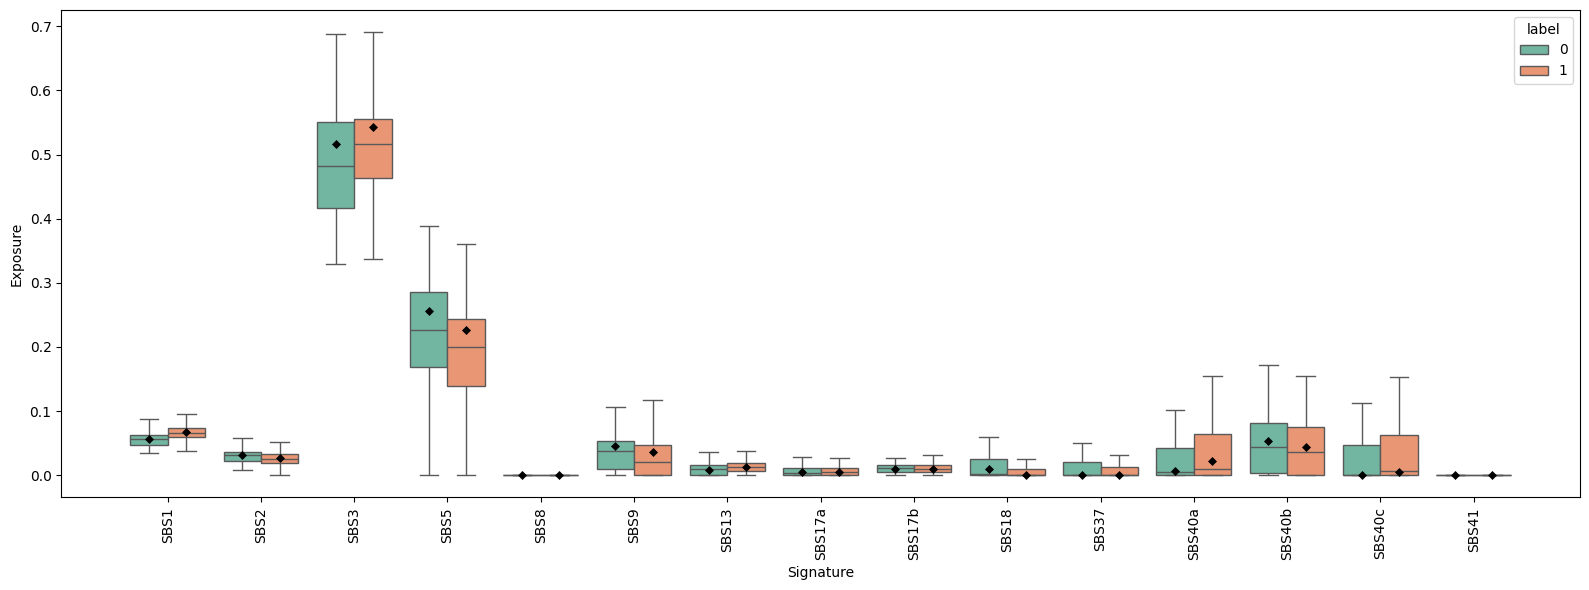

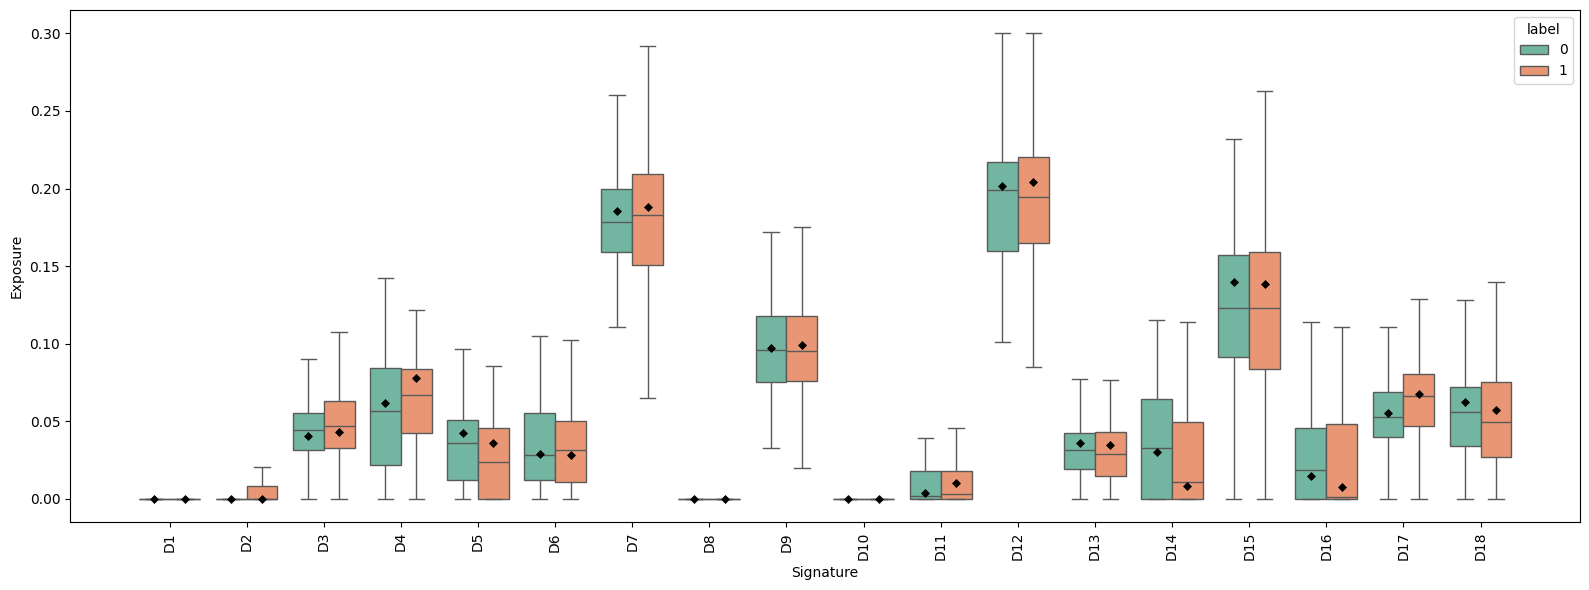

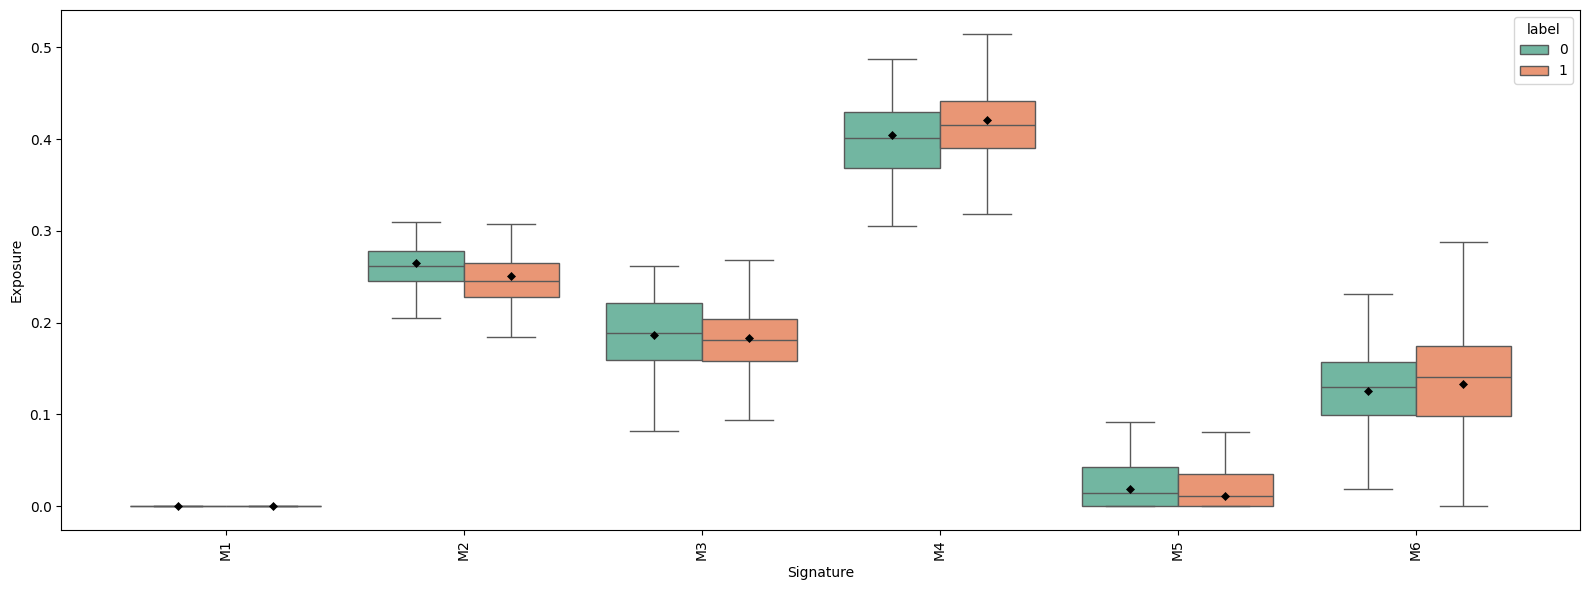

In [10]:
for key in P.keys():
    try:
        y = P[key]

        print(' ### ', key, ' ### ')
        print('number of cells:', y.nrows)
        print(crosstable(y.umap(metric='hellinger').hdbscan().get_labels(), y.umap().hdbscan().get_labels()))
        print('cosine similarity siluette score:', y.umap().hdbscan().silhouette_score())
        print('Hellinger siluette score:', y.umap(metric='hellinger').hdbscan().silhouette_score())
        y.umap().hdbscan().plot_clustering()
        y.umap().hdbscan().plot_deconv(signatures=cosmic.loc[breast_sigs])
        y.umap().hdbscan().plot_deconv(signatures=dmg_sig)
        y.umap().hdbscan().plot_deconv(signatures=misr_sig)
    except Exception as e:
        print(f'ERROR for {key}: {e}')
        continue
    finally:
        print('\n\n')